In [131]:
import pandas as pd
import numpy as np

tickets_path = "../Raw data/support_tickets_10k.csv"
faq_path = "../Raw data/faq_knowledge_base_150.csv"

tickets = pd.read_csv(tickets_path)
faq = pd.read_csv(faq_path)

print("Support Tickets:")
print(tickets.shape)

print("\nFAQ Knowledge Base:")
print(faq.shape)

Support Tickets:
(10000, 15)

FAQ Knowledge Base:
(150, 4)


In [132]:
print("TICKETS COLUMNS")
print(tickets.columns.tolist())

print("\nFAQ COLUMNS")
print(faq.columns.tolist())

TICKETS COLUMNS
['ticket_id', 'created_date', 'ticket_text', 'product_name', 'product_segment', 'ticket_category', 'priority', 'sentiment', 'confidence_score', 'escalated', 'resolution_text', 'resolved_date', 'resolution_days', 'auto_resolved', 'customer_satisfaction_score']

FAQ COLUMNS
['faq_id', 'question', 'answer', 'category']


In [133]:
display(tickets.head())
display(faq.head())

,ticket_id,created_date,ticket_text,product_name,product_segment,ticket_category,priority,sentiment,confidence_score,escalated,resolution_text,resolved_date,resolution_days,auto_resolved,customer_satisfaction_score
0,TKT100000,2023-08-12,The lipstick I received in order #ORD5614226 stopped working after just 5 days of use.,lipstick,Beauty & Personal Care,Product Issue,High,Negative,0.66,Yes,Full refund processed. Seller account flagged for quality investigation.,2023-08-14,2,No,1
1,TKT100001,2023-12-11,The shoe rack received in order #ORD8038374 has scratches and dents. Looks like a returned/used item.,shoe rack,Home & Kitchen,Product Issue,High,Negative,0.74,Yes,Missing accessory shipped separately at no additional cost.,2023-12-12,1,No,1
2,TKT100002,2024-01-06,I want to exchange my conditioner (order #ORD6770619) for a different size. Exchange option is missing.,conditioner,Beauty & Personal Care,Refund & Return,Low,Positive,0.93,No,Accidental order refund approved. Amount credited within 2 days.,2024-01-16,10,Yes,4
3,TKT100003,2024-11-17,My makeup brush set from order #ORD4823498 appears to be counterfeit/fake. Not the original brand.,makeup brush set,Beauty & Personal Care,Product Issue,High,Very Negative,0.78,Yes,Missing accessory shipped separately at no additional cost.,2024-11-20,3,No,1
4,TKT100004,2023-08-23,Product listing for lipstick is completely misleading. The actual product is nothing like the photos.,lipstick,Beauty & Personal Care,Product Issue,Medium,Neutral,0.94,No,Replacement lipstick dispatched after quality team verification.,2023-08-24,1,No,4


,faq_id,question,answer,category
0,FAQ001,How do I track my order?,Go to My Orders > Select Order > Track Package for real-time courier updates.,Delivery Issue
1,FAQ002,What should I do if my order is delayed?,"Check tracking first. If no update for 48 hours, raise a complaint via My Orders > Help.",Delivery Issue
2,FAQ003,Can I change my delivery address after placing an order?,"Yes, before dispatch. Go to My Orders > Order Details > Edit Address.",Delivery Issue
3,FAQ004,What happens if I miss my delivery?,Courier will reattempt delivery. You can also reschedule via the tracking link.,Delivery Issue
4,FAQ005,How do I reschedule my delivery?,Use the tracking link in your SMS/email to select a new delivery slot.,Delivery Issue


In [134]:
print("TICKET DATA TYPES")
tickets.info()

print("\nFAQ DATA TYPES")
faq.info()

TICKET DATA TYPES
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 15 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ticket_id                    10000 non-null  str    
 1   created_date                 10000 non-null  str    
 2   ticket_text                  10000 non-null  str    
 3   product_name                 10000 non-null  str    
 4   product_segment              10000 non-null  str    
 5   ticket_category              10000 non-null  str    
 6   priority                     10000 non-null  str    
 7   sentiment                    10000 non-null  str    
 8   confidence_score             10000 non-null  float64
 9   escalated                    10000 non-null  str    
 10  resolution_text              10000 non-null  str    
 11  resolved_date                10000 non-null  str    
 12  resolution_days              10000 non-null  int64  
 13  auto_resol

In [135]:
# Cell 1 — Missing values
print("=== SUPPORT TICKETS: MISSING VALUES ===")
print(tickets.isnull().sum())

print("\n=== FAQ: MISSING VALUES ===")
print(faq.isnull().sum())

=== SUPPORT TICKETS: MISSING VALUES ===
ticket_id                      0
created_date                   0
ticket_text                    0
product_name                   0
product_segment                0
ticket_category                0
priority                       0
sentiment                      0
confidence_score               0
escalated                      0
resolution_text                0
resolved_date                  0
resolution_days                0
auto_resolved                  0
customer_satisfaction_score    0
dtype: int64

=== FAQ: MISSING VALUES ===
faq_id      0
question    0
answer      0
category    0
dtype: int64


In [136]:
# Cell 2 — Duplicates
print("Duplicate ticket rows:", tickets.duplicated().sum())
print("Duplicate ticket IDs:", tickets["ticket_id"].duplicated().sum())

print("Duplicate FAQ rows:", faq.duplicated().sum())
print("Duplicate FAQ IDs:", faq["faq_id"].duplicated().sum())

Duplicate ticket rows: 0
Duplicate ticket IDs: 0
Duplicate FAQ rows: 0
Duplicate FAQ IDs: 0


In [137]:
# Cell 3 — Category distribution
print("=== TICKET CATEGORY ===")
print(tickets["ticket_category"].value_counts())

print("\n=== PRIORITY ===")
print(tickets["priority"].value_counts())

print("\n=== SENTIMENT ===")
print(tickets["sentiment"].value_counts())

=== TICKET CATEGORY ===
ticket_category
Refund & Return             2051
Delivery Issue              1950
Product Issue               1948
Payment Issue               1474
Account & Login             1030
Seller & Product Listing     830
App & Website Issue          717
Name: count, dtype: int64

=== PRIORITY ===
priority
High      4620
Medium    3657
Low       1723
Name: count, dtype: int64

=== SENTIMENT ===
sentiment
Negative             3077
Neutral              2732
Slightly Negative    1800
Very Negative        1543
Positive              848
Name: count, dtype: int64


In [138]:
# Cell 4 — Operational outcomes
print("=== ESCALATED ===")
print(tickets["escalated"].value_counts())

print("\n=== AUTO RESOLVED ===")
print(tickets["auto_resolved"].value_counts())

print("\n=== CUSTOMER SATISFACTION ===")
print(tickets["customer_satisfaction_score"].value_counts().sort_index())

=== ESCALATED ===
escalated
No     6622
Yes    3378
Name: count, dtype: int64

=== AUTO RESOLVED ===
auto_resolved
No     9304
Yes     696
Name: count, dtype: int64

=== CUSTOMER SATISFACTION ===
customer_satisfaction_score
1    1193
2    1123
3    2298
4    3264
5    2122
Name: count, dtype: int64


In [139]:
# Cell 5 — Product segments
print("=== PRODUCT SEGMENT ===")
print(tickets["product_segment"].value_counts())

print("\n=== TOP PRODUCTS ===")
print(tickets["product_name"].value_counts().head(15))

=== PRODUCT SEGMENT ===
product_segment
Electronics               1573
Beauty & Personal Care    1560
Home & Kitchen            1524
Fashion                   1501
Sports & Fitness          1181
Grocery & Health          1158
Toys & Games               784
Books & Education          719
Name: count, dtype: int64

=== TOP PRODUCTS ===
product_name
lipstick              97
soft toy              96
atta (wheat flour)    93
yoga mat              92
bluetooth speaker     92
jump rope             91
makeup brush set      90
perfume               90
gaming console        90
storage rack          90
badminton racket      90
pressure cooker       90
bedsheet set          89
robot vacuum          88
smartwatch            88
Name: count, dtype: int64


In [140]:
pd.set_option("display.max_colwidth", 300)

sample = tickets[
    [
        "ticket_id",
        "ticket_text",
        "product_name",
        "product_segment",
        "ticket_category",
        "priority",
        "sentiment",
        "resolution_text"
    ]
].sample(10, random_state=42)

display(sample)

,ticket_id,ticket_text,product_name,product_segment,ticket_category,priority,sentiment,resolution_text
6252,TKT106252,Order #ORD3936162 shows 4 attempts but nobody came. My DSLR camera is still not delivered.,DSLR camera,Electronics,Delivery Issue,Medium,Neutral,Partial delivery issue resolved. Missing items shipped separately.
4684,TKT104684,I got a partial refund for my pressure cooker (order #ORD5869546) but I deserve a full refund for the defect.,pressure cooker,Home & Kitchen,Refund & Return,High,Negative,Return pickup scheduled for next business day. Refund post quality check.
1731,TKT101731,Pickup for my perfume return (order #ORD2564819) was scheduled but no one came on the day.,perfume,Beauty & Personal Care,Refund & Return,Medium,Neutral,Replacement dispatched without requiring return of defective item.
4742,TKT104742,How do I return my energy drink from order #ORD6283916? It is defective and within the return window.,energy drink,Grocery & Health,Refund & Return,Low,Neutral,Return policy exception granted. Full refund approved by senior team.
4521,TKT104521,UPI transaction for wall clock order #ORD4342184 shows success on my app but order is not confirmed.,wall clock,Home & Kitchen,Payment Issue,High,Negative,Coupon issue escalated to promotions team. Manual discount of ₹7713 applied.
6340,TKT106340,I was charged twice for order #ORD7946187 (microwave oven). Please refund the duplicate payment immediately.,microwave oven,Electronics,Refund & Return,High,Very Negative,Seller notified of return in transit. Refund released on priority basis.
576,TKT100576,I returned my curtains via courier as instructed for order #ORD6078288 but the seller claims not received.,curtains,Home & Kitchen,Refund & Return,High,Very Negative,Refund credited to store wallet as per customer preference.
5202,TKT105202,My comic book series (order #ORD7227257) is missing key accessories that were listed in the product details.,comic book series,Books & Education,Product Issue,High,Negative,Replacement comic book series dispatched after quality team verification.
6363,TKT106363,Package for order #ORD2598497 containing spice set was left outside and appears to have been stolen.,spice set,Grocery & Health,Delivery Issue,High,Negative,Complaint escalated to logistics team. Full refund processed as compensation for delay.
439,TKT100439,I was charged twice for order #ORD9193298 (lehenga). Please refund the duplicate payment immediately.,lehenga,Fashion,Refund & Return,High,Negative,Seller notified of return in transit. Refund released on priority basis.


In [141]:
print("=== CATEGORY × PRIORITY ===")
print(pd.crosstab(
    tickets["ticket_category"],
    tickets["priority"],
    normalize="index"
).round(3))

=== CATEGORY × PRIORITY ===
priority                   High    Low  Medium
ticket_category                               
Account & Login           0.278  0.297   0.425
App & Website Issue       0.043  0.583   0.374
Delivery Issue            0.517  0.085   0.398
Payment Issue             0.495  0.163   0.343
Product Issue             0.570  0.091   0.339
Refund & Return           0.486  0.186   0.328
Seller & Product Listing  0.553  0.042   0.405


In [142]:
print("=== CATEGORY × SENTIMENT ===")
print(pd.crosstab(
    tickets["ticket_category"],
    tickets["sentiment"],
    normalize="index"
).round(3))

=== CATEGORY × SENTIMENT ===
sentiment                 Negative  Neutral  Positive  Slightly Negative  \
ticket_category                                                            
Account & Login              0.183    0.361     0.148              0.214   
App & Website Issue          0.021    0.484     0.285              0.188   
Delivery Issue               0.341    0.252     0.045              0.186   
Payment Issue                0.349    0.241     0.077              0.188   
Product Issue                0.369    0.230     0.042              0.158   
Refund & Return              0.321    0.260     0.094              0.161   
Seller & Product Listing     0.383    0.223     0.022              0.202   

sentiment                 Very Negative  
ticket_category                          
Account & Login                   0.094  
App & Website Issue               0.022  
Delivery Issue                    0.177  
Payment Issue                     0.146  
Product Issue                     

In [143]:
# A. Ticket length
tickets["ticket_length"] = tickets["ticket_text"].str.len()

print(tickets["ticket_length"].describe())

count    10000.000000
mean        97.398100
std         10.829577
min         61.000000
25%         90.000000
50%         98.000000
75%        105.000000
max        140.000000
Name: ticket_length, dtype: float64


In [144]:
# B. Word count
tickets["word_count"] = tickets["ticket_text"].str.split().str.len()

print(tickets["word_count"].describe())

count    10000.0000
mean        15.9468
std          1.9457
min         11.0000
25%         15.0000
50%         16.0000
75%         17.0000
max         24.0000
Name: word_count, dtype: float64


In [145]:
import re

tickets["has_order_id"] = tickets["ticket_text"].str.contains(
    r"\bORD\d+\b",
    regex=True,
    na=False
)

print(tickets["has_order_id"].value_counts())

has_order_id
True     7796
False    2204
Name: count, dtype: int64


In [146]:
# D. Check some shortest and longest tickets
print("=== SHORTEST TICKETS ===")

display(
    tickets[
        ["ticket_text", "ticket_category", "priority"]
    ]
    .assign(word_count=tickets["word_count"])
    .sort_values("word_count")
    .head(10)
)

=== SHORTEST TICKETS ===


,ticket_text,ticket_category,priority,word_count
9988,Two-factor authentication is blocking me even on my own recognized device.,Account & Login,Medium,11
4206,My Prime/subscription benefits are not showing despite having an active membership.,Account & Login,Medium,11
72,My Prime/subscription benefits are not showing despite having an active membership.,Account & Login,Medium,11
5087,My Prime/subscription benefits are not showing despite having an active membership.,Account & Login,Medium,11
8733,My Business account features were downgraded to personal without any notification.,Account & Login,High,11
922,My Prime/subscription benefits are not showing despite having an active membership.,Account & Login,Medium,11
887,My Prime/subscription benefits are not showing despite having an active membership.,Account & Login,Medium,11
8807,My Business account features were downgraded to personal without any notification.,Account & Login,High,11
878,My Business account features were downgraded to personal without any notification.,Account & Login,Low,11
4970,Two-factor authentication is blocking me even on my own recognized device.,Account & Login,Medium,11


In [147]:
print("=== LONGEST TICKETS ===")

display(
    tickets[
        ["ticket_text", "ticket_category", "priority"]
    ]
    .assign(word_count=tickets["word_count"])
    .sort_values("word_count", ascending=False)
    .head(10)
)

=== LONGEST TICKETS ===


,ticket_text,ticket_category,priority,word_count
5995,I want to return my art & craft kit from order #ORD6897795 for a full refund. It does not match the description at all.,Refund & Return,Medium,24
2981,I want to return my art & craft kit from order #ORD2347773 for a full refund. It does not match the description at all.,Refund & Return,Medium,24
4805,My order #ORD3329644 for art & craft kit hasn't arrived yet. It has been 9 days past the expected delivery date. This is unacceptable.,Delivery Issue,High,24
5137,My order #ORD6002768 for makeup brush set hasn't arrived yet. It has been 13 days past the expected delivery date. This is unacceptable.,Delivery Issue,High,23
535,I want to return my dry fruits pack from order #ORD3882757 for a full refund. It does not match the description at all.,Refund & Return,Medium,23
3458,I want to return my kitchen knife set from order #ORD5916555 for a full refund. It does not match the description at all.,Refund & Return,Medium,23
7946,My order #ORD3495799 for atta (wheat flour) hasn't arrived yet. It has been 14 days past the expected delivery date. This is unacceptable.,Delivery Issue,High,23
6054,I want to return my atta (wheat flour) from order #ORD7274623 for a full refund. It does not match the description at all.,Refund & Return,Medium,23
3299,I want to return my atta (wheat flour) from order #ORD7292635 for a full refund. It does not match the description at all.,Refund & Return,Medium,23
6762,My order #ORD6694504 for kitchen knife set hasn't arrived yet. It has been 10 days past the expected delivery date. This is unacceptable.,Delivery Issue,Medium,23


In [148]:
# Number of unique ticket texts
print("Total tickets:", len(tickets))
print("Unique ticket texts:", tickets["ticket_text"].nunique())

Total tickets: 10000
Unique ticket texts: 8777


In [149]:
# How many ticket texts are repeated?
text_counts = tickets["ticket_text"].value_counts()

print("Repeated ticket texts:")
print(text_counts[text_counts > 1].head(20))

Repeated ticket texts:
ticket_text
My cart items keep disappearing when I switch between the app and website.                            70
I received an email saying my account password was changed, but I did not do this.                    66
I cannot change my email address. The verification link expires before I can click it.                62
Account is showing a different name than what I registered with. Data integrity issue.                62
My account is blocked/suspended without any explanation. I have not violated any policy.              59
Two accounts were created with the same email address. I need them merged.                            54
I am unable to access my saved payment methods. They disappeared after recent login.                  54
My Business account features were downgraded to personal without any notification.                    53
I want to update my mobile number but OTP is not being received on new number.                        52
Profile photo and bi

In [150]:
# Check whether identical ticket texts have different categories
category_conflicts = (
    tickets.groupby("ticket_text")["ticket_category"]
    .nunique()
)

print(
    "Ticket texts with conflicting categories:",
    (category_conflicts > 1).sum()
)

Ticket texts with conflicting categories: 0


In [151]:
priority_conflicts = (
    tickets.groupby("ticket_text")["priority"]
    .nunique()
)

print(
    "Ticket texts with conflicting priorities:",
    (priority_conflicts > 1).sum()
)

Ticket texts with conflicting priorities: 59


In [152]:
sentiment_conflicts = (
    tickets.groupby("ticket_text")["sentiment"]
    .nunique()
)

print(
    "Ticket texts with conflicting sentiments:",
    (sentiment_conflicts > 1).sum()
)

Ticket texts with conflicting sentiments: 153


In [153]:
conflicting_priority_texts = (
    tickets.groupby("ticket_text")["priority"]
    .nunique()
)

conflicting_priority_texts = conflicting_priority_texts[
    conflicting_priority_texts > 1
].index

display(
    tickets[
        tickets["ticket_text"].isin(conflicting_priority_texts)
    ][
        [
            "ticket_text",
            "product_name",
            "product_segment",
            "ticket_category",
            "priority",
            "sentiment",
            "confidence_score",
            "escalated"
        ]
    ].sort_values("ticket_text")
)

,ticket_text,product_name,product_segment,ticket_category,priority,sentiment,confidence_score,escalated
56,Account is showing a different name than what I registered with. Data integrity issue.,remote control drone,Toys & Games,Account & Login,Medium,Slightly Negative,0.80,No
282,Account is showing a different name than what I registered with. Data integrity issue.,heels,Fashion,Account & Login,Medium,Slightly Negative,0.86,No
376,Account is showing a different name than what I registered with. Data integrity issue.,face serum,Beauty & Personal Care,Account & Login,Medium,Slightly Negative,0.87,No
784,Account is showing a different name than what I registered with. Data integrity issue.,organic honey,Grocery & Health,Account & Login,Medium,Slightly Negative,0.73,No
937,Account is showing a different name than what I registered with. Data integrity issue.,programming book,Books & Education,Account & Login,High,Negative,0.80,Yes
...,...,...,...,...,...,...,...,...
9560,Two-factor authentication is blocking me even on my own recognized device.,robot vacuum,Electronics,Account & Login,Medium,Slightly Negative,0.97,No
9692,Two-factor authentication is blocking me even on my own recognized device.,spice set,Grocery & Health,Account & Login,Medium,Neutral,0.65,No
9944,Two-factor authentication is blocking me even on my own recognized device.,makeup brush set,Beauty & Personal Care,Account & Login,Medium,Neutral,0.73,No
9950,Two-factor authentication is blocking me even on my own recognized device.,action figure,Toys & Games,Account & Login,Medium,Neutral,0.96,No


In [154]:
unique_counts = tickets["ticket_text"].value_counts()

repeated_tickets = tickets[
    tickets["ticket_text"].isin(
        unique_counts[unique_counts > 1].index
    )
]

print("Total tickets:", len(tickets))
print("Tickets belonging to repeated texts:", len(repeated_tickets))
print(
    "Percentage:",
    round(len(repeated_tickets) / len(tickets) * 100, 2),
    "%"
)

Total tickets: 10000
Tickets belonging to repeated texts: 1447
Percentage: 14.47 %


In [155]:
print(
    repeated_tickets["ticket_category"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


ticket_category
Account & Login             71.18
App & Website Issue         14.51
Payment Issue                7.39
Seller & Product Listing     4.08
Product Issue                2.83
Name: proportion, dtype: float64


In [156]:
from sklearn.model_selection import train_test_split

train, test = train_test_split(
    tickets,
    test_size=0.20,
    random_state=42,
    stratify=tickets["ticket_category"]
)

train_texts = set(train["ticket_text"])

overlap = test["ticket_text"].isin(train_texts).sum()

print("Training rows:", len(train))
print("Test rows:", len(test))
print("Test rows whose text already appears in training:", overlap)
print(
    "Overlap percentage:",
    round(overlap / len(test) * 100, 2),
    "%"
)

Training rows: 8000
Test rows: 2000
Test rows whose text already appears in training: 270
Overlap percentage: 13.5 %


In [157]:
# First check the sklearn version:

import sklearn

print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.8.0


In [28]:
# Step 1 — Prepare X and y
X = tickets["ticket_text"]
y = tickets["ticket_category"]

In [29]:
# Step 2 — Stratified split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 8000
Testing samples: 2000


In [30]:
# Step 3 — TF-IDF
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training matrix:", X_train_tfidf.shape)
print("Testing matrix:", X_test_tfidf.shape)

Training matrix: (8000, 3486)
Testing matrix: (2000, 3486)


In [31]:
tfidf.fit_transform(X_train)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 211029 stored elements and shape (8000, 3486)>

In [32]:
tfidf.transform(X_test)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 52334 stored elements and shape (2000, 3486)>

In [33]:
# Step 4 — Logistic Regression
from sklearn.linear_model import LogisticRegression

category_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

category_model.fit(
    X_train_tfidf,
    y_train
)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multi

In [34]:
# Step 5 — Predict
y_pred = category_model.predict(X_test_tfidf)

print(y_pred[:10])

['Payment Issue' 'Payment Issue' 'Seller & Product Listing'
 'Product Issue' 'Product Issue' 'Account & Login' 'Refund & Return'
 'Delivery Issue' 'App & Website Issue' 'App & Website Issue']


In [35]:
# Step 6 — Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average="weighted"
)

recall = recall_score(
    y_test,
    y_pred,
    average="weighted"
)

f1 = f1_score(
    y_test,
    y_pred,
    average="weighted"
)

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0

Classification Report:

                          precision    recall  f1-score   support

         Account & Login       1.00      1.00      1.00       206
     App & Website Issue       1.00      1.00      1.00       143
          Delivery Issue       1.00      1.00      1.00       390
           Payment Issue       1.00      1.00      1.00       295
           Product Issue       1.00      1.00      1.00       390
         Refund & Return       1.00      1.00      1.00       410
Seller & Product Listing       1.00      1.00      1.00       166

                accuracy                           1.00      2000
               macro avg       1.00      1.00      1.00      2000
            weighted avg       1.00      1.00      1.00      2000



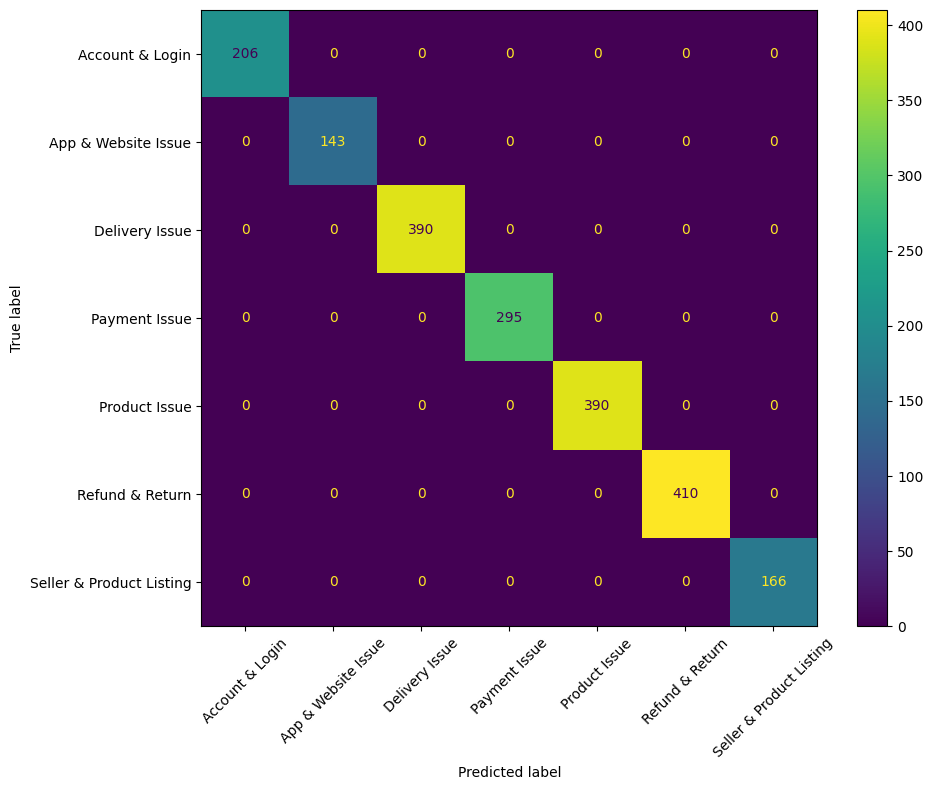

In [36]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=category_model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=category_model.classes_
)

fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(ax=ax, xticks_rotation=45)
plt.tight_layout()
plt.show()

In [37]:
# First, let's create the split



from sklearn.model_selection import StratifiedGroupKFold

X = tickets["ticket_text"]
y = tickets["ticket_category"]
groups = tickets["ticket_text"]

sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(
    sgkf.split(X, y, groups=groups)
)

X_train_group = X.iloc[train_idx]
X_test_group = X.iloc[test_idx]

y_train_group = y.iloc[train_idx]
y_test_group = y.iloc[test_idx]

print("Training samples:", len(X_train_group))
print("Testing samples :", len(X_test_group))

Training samples: 8000
Testing samples : 2000


In [38]:
train_texts = set(X_train_group)

overlap = X_test_group.isin(train_texts).sum()

print("Exact text overlap:", overlap)
print(
    "Overlap percentage:",
    round(overlap / len(X_test_group) * 100, 2),
    "%"
)

Exact text overlap: 0
Overlap percentage: 0.0 %


In [39]:
# check category balance


print("=== TRAIN DISTRIBUTION ===")

print(
    y_train_group.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\n=== TEST DISTRIBUTION ===")

print(
    y_test_group.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

=== TRAIN DISTRIBUTION ===
ticket_category
Refund & Return             20.50
Delivery Issue              19.50
Product Issue               19.48
Payment Issue               14.74
Account & Login             10.31
Seller & Product Listing     8.30
App & Website Issue          7.18
Name: proportion, dtype: float64

=== TEST DISTRIBUTION ===
ticket_category
Refund & Return             20.55
Product Issue               19.50
Delivery Issue              19.50
Payment Issue               14.75
Account & Login             10.25
Seller & Product Listing     8.30
App & Website Issue          7.15
Name: proportion, dtype: float64


In [40]:
tfidf_group = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2
)

X_train_group_tfidf = tfidf_group.fit_transform(X_train_group)

X_test_group_tfidf = tfidf_group.transform(X_test_group)

print("Training matrix:", X_train_group_tfidf.shape)
print("Testing matrix :", X_test_group_tfidf.shape)

Training matrix: (8000, 3428)
Testing matrix : (2000, 3428)


In [41]:
category_model_group = LogisticRegression(
    max_iter=1000,
    random_state=42
)

category_model_group.fit(
    X_train_group_tfidf,
    y_train_group
)

y_pred_group = category_model_group.predict(
    X_test_group_tfidf
)

In [42]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Accuracy :",
      round(accuracy_score(y_test_group, y_pred_group), 4))

print("Precision:",
      round(precision_score(
          y_test_group,
          y_pred_group,
          average="weighted"
      ), 4))

print("Recall   :",
      round(recall_score(
          y_test_group,
          y_pred_group,
          average="weighted"
      ), 4))

print("F1 Score :",
      round(f1_score(
          y_test_group,
          y_pred_group,
          average="weighted"
      ), 4))

print("\nClassification Report:\n")

print(
    classification_report(
        y_test_group,
        y_pred_group
    )
)

Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0

Classification Report:

                          precision    recall  f1-score   support

         Account & Login       1.00      1.00      1.00       205
     App & Website Issue       1.00      1.00      1.00       143
          Delivery Issue       1.00      1.00      1.00       390
           Payment Issue       1.00      1.00      1.00       295
           Product Issue       1.00      1.00      1.00       390
         Refund & Return       1.00      1.00      1.00       411
Seller & Product Listing       1.00      1.00      1.00       166

                accuracy                           1.00      2000
               macro avg       1.00      1.00      1.00      2000
            weighted avg       1.00      1.00      1.00      2000



In [159]:
# Create the data
X_priority = tickets["ticket_text"]
y_priority = tickets["priority"]

In [160]:
# Grouped split


from sklearn.model_selection import StratifiedGroupKFold

sgkf_priority = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx_p, test_idx_p = next(
    sgkf_priority.split(
        X_priority,
        y_priority,
        groups=X_priority
    )
)

X_train_p = X_priority.iloc[train_idx_p]
X_test_p = X_priority.iloc[test_idx_p]

y_train_p = y_priority.iloc[train_idx_p]
y_test_p = y_priority.iloc[test_idx_p]

print("Training samples:", len(X_train_p))
print("Testing samples :", len(X_test_p))

Training samples: 7998
Testing samples : 2002


In [161]:
overlap_p = X_test_p.isin(set(X_train_p)).sum()

print("Exact text overlap:", overlap_p)
print(
    "Overlap percentage:",
    round(overlap_p / len(X_test_p) * 100, 2),
    "%"
)

Exact text overlap: 0
Overlap percentage: 0.0 %


In [162]:
# Step 2 — TF-IDF

# Used a new vectorizer:

tfidf_priority = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2
)

X_train_p_tfidf = tfidf_priority.fit_transform(X_train_p)

X_test_p_tfidf = tfidf_priority.transform(X_test_p)

print("Training matrix:", X_train_p_tfidf.shape)
print("Testing matrix :", X_test_p_tfidf.shape)

Training matrix: (7998, 3434)
Testing matrix : (2002, 3434)


In [163]:
# Step 3 — Logistic Regression
priority_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

priority_model.fit(
    X_train_p_tfidf,
    y_train_p
)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multi

In [164]:
y_pred_p = priority_model.predict(X_test_p_tfidf)

In [165]:
# Step 4 — Evaluate
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print(
    "Accuracy :",
    round(accuracy_score(y_test_p, y_pred_p), 4)
)

print(
    "Precision:",
    round(
        precision_score(
            y_test_p,
            y_pred_p,
            average="weighted"
        ), 4
    )
)

print(
    "Recall   :",
    round(
        recall_score(
            y_test_p,
            y_pred_p,
            average="weighted"
        ), 4
    )
)

print(
    "F1 Score :",
    round(
        f1_score(
            y_test_p,
            y_pred_p,
            average="weighted"
        ), 4
    )
)

print("\nClassification Report:\n")

print(
    classification_report(
        y_test_p,
        y_pred_p
    )
)

Accuracy : 0.8676
Precision: 0.8648
Recall   : 0.8676
F1 Score : 0.8659

Classification Report:

              precision    recall  f1-score   support

        High       0.93      0.95      0.94       925
         Low       0.72      0.66      0.69       345
      Medium       0.85      0.86      0.85       732

    accuracy                           0.87      2002
   macro avg       0.83      0.82      0.83      2002
weighted avg       0.86      0.87      0.87      2002



In [166]:
# Sentiment Model — Baseline


# Step 1
X_sentiment = tickets["ticket_text"]
y_sentiment = tickets["sentiment"]

In [167]:
# Step 2 — grouped split
from sklearn.model_selection import StratifiedGroupKFold

sgkf_sentiment = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx_s, test_idx_s = next(
    sgkf_sentiment.split(
        X_sentiment,
        y_sentiment,
        groups=X_sentiment
    )
)

X_train_s = X_sentiment.iloc[train_idx_s]
X_test_s = X_sentiment.iloc[test_idx_s]

y_train_s = y_sentiment.iloc[train_idx_s]
y_test_s = y_sentiment.iloc[test_idx_s]

print("Training samples:", len(X_train_s))
print("Testing samples :", len(X_test_s))

Training samples: 8000
Testing samples : 2000


In [168]:
# Step 3 — verify zero overlap
overlap_s = X_test_s.isin(set(X_train_s)).sum()

print("Exact text overlap:", overlap_s)

print(
    "Overlap percentage:",
    round(overlap_s / len(X_test_s) * 100, 2),
    "%"
)

Exact text overlap: 0
Overlap percentage: 0.0 %


In [169]:
# Step 4 — TF-IDF
tfidf_sentiment = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2
)

X_train_s_tfidf = tfidf_sentiment.fit_transform(X_train_s)

X_test_s_tfidf = tfidf_sentiment.transform(X_test_s)

print("Training matrix:", X_train_s_tfidf.shape)
print("Testing matrix :", X_test_s_tfidf.shape)

Training matrix: (8000, 3447)
Testing matrix : (2000, 3447)


In [170]:
# Step 5 — Logistic Regression
sentiment_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

sentiment_model.fit(
    X_train_s_tfidf,
    y_train_s
)

y_pred_s = sentiment_model.predict(
    X_test_s_tfidf
)

In [171]:
# Step 6 — Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print(
    "Accuracy :",
    round(accuracy_score(y_test_s, y_pred_s), 4)
)

print(
    "Precision:",
    round(
        precision_score(
            y_test_s,
            y_pred_s,
            average="weighted"
        ), 4
    )
)

print(
    "Recall   :",
    round(
        recall_score(
            y_test_s,
            y_pred_s,
            average="weighted"
        ), 4
    )
)

print(
    "F1 Score :",
    round(
        f1_score(
            y_test_s,
            y_pred_s,
            average="weighted"
        ), 4
    )
)

print("\nClassification Report:\n")

print(
    classification_report(
        y_test_s,
        y_pred_s
    )
)

Accuracy : 0.5275
Precision: 0.4786
Recall   : 0.5275
F1 Score : 0.4704

Classification Report:

                   precision    recall  f1-score   support

         Negative       0.61      0.91      0.73       615
          Neutral       0.48      0.61      0.54       546
         Positive       0.43      0.22      0.29       170
Slightly Negative       0.44      0.31      0.37       360
    Very Negative       0.29      0.03      0.06       309

         accuracy                           0.53      2000
        macro avg       0.45      0.42      0.40      2000
     weighted avg       0.48      0.53      0.47      2000



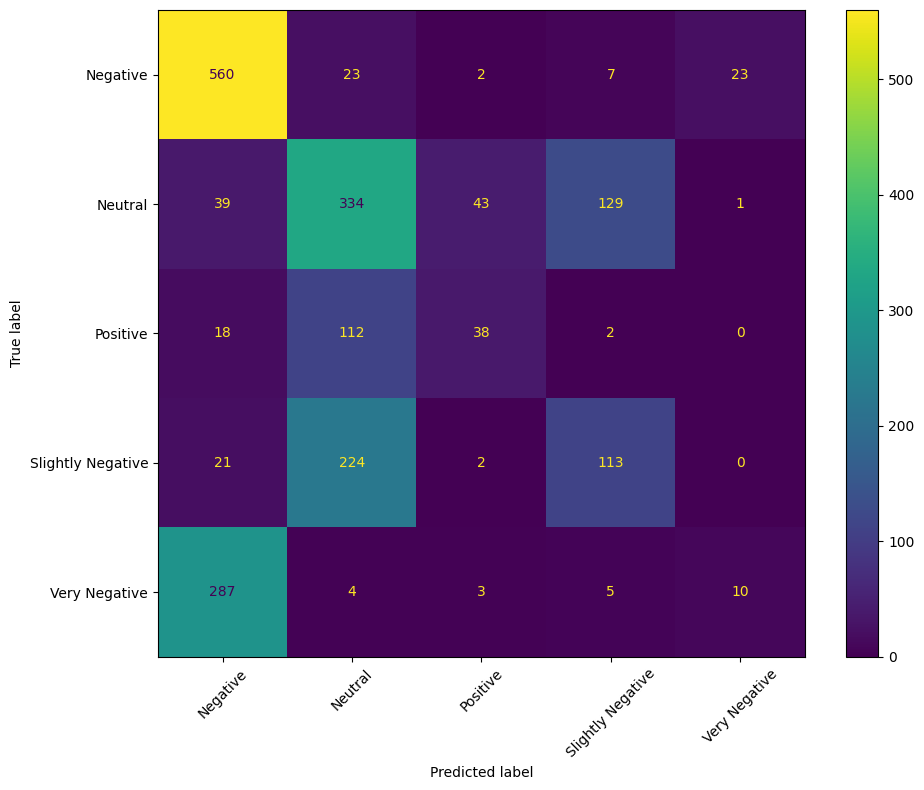

In [172]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_sentiment = confusion_matrix(
    y_test_s,
    y_pred_s,
    labels=sentiment_model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_sentiment,
    display_labels=sentiment_model.classes_
)

fig, ax = plt.subplots(figsize=(10, 8))

disp.plot(
    ax=ax,
    xticks_rotation=45
)

plt.tight_layout()
plt.show()

In [173]:
pd.crosstab(
    y_test_s,
    y_pred_s,
    normalize="index"
).round(3)

col_0,Negative,Neutral,Positive,Slightly Negative,Very Negative
sentiment,,,,,
Negative,0.911,0.037,0.003,0.011,0.037
Neutral,0.071,0.612,0.079,0.236,0.002
Positive,0.106,0.659,0.224,0.012,0.000
Slightly Negative,0.058,0.622,0.006,0.314,0.000
Very Negative,0.929,0.013,0.010,0.016,0.032


In [174]:
# %pip install -U sentence-transformers

In [175]:
from sentence_transformers import SentenceTransformer

embedding_model = SentenceTransformer("all-MiniLM-L6-v2")

print("Embedding model loaded successfully")

Loading weights: 100%|██████████| 103/103 [00:00<?, ?it/s]


Embedding model loaded successfully


In [176]:
[name for name in globals() if not name.startswith("_")]

['In',
 'Out',
 'get_ipython',
 'exit',
 'quit',
 'open',
 'pd',
 'np',
 'tickets_path',
 'faq_path',
 'tickets',
 'faq',
 'sample',
 're',
 'text_counts',
 'category_conflicts',
 'priority_conflicts',
 'sentiment_conflicts',
 'conflicting_priority_texts',
 'unique_counts',
 'repeated_tickets',
 'train_test_split',
 'train',
 'test',
 'train_texts',
 'overlap',
 'sklearn',
 'X',
 'y',
 'X_train',
 'X_test',
 'y_train',
 'y_test',
 'TfidfVectorizer',
 'tfidf',
 'X_train_tfidf',
 'X_test_tfidf',
 'LogisticRegression',
 'category_model',
 'y_pred',
 'accuracy_score',
 'precision_score',
 'recall_score',
 'f1_score',
 'classification_report',
 'accuracy',
 'precision',
 'recall',
 'f1',
 'confusion_matrix',
 'ConfusionMatrixDisplay',
 'plt',
 'cm',
 'disp',
 'fig',
 'ax',
 'StratifiedGroupKFold',
 'groups',
 'sgkf',
 'train_idx',
 'test_idx',
 'X_train_group',
 'X_test_group',
 'y_train_group',
 'y_test_group',
 'tfidf_group',
 'X_train_group_tfidf',
 'X_test_group_tfidf',
 'category_model

In [177]:
import os

print(os.getcwd())
print(os.listdir())

c:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform\notebooks
['01_data_exploration.ipynb', 'requirements_current.txt']


In [178]:
# Step 1 — Confirm the data
print(tickets.shape)

(10000, 18)


In [179]:
# Step 2 — Check our sentiment variables
[name for name in globals()
 if any(x in name.lower() for x in ["train", "test", "sentiment"])]

['sentiment_conflicts',
 'train_test_split',
 'train',
 'test',
 'train_texts',
 'X_train',
 'X_test',
 'y_train',
 'y_test',
 'X_train_tfidf',
 'X_test_tfidf',
 'train_idx',
 'test_idx',
 'X_train_group',
 'X_test_group',
 'y_train_group',
 'y_test_group',
 'X_train_group_tfidf',
 'X_test_group_tfidf',
 'train_idx_p',
 'test_idx_p',
 'X_train_p',
 'X_test_p',
 'y_train_p',
 'y_test_p',
 'X_train_p_tfidf',
 'X_test_p_tfidf',
 'X_sentiment',
 'y_sentiment',
 'sgkf_sentiment',
 'train_idx_s',
 'test_idx_s',
 'X_train_s',
 'X_test_s',
 'y_train_s',
 'y_test_s',
 'tfidf_sentiment',
 'X_train_s_tfidf',
 'X_test_s_tfidf',
 'sentiment_model',
 'cm_sentiment',
 'X_train_emb',
 'X_test_emb',
 'sentiment_model_v2',
 'collapse_sentiment',
 'y_test_3',
 'X_test_p_category_tfidf',
 'X_test_p_sentiment_tfidf',
 'sentiment_for_priority',
 'category_for_priority_train',
 'sentiment_for_priority_train',
 'X_train_p_v2',
 'X_test_p_v2',
 'X_train_text_v2',
 'X_test_text_v2',
 'X_train_cat_sent_v2',
 'X_

In [180]:
# Step 1 — Create the sentence embeddings
[name for name in globals() if "_s" in name.lower()]

['__spec__',
 'train_test_split',
 'accuracy_score',
 'precision_score',
 'recall_score',
 'f1_score',
 'X_sentiment',
 'y_sentiment',
 'sgkf_sentiment',
 'train_idx_s',
 'test_idx_s',
 'X_train_s',
 'X_test_s',
 'y_train_s',
 'y_test_s',
 'overlap_s',
 'tfidf_sentiment',
 'X_train_s_tfidf',
 'X_test_s_tfidf',
 'y_pred_s',
 'cm_sentiment',
 'y_pred_s_v2',
 'collapse_sentiment',
 'X_test_p_sentiment_tfidf',
 'X_train_cat_sent_v2',
 'X_test_cat_sent_v2']

In [181]:
# Step 2 — Generate V2 embeddings
X_train_emb = embedding_model.encode(
    X_train_s.tolist(),
    show_progress_bar=True
)

X_test_emb = embedding_model.encode(
    X_test_s.tolist(),
    show_progress_bar=True
)

print("Train embedding shape:", X_train_emb.shape)
print("Test embedding shape:", X_test_emb.shape)

Batches: 100%|██████████| 63/63 [00:09<00:00,  6.91it/s]

Train embedding shape: (8000, 384)
Test embedding shape: (2000, 384)


In [182]:
# Step 3 — Build Sentiment V2
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

sentiment_model_v2 = LogisticRegression(
    max_iter=2000,
    random_state=42
)

sentiment_model_v2.fit(X_train_emb, y_train_s)

y_pred_s_v2 = sentiment_model_v2.predict(X_test_emb)

print("Sentiment V2 Results")
print("-" * 40)

print("Accuracy :", accuracy_score(y_test_s, y_pred_s_v2))
print("Precision:", precision_score(
    y_test_s, y_pred_s_v2, average="weighted"
))
print("Recall   :", recall_score(
    y_test_s, y_pred_s_v2, average="weighted"
))
print("F1 Score :", f1_score(
    y_test_s, y_pred_s_v2, average="weighted"
))

print("\nClassification Report:")
print(classification_report(y_test_s, y_pred_s_v2))

Sentiment V2 Results
----------------------------------------
Accuracy : 0.5015
Precision: 0.44053766263199773
Recall   : 0.5015
F1 Score : 0.4420304779141817

Classification Report:
                   precision    recall  f1-score   support

         Negative       0.58      0.91      0.71       615
          Neutral       0.47      0.56      0.51       546
         Positive       0.27      0.22      0.24       170
Slightly Negative       0.41      0.26      0.32       360
    Very Negative       0.23      0.02      0.03       309

         accuracy                           0.50      2000
        macro avg       0.39      0.39      0.36      2000
     weighted avg       0.44      0.50      0.44      2000



In [183]:
def collapse_sentiment(s):
    if s in ["Negative", "Slightly Negative", "Very Negative"]:
        return "Negative"
    elif s == "Positive":
        return "Positive"
    else:
        return "Neutral"


y_test_3 = y_test_s.apply(collapse_sentiment)
y_pred_3 = pd.Series(y_pred_s).apply(collapse_sentiment)

print(classification_report(y_test_3, y_pred_3))

              precision    recall  f1-score   support

    Negative       0.84      0.80      0.82      1284
     Neutral       0.48      0.61      0.54       546
    Positive       0.43      0.22      0.29       170

    accuracy                           0.70      2000
   macro avg       0.59      0.54      0.55      2000
weighted avg       0.71      0.70      0.70      2000



In [184]:
# Step 1 — First, let's inspect what models/variables we already have
[name for name in globals()
 if any(x in name.lower() for x in [
     "category", "priority", "sentiment", "pred"
 ])]

['category_conflicts',
 'priority_conflicts',
 'sentiment_conflicts',
 'conflicting_priority_texts',
 'category_model',
 'y_pred',
 'category_model_group',
 'y_pred_group',
 'X_priority',
 'y_priority',
 'sgkf_priority',
 'tfidf_priority',
 'priority_model',
 'y_pred_p',
 'X_sentiment',
 'y_sentiment',
 'sgkf_sentiment',
 'tfidf_sentiment',
 'sentiment_model',
 'y_pred_s',
 'cm_sentiment',
 'sentiment_model_v2',
 'y_pred_s_v2',
 'collapse_sentiment',
 'y_pred_3',
 'X_test_p_category_tfidf',
 'category_for_priority',
 'X_test_p_sentiment_tfidf',
 'sentiment_for_priority',
 'category_for_priority_train',
 'sentiment_for_priority_train',
 'tfidf_priority_v2',
 'priority_model_v2',
 'y_pred_p_v2']

In [185]:
print("Priority train:", len(X_priority))
print("Priority test :", len(y_priority))

print("\nPriority model classes:")
print(priority_model.classes_)

Priority train: 10000
Priority test : 10000

Priority model classes:
['High' 'Low' 'Medium']


In [186]:
print("Priority test distribution:")
print(y_priority.value_counts())

Priority test distribution:
priority
High      4620
Medium    3657
Low       1723
Name: count, dtype: int64


In [187]:
# Step 3 — Build Sentiment V2
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

sentiment_model_v2 = LogisticRegression(
    max_iter=2000,
    random_state=42
)

sentiment_model_v2.fit(X_train_emb, y_train_s)

y_pred_s_v2 = sentiment_model_v2.predict(X_test_emb)

print("Sentiment V2 Results")
print("-" * 40)

print("Accuracy :", accuracy_score(y_test_s, y_pred_s_v2))
print("Precision:", precision_score(
    y_test_s, y_pred_s_v2, average="weighted"
))
print("Recall   :", recall_score(
    y_test_s, y_pred_s_v2, average="weighted"
))
print("F1 Score :", f1_score(
    y_test_s, y_pred_s_v2, average="weighted"
))

print("\nClassification Report:")
print(classification_report(y_test_s, y_pred_s_v2))

Sentiment V2 Results
----------------------------------------
Accuracy : 0.5015
Precision: 0.44053766263199773
Recall   : 0.5015
F1 Score : 0.4420304779141817

Classification Report:
                   precision    recall  f1-score   support

         Negative       0.58      0.91      0.71       615
          Neutral       0.47      0.56      0.51       546
         Positive       0.27      0.22      0.24       170
Slightly Negative       0.41      0.26      0.32       360
    Very Negative       0.23      0.02      0.03       309

         accuracy                           0.50      2000
        macro avg       0.39      0.39      0.36      2000
     weighted avg       0.44      0.50      0.44      2000



In [188]:
[name for name in globals()
 if "_p" in name.lower() or "priority" in name.lower()]

['__package__',
 'tickets_path',
 'faq_path',
 'priority_conflicts',
 'conflicting_priority_texts',
 'y_pred',
 'y_pred_group',
 'X_priority',
 'y_priority',
 'sgkf_priority',
 'train_idx_p',
 'test_idx_p',
 'X_train_p',
 'X_test_p',
 'y_train_p',
 'y_test_p',
 'overlap_p',
 'tfidf_priority',
 'X_train_p_tfidf',
 'X_test_p_tfidf',
 'priority_model',
 'y_pred_p',
 'y_pred_s',
 'y_pred_s_v2',
 'y_pred_3',
 'X_test_p_category_tfidf',
 'category_for_priority',
 'X_test_p_sentiment_tfidf',
 'sentiment_for_priority',
 'category_for_priority_train',
 'sentiment_for_priority_train',
 'X_train_p_v2',
 'X_test_p_v2',
 'tfidf_priority_v2',
 'priority_model_v2',
 'y_pred_p_v2',
 'faq_payment',
 'notebook_path',
 'output_path']

In [189]:
print("Priority train:", len(X_train_p))
print("Priority test :", len(X_test_p))

print("\nOverlap:",
      len(set(X_train_p) & set(X_test_p)))

print("\nTest distribution:")
print(y_test_p.value_counts())

Priority train: 7998
Priority test : 2002

Overlap: 0

Test distribution:
priority
High      925
Medium    732
Low       345
Name: count, dtype: int64


In [190]:
[name for name in globals()
 if "tfidf" in name.lower() and "category" in name.lower()]

['X_test_p_category_tfidf']

In [191]:
[name for name in globals()
 if "tfidf" in name.lower()]

['TfidfVectorizer',
 'tfidf',
 'X_train_tfidf',
 'X_test_tfidf',
 'tfidf_group',
 'X_train_group_tfidf',
 'X_test_group_tfidf',
 'tfidf_priority',
 'X_train_p_tfidf',
 'X_test_p_tfidf',
 'tfidf_sentiment',
 'X_train_s_tfidf',
 'X_test_s_tfidf',
 'X_test_p_category_tfidf',
 'X_test_p_sentiment_tfidf',
 'tfidf_priority_v2']

In [192]:
print(tfidf_group)
print("\nFeatures:", len(tfidf_group.get_feature_names_out()))

TfidfVectorizer(min_df=2, ngram_range=(1, 2))

Features: 3428


In [193]:
X_test_p_category_tfidf = tfidf_group.transform(X_test_p)

category_for_priority = category_model_group.predict(
    X_test_p_category_tfidf
)

print("Category predictions:", len(category_for_priority))
print(pd.Series(category_for_priority).value_counts())

Category predictions: 2002
Refund & Return             412
Delivery Issue              395
Product Issue               365
Payment Issue               320
App & Website Issue         197
Seller & Product Listing    172
Account & Login             141
Name: count, dtype: int64


In [194]:
X_test_p_sentiment_tfidf = tfidf_sentiment.transform(X_test_p)

sentiment_for_priority = sentiment_model.predict(
    X_test_p_sentiment_tfidf
)

print("Sentiment predictions:", len(sentiment_for_priority))
print("\nSentiment distribution:")
print(pd.Series(sentiment_for_priority).value_counts())

Sentiment predictions: 2002

Sentiment distribution:
Negative             912
Neutral              685
Slightly Negative    286
Positive              85
Very Negative         34
Name: count, dtype: int64


In [195]:
print("tickets:", "tickets" in globals())
print("faq:", "faq" in globals())

print("category_model_group:", "category_model_group" in globals())
print("priority_model:", "priority_model" in globals())
print("sentiment_model:", "sentiment_model" in globals())
print("embedding_model:", "embedding_model" in globals())

print("X_train_p:", "X_train_p" in globals())
print("X_test_p:", "X_test_p" in globals())
print("y_train_p:", "y_train_p" in globals())
print("y_test_p:", "y_test_p" in globals())

print("category_for_priority:", "category_for_priority" in globals())
print("sentiment_for_priority:", "sentiment_for_priority" in globals())

tickets: True
faq: True
category_model_group: True
priority_model: True
sentiment_model: True
embedding_model: True
X_train_p: True
X_test_p: True
y_train_p: True
y_test_p: True
category_for_priority: True
sentiment_for_priority: True


In [196]:
import importlib.util

packages = [
    "sentence_transformers",
    "pandas",
    "numpy",
    "sklearn",
    "faiss",
    "nltk",
    "streamlit",
    "langgraph",
]

for package in packages:
    status = "Installed" if importlib.util.find_spec(package) else "NOT installed"
    print(f"{package:25} : {status}")

sentence_transformers     : Installed
pandas                    : Installed
numpy                     : Installed
sklearn                   : Installed
faiss                     : Installed
nltk                      : NOT installed
streamlit                 : Installed
langgraph                 : Installed


In [197]:
print(tickets.shape)
print(faq.shape)

(10000, 18)
(150, 4)


In [198]:
print("Category model:", "category_model_group" in globals())
print("Priority model:", "priority_model" in globals())
print("Sentiment model:", "sentiment_model" in globals())

Category model: True
Priority model: True
Sentiment model: True


In [199]:
print("Priority test rows:", len(y_test_p))
print("Priority predictions:", len(y_pred_p))

print("\nPriority V1 Accuracy:")
print(accuracy_score(y_test_p, y_pred_p))

print("\nSentiment test rows:", len(y_test_s))
print("Sentiment predictions:", len(y_pred_s))

print("\nSentiment V1 Accuracy:")
print(accuracy_score(y_test_s, y_pred_s))

Priority test rows: 2002
Priority predictions: 2002

Priority V1 Accuracy:
0.8676323676323676

Sentiment test rows: 2000
Sentiment predictions: 2000

Sentiment V1 Accuracy:
0.5275


In [200]:
print("========== PRIORITY V2 PRE-CHECK ==========")

print("Priority train rows:", len(y_train_p))
print("Priority test rows:", len(y_test_p))

print("Category test predictions:", len(category_for_priority))
print("Sentiment test predictions:", len(sentiment_for_priority))

print("===========================================")

========== PRIORITY V2 PRE-CHECK ==========
Priority train rows: 7998
Priority test rows: 2002
Category test predictions: 2002
Sentiment test predictions: 2002


In [201]:
# Recreate upstream predictions for Priority V2 test set

category_for_priority = category_model_group.predict(
    tfidf_group.transform(X_test_p)
)

sentiment_for_priority = sentiment_model.predict(
    tfidf_sentiment.transform(X_test_p)
)

print("Category predictions:", len(category_for_priority))
print("Sentiment predictions:", len(sentiment_for_priority))

Category predictions: 2002
Sentiment predictions: 2002


In [202]:
# Generate upstream predictions for Priority V2 training data

category_for_priority_train = category_model_group.predict(
    tfidf_group.transform(X_train_p)
)

sentiment_for_priority_train = sentiment_model.predict(
    tfidf_sentiment.transform(X_train_p)
)

print("Category train predictions:", len(category_for_priority_train))
print("Sentiment train predictions:", len(sentiment_for_priority_train))

Category train predictions: 7998
Sentiment train predictions: 7998


In [203]:
# Build Priority V2 feature sets

X_train_p_v2 = pd.DataFrame({
    "ticket_text": X_train_p.values,
    "predicted_category": category_for_priority_train,
    "predicted_sentiment": sentiment_for_priority_train
})

X_test_p_v2 = pd.DataFrame({
    "ticket_text": X_test_p.values,
    "predicted_category": category_for_priority,
    "predicted_sentiment": sentiment_for_priority
})

print("Priority V2 train shape:", X_train_p_v2.shape)
print("Priority V2 test shape:", X_test_p_v2.shape)

print("\nSample:")
display(X_train_p_v2.head())

Priority V2 train shape: (7998, 3)
Priority V2 test shape: (2002, 3)

Sample:


,ticket_text,predicted_category,predicted_sentiment
0,The lipstick I received in order #ORD5614226 stopped working after just 5 days of use.,Product Issue,Negative
1,The shoe rack received in order #ORD8038374 has scratches and dents. Looks like a returned/used item.,Product Issue,Negative
2,I want to exchange my conditioner (order #ORD6770619) for a different size. Exchange option is missing.,Refund & Return,Neutral
3,My makeup brush set from order #ORD4823498 appears to be counterfeit/fake. Not the original brand.,Product Issue,Negative
4,Fake reviews on the shoe rack I bought misled me into purchasing. Quality is very poor.,Seller & Product Listing,Slightly Negative


In [204]:
from scipy.sparse import hstack, csr_matrix
from sklearn.preprocessing import OneHotEncoder

# TF-IDF for ticket text
tfidf_priority_v2 = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2
)

X_train_text_v2 = tfidf_priority_v2.fit_transform(
    X_train_p_v2["ticket_text"]
)

X_test_text_v2 = tfidf_priority_v2.transform(
    X_test_p_v2["ticket_text"]
)

# One-hot encode predicted category + sentiment
encoder_v2 = OneHotEncoder(
    handle_unknown="ignore"
)

X_train_cat_sent_v2 = encoder_v2.fit_transform(
    X_train_p_v2[["predicted_category", "predicted_sentiment"]]
)

X_test_cat_sent_v2 = encoder_v2.transform(
    X_test_p_v2[["predicted_category", "predicted_sentiment"]]
)

# Combine text + categorical features
X_train_v2 = hstack([
    X_train_text_v2,
    X_train_cat_sent_v2
])

X_test_v2 = hstack([
    X_test_text_v2,
    X_test_cat_sent_v2
])

print("Text features:", X_train_text_v2.shape)
print("Category/Sentiment features:", X_train_cat_sent_v2.shape)
print("Final V2 train shape:", X_train_v2.shape)
print("Final V2 test shape:", X_test_v2.shape)

Text features: (7998, 3434)
Category/Sentiment features: (7998, 12)
Final V2 train shape: (7998, 3446)
Final V2 test shape: (2002, 3446)


In [205]:
# Train Priority V2

priority_model_v2 = LogisticRegression(
    max_iter=1000,
    random_state=42
)

priority_model_v2.fit(X_train_v2, y_train_p)

y_pred_p_v2 = priority_model_v2.predict(X_test_v2)

print("========== PRIORITY V2 ==========")
print("Accuracy :", round(accuracy_score(y_test_p, y_pred_p_v2), 4))
print("Precision:", round(precision_score(y_test_p, y_pred_p_v2, average="weighted"), 4))
print("Recall   :", round(recall_score(y_test_p, y_pred_p_v2, average="weighted"), 4))
print("F1 Score :", round(f1_score(y_test_p, y_pred_p_v2, average="weighted"), 4))
print("=================================")

========== PRIORITY V2 ==========
Accuracy : 0.8676
Precision: 0.8648
Recall   : 0.8676
F1 Score : 0.8659


In [206]:
# inspect the actual FAQ and resolution data

print("========== RAG DATA PREVIEW ==========")

print("\nFAQ SAMPLE")
display(faq.head(5))

print("\nRESOLUTION SAMPLE")
display(
    tickets[
        ["ticket_text", "ticket_category", "resolution_text"]
    ].head(5)
)

print("\nResolution missing values:")
print(tickets["resolution_text"].isna().sum())

print("======================================")

========== RAG DATA PREVIEW ==========

FAQ SAMPLE


,faq_id,question,answer,category
0,FAQ001,How do I track my order?,Go to My Orders > Select Order > Track Package for real-time courier updates.,Delivery Issue
1,FAQ002,What should I do if my order is delayed?,"Check tracking first. If no update for 48 hours, raise a complaint via My Orders > Help.",Delivery Issue
2,FAQ003,Can I change my delivery address after placing an order?,"Yes, before dispatch. Go to My Orders > Order Details > Edit Address.",Delivery Issue
3,FAQ004,What happens if I miss my delivery?,Courier will reattempt delivery. You can also reschedule via the tracking link.,Delivery Issue
4,FAQ005,How do I reschedule my delivery?,Use the tracking link in your SMS/email to select a new delivery slot.,Delivery Issue



RESOLUTION SAMPLE


,ticket_text,ticket_category,resolution_text
0,The lipstick I received in order #ORD5614226 stopped working after just 5 days of use.,Product Issue,Full refund processed. Seller account flagged for quality investigation.
1,The shoe rack received in order #ORD8038374 has scratches and dents. Looks like a returned/used item.,Product Issue,Missing accessory shipped separately at no additional cost.
2,I want to exchange my conditioner (order #ORD6770619) for a different size. Exchange option is missing.,Refund & Return,Accidental order refund approved. Amount credited within 2 days.
3,My makeup brush set from order #ORD4823498 appears to be counterfeit/fake. Not the original brand.,Product Issue,Missing accessory shipped separately at no additional cost.
4,Product listing for lipstick is completely misleading. The actual product is nothing like the photos.,Product Issue,Replacement lipstick dispatched after quality team verification.



Resolution missing values:
0


In [207]:
# Create RAG documents from FAQ and historical resolutions

faq_documents = []

for _, row in faq.iterrows():
    text = (
        f"Question: {row['question']}\n"
        f"Answer: {row['answer']}\n"
        f"Category: {row['category']}"
    )

    faq_documents.append({
        "text": text,
        "source": "FAQ",
        "category": row["category"],
        "id": row["faq_id"]
    })


resolution_documents = []

for _, row in tickets.iterrows():
    text = (
        f"Customer Issue: {row['ticket_text']}\n"
        f"Resolution: {row['resolution_text']}\n"
        f"Category: {row['ticket_category']}"
    )

    resolution_documents.append({
        "text": text,
        "source": "Historical Resolution",
        "category": row["ticket_category"],
        "id": row["ticket_id"]
    })


rag_documents = faq_documents + resolution_documents

print("FAQ documents:", len(faq_documents))
print("Historical resolution documents:", len(resolution_documents))
print("Total RAG documents:", len(rag_documents))

print("\nSample FAQ document:")
print(faq_documents[0]["text"])

print("\nSample historical document:")
print(resolution_documents[0]["text"])

FAQ documents: 150
Historical resolution documents: 10000
Total RAG documents: 10150

Sample FAQ document:
Question: How do I track my order?
Answer: Go to My Orders > Select Order > Track Package for real-time courier updates.
Category: Delivery Issue

Sample historical document:
Customer Issue: The lipstick I received in order #ORD5614226 stopped working after just 5 days of use.
Resolution: Full refund processed. Seller account flagged for quality investigation.
Category: Product Issue


In [208]:
# verify the embedding model is available.
print("Embedding model available:",
      "embedding_model" in globals())

Embedding model available: True


In [212]:
# Step 3 — Generate embeddings
# Create embeddings for all RAG documents

rag_texts = [doc["text"] for doc in rag_documents]

rag_embeddings = embedding_model.encode(
    rag_texts,
    show_progress_bar=True,
    batch_size=32
)

print("\nRAG embeddings shape:", rag_embeddings.shape)
print("Number of documents:", len(rag_documents))
print("Embedding dimension:", rag_embeddings.shape[1])

Batches: 100%|██████████| 318/318 [01:39<00:00,  3.18it/s]



RAG embeddings shape: (10150, 384)
Number of documents: 10150
Embedding dimension: 384


In [213]:
try:
    import faiss
    print("FAISS: Installed")
    print("FAISS version:", faiss.__version__)
except ImportError:
    print("FAISS: NOT installed")

FAISS: Installed
FAISS version: 1.15.1


In [214]:
# Step 1 — Install FAISS
%pip install faiss-cpu

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [215]:
# Step 2 — Verify
import faiss

print("FAISS installed successfully")
print("FAISS version:", faiss.__version__)

FAISS installed successfully
FAISS version: 1.15.1


In [216]:
print("===== PROJECT 6 CHECKPOINT =====")

checks = {
    "tickets": "tickets" in globals(),
    "faq": "faq" in globals(),
    "category_model_group": "category_model_group" in globals(),
    "priority_model": "priority_model" in globals(),
    "sentiment_model": "sentiment_model" in globals(),
    "embedding_model": "embedding_model" in globals(),
    "rag_documents": "rag_documents" in globals(),
    "rag_embeddings": "rag_embeddings" in globals(),
}

for name, status in checks.items():
    print(f"{name:<25}: {status}")

===== PROJECT 6 CHECKPOINT =====
tickets                  : True
faq                      : True
category_model_group     : True
priority_model           : True
sentiment_model          : True
embedding_model          : True
rag_documents            : True
rag_embeddings           : True


In [217]:
print("tickets_path:", tickets_path if "tickets_path" in globals() else "NOT DEFINED")
print("faq_path:", faq_path if "faq_path" in globals() else "NOT DEFINED")

tickets_path: ../Raw data/support_tickets_10k.csv
faq_path: ../Raw data/faq_knowledge_base_150.csv


In [218]:
print(tickets.shape)
print(faq.shape)

(10000, 18)
(150, 4)


In [219]:
# ==========================================
# PROJECT 6 — RAG FAISS VECTOR INDEX
# ==========================================

import faiss
import numpy as np

# Convert embeddings to float32
rag_embeddings_f32 = np.asarray(
    rag_embeddings,
    dtype="float32"
)

# Normalize vectors for cosine similarity
faiss.normalize_L2(rag_embeddings_f32)

# Create FAISS index
embedding_dimension = rag_embeddings_f32.shape[1]

rag_index = faiss.IndexFlatIP(embedding_dimension)

# Add all RAG document vectors
rag_index.add(rag_embeddings_f32)

print("========== FAISS INDEX ==========")
print("Embedding dimension:", embedding_dimension)
print("Documents indexed:", rag_index.ntotal)
print("Index type:", type(rag_index).__name__)
print("=================================")

========== FAISS INDEX ==========
Embedding dimension: 384
Documents indexed: 10150
Index type: IndexFlatIP


In [220]:
# retrieval test

# ==========================================
# PROJECT 6 — FIRST RAG RETRIEVAL TEST
# ==========================================

query = (
    "My order has not arrived yet and it is several days "
    "past the expected delivery date."
)

# Create query embedding
query_embedding = embedding_model.encode(
    [query],
    convert_to_numpy=True
).astype("float32")

# Normalize for cosine similarity
faiss.normalize_L2(query_embedding)

# Retrieve top 5 documents
scores, indices = rag_index.search(
    query_embedding,
    5
)

print("========== RETRIEVAL TEST ==========")
print("Query:")
print(query)

print("\nTop 5 Retrieved Documents:")
print("====================================")

for rank, (score, idx) in enumerate(
    zip(scores[0], indices[0]), start=1
):
    doc = rag_documents[idx]

    print(f"\nRank {rank}")
    print(f"Similarity Score: {score:.4f}")
    print(f"Source: {doc['source']}")
    print(f"Category: {doc['category']}")
    print(f"Document ID: {doc['id']}")
    print("Text:")
    print(doc["text"])

========== RETRIEVAL TEST ==========
Query:
My order has not arrived yet and it is several days past the expected delivery date.

Top 5 Retrieved Documents:

Rank 1
Similarity Score: 0.6374
Source: Historical Resolution
Category: Delivery Issue
Document ID: TKT102827
Text:
Customer Issue: My order #ORD6582975 for foundation hasn't arrived yet. It has been 10 days past the expected delivery date. This is unacceptable.
Resolution: Delivery rescheduled as per customer's preferred slot. Partner notified.
Category: Delivery Issue

Rank 2
Similarity Score: 0.6261
Source: Historical Resolution
Category: Delivery Issue
Document ID: TKT107537
Text:
Customer Issue: My order #ORD6109582 for storage rack hasn't arrived yet. It has been 9 days past the expected delivery date. This is unacceptable.
Resolution: Complaint escalated to logistics team. Full refund processed as compensation for delay.
Category: Delivery Issue

Rank 3
Similarity Score: 0.6237
Source: Historical Resolution
Category: Delive

In [221]:
def retrieve_documents(query, top_k=5):
    query_embedding = embedding_model.encode(
        [query],
        convert_to_numpy=True
    ).astype("float32")

    faiss.normalize_L2(query_embedding)

    scores, indices = rag_index.search(
        query_embedding,
        top_k
    )

    results = []

    for score, idx in zip(scores[0], indices[0]):
        doc = rag_documents[idx]

        results.append({
            "score": float(score),
            "source": doc["source"],
            "category": doc["category"],
            "id": doc["id"],
            "text": doc["text"]
        })

    return results

In [222]:
results = retrieve_documents(
    "I was charged twice for the same order."
)

for i, result in enumerate(results, 1):
    print(f"\nRank {i}")
    print(f"Score: {result['score']:.4f}")
    print(f"Source: {result['source']}")
    print(f"Category: {result['category']}")
    print(result["text"])


Rank 1
Score: 0.6862
Source: Historical Resolution
Category: Refund & Return
Customer Issue: I was charged twice for order #ORD5926534 (science encyclopedia). Please refund the duplicate payment immediately.
Resolution: Seller notified of return in transit. Refund released on priority basis.
Category: Refund & Return

Rank 2
Score: 0.6732
Source: Historical Resolution
Category: Refund & Return
Customer Issue: I was charged twice for order #ORD9324825 (smartphone). Please refund the duplicate payment immediately.
Resolution: Return pickup scheduled for next business day. Refund post quality check.
Category: Refund & Return

Rank 3
Score: 0.6666
Source: Historical Resolution
Category: Refund & Return
Customer Issue: I was charged twice for order #ORD3259159 (hair straightener). Please refund the duplicate payment immediately.
Resolution: Seller notified of return in transit. Refund released on priority basis.
Category: Refund & Return

Rank 4
Score: 0.6653
Source: Historical Resolution


In [223]:
faq_payment = [
    doc for doc in rag_documents
    if doc["source"] == "FAQ"
    and doc["category"] == "Payment Issue"
]

print("Payment FAQ documents:", len(faq_payment))

for doc in faq_payment:
    print("\n", doc["text"])

Payment FAQ documents: 24

 Question: What payment methods are accepted?
Answer: Cards, Net Banking, UPI, Wallets (Paytm, PhonePe, Amazon Pay), EMI, and COD.
Category: Payment Issue

 Question: Is Cash on Delivery available?
Answer: COD is available for most pin codes for orders below ₹50,000.
Category: Payment Issue

 Question: How to use a coupon code?
Answer: Enter coupon in the 'Apply Coupon' field at checkout. One coupon per order.
Category: Payment Issue

 Question: What should I do if my payment fails?
Answer: Check your bank/wallet. If debited but order not placed, it auto-reverses in 5-7 days.
Category: Payment Issue

 Question: Are EMI options available?
Answer: Yes, No-cost EMI available on select cards for orders above ₹3,000.
Category: Payment Issue

 Question: How do I get a GST invoice?
Answer: GST invoice is auto-generated. Download from My Orders > Invoice. Update GSTIN in profile.
Category: Payment Issue

 Question: Can I pay in installments?
Answer: Yes, EMI options 

In [224]:
# Step — Source-aware retrieval
# ==========================================
# PROJECT 6 — SOURCE-AWARE RETRIEVER
# ==========================================

def retrieve_documents(query, top_k=5):
    """
    Retrieve the most semantically similar documents
    from the combined FAQ + Historical Resolution knowledge base.
    """

    # 1. Convert query into embedding
    query_embedding = embedding_model.encode(
        [query],
        convert_to_numpy=True
    ).astype("float32")

    # 2. Normalize for cosine similarity
    faiss.normalize_L2(query_embedding)

    # 3. Search FAISS
    scores, indices = rag_index.search(
        query_embedding,
        top_k
    )

    # 4. Build structured results
    results = []

    for rank, (score, idx) in enumerate(
        zip(scores[0], indices[0]),
        start=1
    ):
        doc = rag_documents[idx]

        results.append({
            "rank": rank,
            "score": float(score),
            "source": doc["source"],
            "category": doc["category"],
            "document_id": doc["id"],
            "text": doc["text"]
        })

    return results


In [225]:
query = "I was charged twice for the same order."

results = retrieve_documents(query, top_k=5)

print("========== SOURCE-AWARE RETRIEVAL ==========")
print("Query:", query)

for result in results:
    print("\n----------------------------------------")
    print("Rank:", result["rank"])
    print("Score:", round(result["score"], 4))
    print("Source:", result["source"])
    print("Category:", result["category"])
    print("Document ID:", result["document_id"])
    print("Text:", result["text"])

========== SOURCE-AWARE RETRIEVAL ==========
Query: I was charged twice for the same order.

----------------------------------------
Rank: 1
Score: 0.6862
Source: Historical Resolution
Category: Refund & Return
Document ID: TKT103220
Text: Customer Issue: I was charged twice for order #ORD5926534 (science encyclopedia). Please refund the duplicate payment immediately.
Resolution: Seller notified of return in transit. Refund released on priority basis.
Category: Refund & Return

----------------------------------------
Rank: 2
Score: 0.6732
Source: Historical Resolution
Category: Refund & Return
Document ID: TKT103446
Text: Customer Issue: I was charged twice for order #ORD9324825 (smartphone). Please refund the duplicate payment immediately.
Resolution: Return pickup scheduled for next business day. Refund post quality check.
Category: Refund & Return

----------------------------------------
Rank: 3
Score: 0.6666
Source: Historical Resolution
Category: Refund & Return
Document ID: TK

In [226]:
# ==========================================
# PROJECT 6 — RAG FAISS VECTOR INDEX
# ==========================================

import faiss
import numpy as np

# Convert embeddings to float32
rag_embeddings_f32 = np.asarray(
    rag_embeddings,
    dtype="float32"
)

# Normalize vectors for cosine similarity
faiss.normalize_L2(rag_embeddings_f32)

# Create FAISS index
embedding_dimension = rag_embeddings_f32.shape[1]

rag_index = faiss.IndexFlatIP(embedding_dimension)

# Add all RAG document vectors
rag_index.add(rag_embeddings_f32)

print("========== FAISS INDEX ==========")
print("Embedding dimension:", embedding_dimension)
print("Documents indexed:", rag_index.ntotal)
print("Index type:", type(rag_index).__name__)
print("=================================")

========== FAISS INDEX ==========
Embedding dimension: 384
Documents indexed: 10150
Index type: IndexFlatIP


In [228]:
# %pip install langgraph==0.2.76

In [229]:
import importlib.util

spec = importlib.util.find_spec("langgraph")

if spec is None:
    print("LangGraph: NOT installed")
else:
    print("LangGraph: INSTALLED")
    print("Location:", spec.origin)

LangGraph: INSTALLED
Location: None


In [230]:
import importlib.metadata

print("LangGraph version:", importlib.metadata.version("langgraph"))

LangGraph version: 0.2.76


In [231]:
print("===== PROJECT 6 CHECKPOINT =====")

checks = {
    "tickets": "tickets" in globals(),
    "faq": "faq" in globals(),
    "category_model_group": "category_model_group" in globals(),
    "priority_model": "priority_model" in globals(),
    "sentiment_model": "sentiment_model" in globals(),
    "embedding_model": "embedding_model" in globals(),
    "rag_documents": "rag_documents" in globals(),
    "rag_embeddings": "rag_embeddings" in globals(),
    "rag_index": "rag_index" in globals(),
}

for name, status in checks.items():
    print(f"{name:<25}: {status}")

===== PROJECT 6 CHECKPOINT =====
tickets                  : True
faq                      : True
category_model_group     : True
priority_model           : True
sentiment_model          : True
embedding_model          : True
rag_documents            : True
rag_embeddings           : True
rag_index                : True


In [232]:
# Step 1 — Define our Graph State
# ==========================================
# PROJECT 6 — LANGGRAPH STATE
# ==========================================

from typing import TypedDict, List, Dict, Any
from langgraph.graph import StateGraph, START, END


class SupportState(TypedDict, total=False):
    ticket_text: str

    category: str
    priority: str
    sentiment: str

    retrieved_docs: List[Dict[str, Any]]

    response: str
    escalation_required: bool


print("SupportState created successfully")

c:\Users\Jay\AppData\Local\Programs\Python\Python312\Lib\site-packages\langgraph\checkpoint\base\__init__.py:18: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer


SupportState created successfully


In [233]:
# ==========================================
# PROJECT 6 — LANGGRAPH RETRIEVAL AGENT
# ==========================================

def retrieval_agent(state: SupportState) -> SupportState:
    """
    Retrieve relevant FAQ and historical-resolution
    documents for the incoming customer ticket.
    """

    query = state["ticket_text"]

    retrieved_docs = retrieve_documents(
        query,
        top_k=5
    )

    return {
        "retrieved_docs": retrieved_docs
    }


print("Retrieval Agent created successfully")

Retrieval Agent created successfully


In [234]:
# ==========================================
# TEST GRAPH — RETRIEVAL AGENT
# ==========================================

builder = StateGraph(SupportState)

builder.add_node("retrieval_agent", retrieval_agent)

builder.add_edge(START, "retrieval_agent")
builder.add_edge("retrieval_agent", END)

retrieval_graph = builder.compile()

print("Retrieval Graph compiled successfully")

Retrieval Graph compiled successfully


In [235]:
# ==========================================
# RETRIEVAL AGENT TEST
# ==========================================

test_ticket = {
    "ticket_text": "My order has not arrived and is 5 days late."
}

result = retrieval_graph.invoke(test_ticket)

print("========== LANGGRAPH RETRIEVAL TEST ==========")
print("Ticket:", result["ticket_text"])

print("\nRetrieved Documents:")

for doc in result["retrieved_docs"]:
    print(
        f"\nRank {doc['rank']}"
        f" | Score: {doc['score']:.4f}"
        f" | Source: {doc['source']}"
        f" | Category: {doc['category']}"
    )

print("\nLangGraph Retrieval Agent working successfully.")

========== LANGGRAPH RETRIEVAL TEST ==========
Ticket: My order has not arrived and is 5 days late.

Retrieved Documents:

Rank 1 | Score: 0.6317 | Source: Historical Resolution | Category: Seller & Product Listing

Rank 2 | Score: 0.6310 | Source: Historical Resolution | Category: Seller & Product Listing

Rank 3 | Score: 0.6290 | Source: Historical Resolution | Category: Seller & Product Listing

Rank 4 | Score: 0.6278 | Source: Historical Resolution | Category: Seller & Product Listing

Rank 5 | Score: 0.6269 | Source: Historical Resolution | Category: Seller & Product Listing

LangGraph Retrieval Agent working successfully.


In [236]:
for doc in result["retrieved_docs"]:
    print("\n" + "=" * 80)
    print(f"Rank: {doc['rank']}")
    print(f"Score: {doc['score']:.4f}")
    print(f"Source: {doc['source']}")
    print(f"Category: {doc['category']}")
    print(f"ID: {doc['document_id']}")
    print(doc["text"])


Rank: 1
Score: 0.6317
Source: Historical Resolution
Category: Seller & Product Listing
ID: TKT107935
Customer Issue: Seller of my science encyclopedia (order #ORD9937889) shipped the item late by 2 days without any notice.
Resolution: Partial order issue resolved. Remaining items shipped or refunded.
Category: Seller & Product Listing

Rank: 2
Score: 0.6310
Source: Historical Resolution
Category: Seller & Product Listing
ID: TKT106079
Customer Issue: Seller of my management book (order #ORD2267674) shipped the item late by 8 days without any notice.
Resolution: Partial order issue resolved. Remaining items shipped or refunded.
Category: Seller & Product Listing

Rank: 3
Score: 0.6290
Source: Historical Resolution
Category: Seller & Product Listing
ID: TKT101600
Customer Issue: Seller of my spice set (order #ORD5826778) shipped the item late by 5 days without any notice.
Resolution: Partial order issue resolved. Remaining items shipped or refunded.
Category: Seller & Product Listing

R

In [237]:
# ==========================================
# PROJECT 6 — RAG RETRIEVAL EVALUATION V1
# ==========================================

evaluation_queries = [
    {
        "expected_category": "Delivery Issue",
        "query": "My order is several days late and has not been delivered."
    },
    {
        "expected_category": "Payment Issue",
        "query": "I was charged twice for the same order."
    },
    {
        "expected_category": "Refund & Return",
        "query": "I want to return the product and get my money back."
    },
    {
        "expected_category": "Product Issue",
        "query": "The product I received is damaged and does not work properly."
    },
    {
        "expected_category": "Account & Login",
        "query": "I cannot log into my account because I forgot my password."
    },
    {
        "expected_category": "Seller & Product Listing",
        "query": "The seller's product listing is misleading and the description is incorrect."
    },
    {
        "expected_category": "App & Website Issue",
        "query": "The app keeps crashing whenever I try to place an order."
    }
]

print("========== RAG RETRIEVAL EVALUATION V1 ==========")

for item in evaluation_queries:

    results = retrieve_documents(
        item["query"],
        top_k=5
    )

    print("\n" + "=" * 80)
    print("Expected Category:", item["expected_category"])
    print("Query:", item["query"])

    print("\nTop 5 Retrieved Categories:")

    for result in results:
        print(
            f"Rank {result['rank']} | "
            f"Score {result['score']:.4f} | "
            f"{result['category']} | "
            f"{result['source']}"
        )

========== RAG RETRIEVAL EVALUATION V1 ==========

Expected Category: Delivery Issue
Query: My order is several days late and has not been delivered.

Top 5 Retrieved Categories:
Rank 1 | Score 0.6937 | Seller & Product Listing | Historical Resolution
Rank 2 | Score 0.6864 | Seller & Product Listing | Historical Resolution
Rank 3 | Score 0.6861 | Seller & Product Listing | Historical Resolution
Rank 4 | Score 0.6856 | Seller & Product Listing | Historical Resolution
Rank 5 | Score 0.6842 | Seller & Product Listing | Historical Resolution

Expected Category: Payment Issue
Query: I was charged twice for the same order.

Top 5 Retrieved Categories:
Rank 1 | Score 0.6862 | Refund & Return | Historical Resolution
Rank 2 | Score 0.6732 | Refund & Return | Historical Resolution
Rank 3 | Score 0.6666 | Refund & Return | Historical Resolution
Rank 4 | Score 0.6653 | Refund & Return | Historical Resolution
Rank 5 | Score 0.6651 | Refund & Return | Historical Resolution

Expected Category: Refund

In [238]:
# Top-5 Category Hit Rate
# ==========================================
# RAG RETRIEVAL V1 — TOP-5 CATEGORY HIT RATE
# ==========================================

hits = 0
total = len(evaluation_queries)

for item in evaluation_queries:

    results = retrieve_documents(
        item["query"],
        top_k=5
    )

    retrieved_categories = [
        r["category"]
        for r in results
    ]

    if item["expected_category"] in retrieved_categories:
        hits += 1

    print(
        f"{item['expected_category']:<25} "
        f"-> {'HIT' if item['expected_category'] in retrieved_categories else 'MISS'}"
    )

hit_rate = hits / total

print("\n==========================================")
print("RAG V1 Top-5 Category Hit Rate:",
      round(hit_rate, 4))
print("==========================================")

Delivery Issue            -> MISS
Payment Issue             -> MISS
Refund & Return           -> HIT
Product Issue             -> HIT
Account & Login           -> HIT
Seller & Product Listing  -> HIT
App & Website Issue       -> HIT

RAG V1 Top-5 Category Hit Rate: 0.7143


In [239]:
# Step 1 — Build category-aware reranking
# ==========================================
# PROJECT 6 — RAG RETRIEVAL V2
# CATEGORY-AWARE RERANKING
# ==========================================

def rerank_retrieval(
    query,
    predicted_category,
    top_k=5,
    candidate_k=10
):
    """
    RAG V2:
    1. Retrieve a larger semantic candidate set from FAISS.
    2. Use predicted category as a ranking signal.
    3. Give FAQ documents a small source-priority bonus.
    """

    # Get more candidates before reranking
    candidates = retrieve_documents(
        query,
        top_k=candidate_k
    )

    for doc in candidates:

        semantic_score = doc["score"]

        # Category alignment bonus
        category_bonus = (
            0.08
            if doc["category"] == predicted_category
            else 0.0
        )

        # FAQ gets a small authority bonus
        source_bonus = (
            0.03
            if doc["source"] == "FAQ"
            else 0.0
        )

        # Final reranking score
        doc["semantic_score"] = semantic_score
        doc["category_bonus"] = category_bonus
        doc["source_bonus"] = source_bonus

        doc["rerank_score"] = (
            semantic_score
            + category_bonus
            + source_bonus
        )

    # Sort by final reranking score
    candidates = sorted(
        candidates,
        key=lambda x: x["rerank_score"],
        reverse=True
    )

    # Keep final top-K
    final_results = candidates[:top_k]

    # Reassign rank
    for rank, doc in enumerate(final_results, start=1):
        doc["rank"] = rank

    return final_results


print("RAG Retrieval V2 created successfully")

RAG Retrieval V2 created successfully


In [240]:
# Step 2 — Test the problem query

v2_results = rerank_retrieval(
    query="My order is several days late and has not been delivered.",
    predicted_category="Delivery Issue",
    top_k=5,
    candidate_k=10
)

print("========== RAG V2 TEST ==========")

for doc in v2_results:
    print(
        f"Rank {doc['rank']} | "
        f"Semantic: {doc['semantic_score']:.4f} | "
        f"Final: {doc['rerank_score']:.4f} | "
        f"Category: {doc['category']} | "
        f"Source: {doc['source']}"
    )

========== RAG V2 TEST ==========
Rank 1 | Semantic: 0.6937 | Final: 0.6937 | Category: Seller & Product Listing | Source: Historical Resolution
Rank 2 | Semantic: 0.6864 | Final: 0.6864 | Category: Seller & Product Listing | Source: Historical Resolution
Rank 3 | Semantic: 0.6861 | Final: 0.6861 | Category: Seller & Product Listing | Source: Historical Resolution
Rank 4 | Semantic: 0.6856 | Final: 0.6856 | Category: Seller & Product Listing | Source: Historical Resolution
Rank 5 | Semantic: 0.6842 | Final: 0.6842 | Category: Seller & Product Listing | Source: Historical Resolution


In [241]:
print(
    rag_documents_df["category"].value_counts()
    if "rag_documents_df" in globals()
    else "rag_documents_df not available"
)

rag_documents_df not available


In [242]:
from collections import Counter

category_counts = Counter(
    doc["category"]
    for doc in rag_documents
)

print("========== RAG CATEGORY DISTRIBUTION ==========")

for category, count in category_counts.most_common():
    print(f"{category:<30} {count}")

========== RAG CATEGORY DISTRIBUTION ==========
Refund & Return                2069
Product Issue                  1975
Delivery Issue                 1972
Payment Issue                  1498
Account & Login                1057
Seller & Product Listing       845
App & Website Issue            734


In [243]:
# ==========================================
# DELIVERY-ONLY RETRIEVAL DIAGNOSTIC
# ==========================================

delivery_indices = [
    i for i, doc in enumerate(rag_documents)
    if doc["category"] == "Delivery Issue"
]

delivery_vectors = rag_embeddings_f32[delivery_indices]

delivery_index = faiss.IndexFlatIP(
    delivery_vectors.shape[1]
)

delivery_index.add(delivery_vectors)

query = "My order is several days late and has not been delivered."

query_embedding = embedding_model.encode(
    [query],
    convert_to_numpy=True
).astype("float32")

faiss.normalize_L2(query_embedding)

scores, local_indices = delivery_index.search(
    query_embedding,
    5
)

print("========== DELIVERY-ONLY RETRIEVAL ==========")

for rank, (score, local_idx) in enumerate(
    zip(scores[0], local_indices[0]),
    start=1
):
    original_idx = delivery_indices[local_idx]
    doc = rag_documents[original_idx]

    print(f"\nRank {rank}")
    print(f"Score: {score:.4f}")
    print(f"ID: {doc['id']}")
    print(f"Category: {doc['category']}")
    print(doc["text"])

========== DELIVERY-ONLY RETRIEVAL ==========

Rank 1
Score: 0.6529
ID: TKT100542
Category: Delivery Issue
Customer Issue: My order #ORD5584412 for innerwear hasn't arrived yet. It has been 9 days past the expected delivery date. This is unacceptable.
Resolution: Partial delivery issue resolved. Missing items shipped separately.
Category: Delivery Issue

Rank 2
Score: 0.6527
ID: TKT100821
Category: Delivery Issue
Customer Issue: My order #ORD3146616 for innerwear hasn't arrived yet. It has been 4 days past the expected delivery date. This is unacceptable.
Resolution: Complaint escalated to logistics team. Full refund processed as compensation for delay.
Category: Delivery Issue

Rank 3
Score: 0.6517
ID: TKT105548
Category: Delivery Issue
Customer Issue: My order #ORD2979821 for wallet hasn't arrived yet. It has been 7 days past the expected delivery date. This is unacceptable.
Resolution: Express delivery charge refunded. Ticket closed after confirmation.
Category: Delivery Issue

Rank

In [244]:
# Step 1 — Build category indexes
# ==========================================
# PROJECT 6 — RAG V2.1
# CATEGORY-SPECIFIC FAISS INDEXES
# ==========================================

category_indexes = {}
category_doc_indices = {}

for category in category_counts.keys():

    # Original document positions for this category
    indices = [
        i for i, doc in enumerate(rag_documents)
        if doc["category"] == category
    ]

    # Corresponding embedding vectors
    category_vectors = rag_embeddings_f32[indices]

    # Create FAISS index
    index = faiss.IndexFlatIP(
        category_vectors.shape[1]
    )

    index.add(category_vectors)

    category_indexes[category] = index
    category_doc_indices[category] = indices

    print(
        f"{category:<30} "
        f"Documents: {len(indices):>5} | "
        f"Indexed: {index.ntotal:>5}"
    )

print("\nCategory-specific FAISS indexes created successfully.")

Delivery Issue                 Documents:  1972 | Indexed:  1972
Refund & Return                Documents:  2069 | Indexed:  2069
Payment Issue                  Documents:  1498 | Indexed:  1498
Product Issue                  Documents:  1975 | Indexed:  1975
Account & Login                Documents:  1057 | Indexed:  1057
Seller & Product Listing       Documents:   845 | Indexed:   845
App & Website Issue            Documents:   734 | Indexed:   734

Category-specific FAISS indexes created successfully.


In [245]:
# Step 2 — Build the Hybrid Retriever
# ==========================================
# PROJECT 6 — RAG V2.1
# HYBRID RETRIEVER
# ==========================================

def hybrid_retrieve(
    query,
    predicted_category,
    global_k=5,
    category_k=5,
    final_k=5
):
    """
    RAG V2.1 Hybrid Retrieval

    Combines:
    1. Global FAISS retrieval
    2. Predicted-category FAISS retrieval
    3. Category-aware reranking
    """

    # --------------------------------------
    # 1. Create query embedding
    # --------------------------------------

    query_embedding = embedding_model.encode(
        [query],
        convert_to_numpy=True
    ).astype("float32")

    faiss.normalize_L2(query_embedding)

    candidates = {}

    # --------------------------------------
    # 2. GLOBAL FAISS RETRIEVAL
    # --------------------------------------

    global_scores, global_indices = rag_index.search(
        query_embedding,
        global_k
    )

    for score, idx in zip(
        global_scores[0],
        global_indices[0]
    ):

        doc = rag_documents[idx]

        candidates[idx] = {
            "document_index": idx,
            "semantic_score": float(score),
            "category": doc["category"],
            "source": doc["source"],
            "document_id": doc["id"],
            "text": doc["text"]
        }

    # --------------------------------------
    # 3. CATEGORY-SPECIFIC RETRIEVAL
    # --------------------------------------

    if predicted_category in category_indexes:

        category_index = category_indexes[
            predicted_category
        ]

        category_indices = category_doc_indices[
            predicted_category
        ]

        category_scores, local_indices = (
            category_index.search(
                query_embedding,
                category_k
            )
        )

        for score, local_idx in zip(
            category_scores[0],
            local_indices[0]
        ):

            original_idx = category_indices[
                local_idx
            ]

            doc = rag_documents[original_idx]

            # Add or update candidate
            if original_idx not in candidates:

                candidates[original_idx] = {
                    "document_index": original_idx,
                    "semantic_score": float(score),
                    "category": doc["category"],
                    "source": doc["source"],
                    "document_id": doc["id"],
                    "text": doc["text"]
                }

            else:

                # Keep the stronger semantic score
                candidates[original_idx][
                    "semantic_score"
                ] = max(
                    candidates[original_idx][
                        "semantic_score"
                    ],
                    float(score)
                )

    # --------------------------------------
    # 4. RERANK
    # --------------------------------------

    for doc in candidates.values():

        category_bonus = (
            0.05
            if doc["category"] == predicted_category
            else 0.0
        )

        source_bonus = (
            0.02
            if doc["source"] == "FAQ"
            else 0.0
        )

        doc["category_bonus"] = category_bonus
        doc["source_bonus"] = source_bonus

        doc["final_score"] = (
            doc["semantic_score"]
            + category_bonus
            + source_bonus
        )

    # --------------------------------------
    # 5. Sort candidates
    # --------------------------------------

    ranked = sorted(
        candidates.values(),
        key=lambda x: x["final_score"],
        reverse=True
    )

    # --------------------------------------
    # 6. Final Top-K
    # --------------------------------------

    results = ranked[:final_k]

    for rank, doc in enumerate(
        results,
        start=1
    ):
        doc["rank"] = rank

    return results


print("RAG V2.1 Hybrid Retriever created successfully")

RAG V2.1 Hybrid Retriever created successfully


In [246]:
# Step 2 — Test Delivery Issue
# ==========================================
# PROJECT 6 — RAG V2.1 DELIVERY TEST
# ==========================================

query = "My order is several days late and has not been delivered."

v21_results = hybrid_retrieve(
    query=query,
    predicted_category="Delivery Issue",
    global_k=5,
    category_k=5,
    final_k=5
)

print("========== RAG V2.1 DELIVERY TEST ==========")

for doc in v21_results:
    print(
        f"Rank {doc['rank']} | "
        f"Semantic: {doc['semantic_score']:.4f} | "
        f"Final: {doc['final_score']:.4f} | "
        f"Category: {doc['category']} | "
        f"Source: {doc['source']}"
    )

========== RAG V2.1 DELIVERY TEST ==========
Rank 1 | Semantic: 0.6529 | Final: 0.7029 | Category: Delivery Issue | Source: Historical Resolution
Rank 2 | Semantic: 0.6527 | Final: 0.7027 | Category: Delivery Issue | Source: Historical Resolution
Rank 3 | Semantic: 0.6517 | Final: 0.7017 | Category: Delivery Issue | Source: Historical Resolution
Rank 4 | Semantic: 0.6517 | Final: 0.7017 | Category: Delivery Issue | Source: Historical Resolution
Rank 5 | Semantic: 0.6516 | Final: 0.7016 | Category: Delivery Issue | Source: Historical Resolution


In [247]:
# test Payment Issue
# ==========================================
# PROJECT 6 — RAG V2.1 PAYMENT TEST
# ==========================================

query = "I was charged twice for the same order."

v21_payment = hybrid_retrieve(
    query=query,
    predicted_category="Payment Issue",
    global_k=5,
    category_k=5,
    final_k=5
)

print("========== RAG V2.1 PAYMENT TEST ==========")

for doc in v21_payment:
    print(
        f"Rank {doc['rank']} | "
        f"Semantic: {doc['semantic_score']:.4f} | "
        f"Final: {doc['final_score']:.4f} | "
        f"Category: {doc['category']} | "
        f"Source: {doc['source']}"
    )

========== RAG V2.1 PAYMENT TEST ==========
Rank 1 | Semantic: 0.6862 | Final: 0.6862 | Category: Refund & Return | Source: Historical Resolution
Rank 2 | Semantic: 0.6732 | Final: 0.6732 | Category: Refund & Return | Source: Historical Resolution
Rank 3 | Semantic: 0.6666 | Final: 0.6666 | Category: Refund & Return | Source: Historical Resolution
Rank 4 | Semantic: 0.6653 | Final: 0.6653 | Category: Refund & Return | Source: Historical Resolution
Rank 5 | Semantic: 0.6651 | Final: 0.6651 | Category: Refund & Return | Source: Historical Resolution


In [248]:
# ==========================================
# PROJECT 6 — RAG V2.1 FULL EVALUATION
# ==========================================

hits = 0
total = len(evaluation_queries)

print("========== RAG V2.1 EVALUATION ==========")

for item in evaluation_queries:

    results = hybrid_retrieve(
        query=item["query"],
        predicted_category=item["expected_category"],
        global_k=5,
        category_k=5,
        final_k=5
    )

    retrieved_categories = [
        r["category"]
        for r in results
    ]

    hit = item["expected_category"] in retrieved_categories

    if hit:
        hits += 1

    print("\n" + "=" * 70)
    print("Expected:", item["expected_category"])
    print("Result:", "HIT" if hit else "MISS")
    print("Top-5:", retrieved_categories)

v21_hit_rate = hits / total

print("\n" + "=" * 70)
print("RAG V1 Top-5 Hit Rate  : 0.7143")
print("RAG V2.1 Top-5 Hit Rate:", round(v21_hit_rate, 4))
print(
    "Improvement:",
    round((v21_hit_rate - 0.7143) * 100, 2),
    "percentage points"
)
print("=" * 70)

========== RAG V2.1 EVALUATION ==========

Expected: Delivery Issue
Result: HIT
Top-5: ['Delivery Issue', 'Delivery Issue', 'Delivery Issue', 'Delivery Issue', 'Delivery Issue']

Expected: Payment Issue
Result: MISS
Top-5: ['Refund & Return', 'Refund & Return', 'Refund & Return', 'Refund & Return', 'Refund & Return']

Expected: Refund & Return
Result: HIT
Top-5: ['Refund & Return', 'Refund & Return', 'Refund & Return', 'Refund & Return', 'Refund & Return']

Expected: Product Issue
Result: HIT
Top-5: ['Product Issue', 'Product Issue', 'Product Issue', 'Product Issue', 'Product Issue']

Expected: Account & Login
Result: HIT
Top-5: ['Account & Login', 'Account & Login', 'Account & Login', 'Account & Login', 'Account & Login']

Expected: Seller & Product Listing
Result: HIT
Top-5: ['Seller & Product Listing', 'Product Issue', 'Seller & Product Listing', 'Product Issue', 'Seller & Product Listing']

Expected: App & Website Issue
Result: HIT
Top-5: ['App & Website Issue', 'App & Website Issu

In [249]:
# Step 1 — Classification Agent
# ==========================================
# PROJECT 6 — CLASSIFICATION AGENT
# ==========================================

def classification_agent(state: SupportState) -> SupportState:
    """
    Classification Agent

    Predicts:
    - Category
    - Priority
    - Sentiment
    """

    ticket_text = state["ticket_text"]

    # --------------------------------------
    # CATEGORY
    # --------------------------------------

    category_prediction = category_model_group.predict(
        [ticket_text]
    )[0]

    # --------------------------------------
    # PRIORITY
    # --------------------------------------

    priority_prediction = priority_model.predict(
        [ticket_text]
    )[0]

    # --------------------------------------
    # SENTIMENT
    # --------------------------------------

    sentiment_prediction = sentiment_model.predict(
        [ticket_text]
    )[0]

    return {
        "predicted_category": category_prediction,
        "predicted_priority": priority_prediction,
        "predicted_sentiment": sentiment_prediction
    }


print("Classification Agent created successfully")

Classification Agent created successfully


In [251]:
print(type(category_model_group))

if hasattr(category_model_group, "named_steps"):
    print("Pipeline steps:", category_model_group.named_steps.keys())

<class 'sklearn.linear_model._logistic.LogisticRegression'>


In [252]:
print(type(priority_model))
print(type(sentiment_model))

<class 'sklearn.linear_model._logistic.LogisticRegression'>
<class 'sklearn.linear_model._logistic.LogisticRegression'>


In [253]:
print("========== FEATURE OBJECTS ==========")

for name in sorted(globals()):
    obj = globals()[name]

    if "vector" in name.lower() or "tfidf" in name.lower():
        print(name, "->", type(obj))

========== FEATURE OBJECTS ==========
TfidfVectorizer -> <class 'type'>
X_test_group_tfidf -> <class 'scipy.sparse._csr.csr_matrix'>
X_test_p_category_tfidf -> <class 'scipy.sparse._csr.csr_matrix'>
X_test_p_sentiment_tfidf -> <class 'scipy.sparse._csr.csr_matrix'>
X_test_p_tfidf -> <class 'scipy.sparse._csr.csr_matrix'>
X_test_s_tfidf -> <class 'scipy.sparse._csr.csr_matrix'>
X_test_tfidf -> <class 'scipy.sparse._csr.csr_matrix'>
X_train_group_tfidf -> <class 'scipy.sparse._csr.csr_matrix'>
X_train_p_tfidf -> <class 'scipy.sparse._csr.csr_matrix'>
X_train_s_tfidf -> <class 'scipy.sparse._csr.csr_matrix'>
X_train_tfidf -> <class 'scipy.sparse._csr.csr_matrix'>
category_vectors -> <class 'numpy.ndarray'>
delivery_vectors -> <class 'numpy.ndarray'>
tfidf -> <class 'sklearn.feature_extraction.text.TfidfVectorizer'>
tfidf_group -> <class 'sklearn.feature_extraction.text.TfidfVectorizer'>
tfidf_priority -> <class 'sklearn.feature_extraction.text.TfidfVectorizer'>
tfidf_priority_v2 -> <class

In [254]:
print("========== MODEL FEATURES ==========")

print("Category model expects:", category_model_group.n_features_in_)
print("Priority model expects:", priority_model.n_features_in_)
print("Sentiment model expects:", sentiment_model.n_features_in_)

========== MODEL FEATURES ==========
Category model expects: 3428
Priority model expects: 3434
Sentiment model expects: 3447


In [255]:
# ==========================================
# VERIFY MODEL + VECTORIZER COMPATIBILITY
# ==========================================

test_text = [
    "My order has not arrived and it is 5 days late."
]

category_features = tfidf_group.transform(test_text)
priority_features = tfidf_priority_v2.transform(test_text)
sentiment_features = tfidf_sentiment.transform(test_text)

print("========== VECTOR SIZE CHECK ==========")

print(
    "Category:",
    category_features.shape,
    "| Model expects:",
    category_model_group.n_features_in_
)

print(
    "Priority:",
    priority_features.shape,
    "| Model expects:",
    priority_model.n_features_in_
)

print(
    "Sentiment:",
    sentiment_features.shape,
    "| Model expects:",
    sentiment_model.n_features_in_
)

========== VECTOR SIZE CHECK ==========
Category: (1, 3428) | Model expects: 3428
Priority: (1, 3434) | Model expects: 3434
Sentiment: (1, 3447) | Model expects: 3447


In [256]:
# Step 3 — Replace the Classification Agent
# ==========================================
# PROJECT 6 — CLASSIFICATION AGENT V2
# ==========================================

def classification_agent(state: SupportState) -> SupportState:
    """
    Classification Agent V2

    Uses the original TF-IDF vectorizers
    that were used to train each LogisticRegression model.
    """

    ticket_text = state["ticket_text"]

    # --------------------------------------
    # CATEGORY
    # --------------------------------------

    category_features = tfidf_group.transform(
        [ticket_text]
    )

    category_prediction = category_model_group.predict(
        category_features
    )[0]

    # --------------------------------------
    # PRIORITY
    # --------------------------------------

    priority_features = tfidf_priority_v2.transform(
        [ticket_text]
    )

    priority_prediction = priority_model.predict(
        priority_features
    )[0]

    # --------------------------------------
    # SENTIMENT
    # --------------------------------------

    sentiment_features = tfidf_sentiment.transform(
        [ticket_text]
    )

    sentiment_prediction = sentiment_model.predict(
        sentiment_features
    )[0]

    return {
        "predicted_category": category_prediction,
        "predicted_priority": priority_prediction,
        "predicted_sentiment": sentiment_prediction
    }


print("Classification Agent V2 created successfully")

Classification Agent V2 created successfully


In [257]:
# ==========================================
# CLASSIFICATION AGENT V2 TEST
# ==========================================

test_state = {
    "ticket_text": "My order has not arrived and it is 5 days late."
}

classification_result = classification_agent(
    test_state
)

print("========== CLASSIFICATION AGENT V2 ==========")

print("Ticket:")
print(test_state["ticket_text"])

print("\nPredicted Category:",
      classification_result["predicted_category"])

print("Predicted Priority:",
      classification_result["predicted_priority"])

print("Predicted Sentiment:",
      classification_result["predicted_sentiment"])

========== CLASSIFICATION AGENT V2 ==========
Ticket:
My order has not arrived and it is 5 days late.

Predicted Category: Delivery Issue
Predicted Priority: High
Predicted Sentiment: Neutral


In [258]:
# Step 4 — Create Retrieval Agent V2
# ==========================================
# PROJECT 6 — RETRIEVAL AGENT V2
# ==========================================

def retrieval_agent_v2(state: SupportState) -> SupportState:
    """
    Retrieval Agent V2

    Uses:
    - Customer ticket
    - Predicted category
    - RAG V2.1 hybrid retrieval
    """

    query = state["ticket_text"]
    predicted_category = state["predicted_category"]

    retrieved_docs = hybrid_retrieve(
        query=query,
        predicted_category=predicted_category,
        global_k=5,
        category_k=5,
        final_k=5
    )

    return {
        "retrieved_docs": retrieved_docs
    }


print("Retrieval Agent V2 created successfully")

Retrieval Agent V2 created successfully


In [259]:
# ==========================================
# CLASSIFICATION → RETRIEVAL TEST
# ==========================================

test_state = {
    "ticket_text": "My order has not arrived and it is 5 days late."
}

# Step 1: Classification
classification_result = classification_agent(
    test_state
)

test_state.update(classification_result)

# Step 2: Retrieval
retrieval_result = retrieval_agent_v2(
    test_state
)

test_state.update(retrieval_result)

print("========== CLASSIFICATION → RETRIEVAL ==========")

print("Ticket:",
      test_state["ticket_text"])

print("\nCategory:",
      test_state["predicted_category"])

print("Priority:",
      test_state["predicted_priority"])

print("Sentiment:",
      test_state["predicted_sentiment"])

print("\nRetrieved Documents:")

for doc in test_state["retrieved_docs"]:
    print(
        f"Rank {doc['rank']} | "
        f"Score {doc['final_score']:.4f} | "
        f"{doc['category']} | "
        f"{doc['source']}"
    )

========== CLASSIFICATION → RETRIEVAL ==========
Ticket: My order has not arrived and it is 5 days late.

Category: Delivery Issue
Priority: High
Sentiment: Neutral

Retrieved Documents:
Rank 1 | Score 0.6496 | Delivery Issue | Historical Resolution
Rank 2 | Score 0.6464 | Delivery Issue | Historical Resolution
Rank 3 | Score 0.6450 | Delivery Issue | Historical Resolution
Rank 4 | Score 0.6429 | Delivery Issue | Historical Resolution
Rank 5 | Score 0.6400 | Delivery Issue | Historical Resolution


In [260]:
# put both agents inside LangGraph
# ==========================================
# PROJECT 6 — FIRST MULTI-AGENT GRAPH
# ==========================================

builder = StateGraph(SupportState)

# Add agents
builder.add_node(
    "classification_agent",
    classification_agent
)

builder.add_node(
    "retrieval_agent",
    retrieval_agent_v2
)

# Flow
builder.add_edge(
    START,
    "classification_agent"
)

builder.add_edge(
    "classification_agent",
    "retrieval_agent"
)

builder.add_edge(
    "retrieval_agent",
    END
)

# Compile
support_graph = builder.compile()

print("==========================================")
print("PROJECT 6 LANGGRAPH")
print("Classification → Retrieval")
print("Graph compiled successfully")
print("==========================================")

PROJECT 6 LANGGRAPH
Classification → Retrieval
Graph compiled successfully


In [ ]:
# Step 1 — Check your current SupportState
print(SupportState)
print(SupportState.__annotations__)

<class '__main__.SupportState'>
{'ticket_text': <class 'str'>, 'category': <class 'str'>, 'priority': <class 'str'>, 'sentiment': <class 'str'>, 'retrieved_docs': typing.List[typing.Dict[str, typing.Any]], 'response': <class 'str'>, 'escalation_required': <class 'bool'>}


In [262]:
# Step 1 — Replace Classification Agent V2
# ==========================================
# PROJECT 6 — CLASSIFICATION AGENT V3
# ==========================================

def classification_agent(state: SupportState) -> dict:
    """
    Classification Agent V3

    Uses the existing SupportState fields:
    category, priority, sentiment
    """

    ticket_text = state["ticket_text"]

    # Category
    category_features = tfidf_group.transform(
        [ticket_text]
    )

    category_prediction = category_model_group.predict(
        category_features
    )[0]

    # Priority
    priority_features = tfidf_priority_v2.transform(
        [ticket_text]
    )

    priority_prediction = priority_model.predict(
        priority_features
    )[0]

    # Sentiment
    sentiment_features = tfidf_sentiment.transform(
        [ticket_text]
    )

    sentiment_prediction = sentiment_model.predict(
        sentiment_features
    )[0]

    return {
        "category": category_prediction,
        "priority": priority_prediction,
        "sentiment": sentiment_prediction
    }


print("Classification Agent V3 created successfully")

Classification Agent V3 created successfully


In [263]:
# Step 3 — Rebuild the graph
# ==========================================
# PROJECT 6 — LANGGRAPH V2
# ==========================================

builder = StateGraph(SupportState)

builder.add_node(
    "classification_agent",
    classification_agent
)

builder.add_node(
    "retrieval_agent",
    retrieval_agent_v3
)

builder.add_edge(
    START,
    "classification_agent"
)

builder.add_edge(
    "classification_agent",
    "retrieval_agent"
)

builder.add_edge(
    "retrieval_agent",
    END
)

support_graph = builder.compile()

print("==========================================")
print("PROJECT 6 LANGGRAPH V2")
print("Classification → Retrieval")
print("Graph compiled successfully")
print("==========================================")

NameError: name 'retrieval_agent_v3' is not defined

In [265]:
# ==========================================
# PROJECT 6 — RETRIEVAL AGENT V3
# ==========================================

def retrieval_agent_v3(state: SupportState) -> dict:

    query = state["ticket_text"]
    predicted_category = state["category"]

    retrieved_docs = hybrid_retrieve(
        query=query,
        predicted_category=predicted_category,
        global_k=5,
        category_k=5,
        final_k=5
    )

    return {
        "retrieved_docs": retrieved_docs
    }


print("Retrieval Agent V3 created successfully")

Retrieval Agent V3 created successfully


In [266]:
# ==========================================
# PROJECT 6 — LANGGRAPH V2
# ==========================================

builder = StateGraph(SupportState)

builder.add_node(
    "classification_agent",
    classification_agent
)

builder.add_node(
    "retrieval_agent",
    retrieval_agent_v3
)

builder.add_edge(
    START,
    "classification_agent"
)

builder.add_edge(
    "classification_agent",
    "retrieval_agent"
)

builder.add_edge(
    "retrieval_agent",
    END
)

support_graph = builder.compile()

print("==========================================")
print("PROJECT 6 LANGGRAPH V2")
print("Classification → Retrieval")
print("Graph compiled successfully")
print("==========================================")

PROJECT 6 LANGGRAPH V2
Classification → Retrieval
Graph compiled successfully


In [267]:
graph_input = {
    "ticket_text": "My order has not arrived and it is 5 days late."
}

graph_result = support_graph.invoke(
    graph_input
)

print("========== PROJECT 6 GRAPH TEST ==========")

print("Ticket:", graph_result["ticket_text"])
print("Category:", graph_result["category"])
print("Priority:", graph_result["priority"])
print("Sentiment:", graph_result["sentiment"])

print("\nRetrieved Documents:")

for doc in graph_result["retrieved_docs"]:
    print(
        f"Rank {doc['rank']} | "
        f"Score {doc['final_score']:.4f} | "
        f"{doc['category']} | "
        f"{doc['source']}"
    )

========== PROJECT 6 GRAPH TEST ==========
Ticket: My order has not arrived and it is 5 days late.
Category: Delivery Issue
Priority: High
Sentiment: Neutral

Retrieved Documents:
Rank 1 | Score 0.6496 | Delivery Issue | Historical Resolution
Rank 2 | Score 0.6464 | Delivery Issue | Historical Resolution
Rank 3 | Score 0.6450 | Delivery Issue | Historical Resolution
Rank 4 | Score 0.6429 | Delivery Issue | Historical Resolution
Rank 5 | Score 0.6400 | Delivery Issue | Historical Resolution


In [268]:
print(SupportState.__annotations__)

{'ticket_text': <class 'str'>, 'category': <class 'str'>, 'priority': <class 'str'>, 'sentiment': <class 'str'>, 'retrieved_docs': typing.List[typing.Dict[str, typing.Any]], 'response': <class 'str'>, 'escalation_required': <class 'bool'>}


In [269]:
# Step 1 — Create the Response Agent
# ==========================================
# PROJECT 6 — RESPONSE / RESOLUTION AGENT V1
# ==========================================

def response_agent_v1(state: SupportState) -> dict:
    """
    Response / Resolution Agent V1

    Uses retrieved RAG documents to create a
    grounded customer-support response.
    """

    ticket = state["ticket_text"]
    category = state["category"]
    priority = state["priority"]
    sentiment = state["sentiment"]
    retrieved_docs = state["retrieved_docs"]

    if not retrieved_docs:
        response = (
            "We are sorry, but we could not find enough relevant "
            "information to resolve your request. "
            "Your case should be reviewed by a support agent."
        )

        return {
            "response": response,
            "escalation_required": True
        }

    # Use the highest-ranked retrieved resolution
    top_doc = retrieved_docs[0]

    resolution_text = top_doc.get(
        "resolution",
        top_doc.get("resolution_text", "")
    )

    if not resolution_text:
        resolution_text = (
            "Our support team will review the issue "
            "and assist you with the appropriate resolution."
        )

    response = (
        f"Thank you for contacting us regarding your {category.lower()}.\n\n"
        f"We understand that you reported: \"{ticket}\"\n\n"
        f"Based on similar resolved cases, the recommended resolution is:\n"
        f"{resolution_text}\n\n"
        f"We apologize for the inconvenience and appreciate your patience."
    )

    # Simple initial escalation rule
    escalation_required = (
        priority.lower() == "high"
        or sentiment.lower() in ["negative", "very negative"]
    )

    return {
        "response": response,
        "escalation_required": escalation_required
    }


print("Response / Resolution Agent V1 created successfully")

Response / Resolution Agent V1 created successfully


In [270]:
# Step 2 — Test it independently
# ==========================================
# RESPONSE AGENT V1 TEST
# ==========================================

response_test_state = {
    "ticket_text": "My order has not arrived and it is 5 days late.",
    "category": "Delivery Issue",
    "priority": "High",
    "sentiment": "Neutral",
    "retrieved_docs": graph_result["retrieved_docs"]
}

response_result = response_agent_v1(
    response_test_state
)

print("========== RESPONSE AGENT V1 TEST ==========")

print("\nResponse:")
print(response_result["response"])

print("\nEscalation Required:",
      response_result["escalation_required"])

========== RESPONSE AGENT V1 TEST ==========

Response:
Thank you for contacting us regarding your delivery issue.

We understand that you reported: "My order has not arrived and it is 5 days late."

Based on similar resolved cases, the recommended resolution is:
Our support team will review the issue and assist you with the appropriate resolution.

We apologize for the inconvenience and appreciate your patience.

Escalation Required: True


In [271]:
print("========== RETRIEVED DOCUMENT STRUCTURE ==========")

print(type(graph_result["retrieved_docs"]))

if graph_result["retrieved_docs"]:
    print("\nFirst document:")
    print(graph_result["retrieved_docs"][0])

    print("\nKeys:")
    print(graph_result["retrieved_docs"][0].keys())

========== RETRIEVED DOCUMENT STRUCTURE ==========
<class 'list'>

First document:
{'document_index': 2977, 'semantic_score': 0.5995969772338867, 'category': 'Delivery Issue', 'source': 'Historical Resolution', 'document_id': 'TKT102827', 'text': "Customer Issue: My order #ORD6582975 for foundation hasn't arrived yet. It has been 10 days past the expected delivery date. This is unacceptable.\nResolution: Delivery rescheduled as per customer's preferred slot. Partner notified.\nCategory: Delivery Issue", 'category_bonus': 0.05, 'source_bonus': 0.0, 'final_score': 0.6495969772338868, 'rank': 1}

Keys:
dict_keys(['document_index', 'semantic_score', 'category', 'source', 'document_id', 'text', 'category_bonus', 'source_bonus', 'final_score', 'rank'])


In [272]:
# Step 1 — Response Agent V2
# ==========================================
# PROJECT 6 — RESPONSE / RESOLUTION AGENT V2
# ==========================================

def response_agent_v2(state: SupportState) -> dict:
    """
    Response Agent V2

    Extracts the resolution directly from the
    retrieved historical RAG document.
    """

    ticket = state["ticket_text"]
    category = state["category"]
    priority = state["priority"]
    sentiment = state["sentiment"]
    retrieved_docs = state["retrieved_docs"]

    if not retrieved_docs:
        return {
            "response": (
                "We are sorry, but we could not find enough "
                "relevant information to resolve your request. "
                "Your case should be reviewed by a support agent."
            ),
            "escalation_required": True
        }

    top_doc = retrieved_docs[0]

    document_text = top_doc.get("text", "")

    # --------------------------------------
    # Extract historical resolution
    # --------------------------------------

    resolution = ""

    if "Resolution:" in document_text:
        resolution = document_text.split(
            "Resolution:", 1
        )[1]

        if "Category:" in resolution:
            resolution = resolution.split(
                "Category:", 1
            )[0]

        resolution = resolution.strip()

    # --------------------------------------
    # Fallback
    # --------------------------------------

    if not resolution:
        resolution = (
            "Our support team will review the issue "
            "and assist you with the appropriate resolution."
        )

    # --------------------------------------
    # Customer response
    # --------------------------------------

    response = (
        f"Thank you for contacting us regarding your "
        f"{category.lower()}.\n\n"
        f"We understand that you reported: "
        f"\"{ticket}\"\n\n"
        f"Based on similar resolved cases, the recommended "
        f"resolution is:\n"
        f"{resolution}\n\n"
        f"We apologize for the inconvenience and appreciate "
        f"your patience."
    )

    # --------------------------------------
    # Escalation
    # --------------------------------------

    escalation_required = (
        priority.lower() == "high"
        or sentiment.lower() in [
            "negative",
            "very negative"
        ]
    )

    return {
        "response": response,
        "escalation_required": escalation_required
    }


print("Response / Resolution Agent V2 created successfully")

Response / Resolution Agent V2 created successfully


In [273]:
# Step 2 — Test it
# ==========================================
# RESPONSE AGENT V2 TEST
# ==========================================

response_test_state = {
    "ticket_text": "My order has not arrived and it is 5 days late.",
    "category": "Delivery Issue",
    "priority": "High",
    "sentiment": "Neutral",
    "retrieved_docs": graph_result["retrieved_docs"]
}

response_result = response_agent_v2(
    response_test_state
)

print("========== RESPONSE AGENT V2 TEST ==========")

print("\nResponse:")
print(response_result["response"])

print("\nEscalation Required:",
      response_result["escalation_required"])

========== RESPONSE AGENT V2 TEST ==========

Response:
Thank you for contacting us regarding your delivery issue.

We understand that you reported: "My order has not arrived and it is 5 days late."

Based on similar resolved cases, the recommended resolution is:
Delivery rescheduled as per customer's preferred slot. Partner notified.

We apologize for the inconvenience and appreciate your patience.

Escalation Required: True


In [274]:
# connect Response V2 into LangGraph
# ==========================================
# PROJECT 6 — LANGGRAPH V3
# Classification → Retrieval → Response
# ==========================================

builder = StateGraph(SupportState)

# Nodes
builder.add_node(
    "classification_agent",
    classification_agent
)

builder.add_node(
    "retrieval_agent",
    retrieval_agent_v3
)

builder.add_node(
    "response_agent",
    response_agent_v2
)

# Flow
builder.add_edge(
    START,
    "classification_agent"
)

builder.add_edge(
    "classification_agent",
    "retrieval_agent"
)

builder.add_edge(
    "retrieval_agent",
    "response_agent"
)

builder.add_edge(
    "response_agent",
    END
)

# Compile
support_graph = builder.compile()

print("==========================================")
print("PROJECT 6 LANGGRAPH V3")
print("Classification → Retrieval → Response")
print("Graph compiled successfully")
print("==========================================")

PROJECT 6 LANGGRAPH V3
Classification → Retrieval → Response
Graph compiled successfully


In [275]:
# ==========================================
# PROJECT 6 — FULL LANGGRAPH TEST
# ==========================================

graph_input = {
    "ticket_text": "My order has not arrived and it is 5 days late."
}

graph_result = support_graph.invoke(
    graph_input
)

print("========== PROJECT 6 FULL GRAPH TEST ==========")

print("\nTicket:")
print(graph_result["ticket_text"])

print("\nClassification")
print("----------------")
print("Category:", graph_result["category"])
print("Priority:", graph_result["priority"])
print("Sentiment:", graph_result["sentiment"])

print("\nResponse")
print("----------------")
print(graph_result["response"])

print("\nEscalation Required:",
      graph_result["escalation_required"])

========== PROJECT 6 FULL GRAPH TEST ==========

Ticket:
My order has not arrived and it is 5 days late.

Classification
----------------
Category: Delivery Issue
Priority: High
Sentiment: Neutral

Response
----------------
Thank you for contacting us regarding your delivery issue.

We understand that you reported: "My order has not arrived and it is 5 days late."

Based on similar resolved cases, the recommended resolution is:
Delivery rescheduled as per customer's preferred slot. Partner notified.

We apologize for the inconvenience and appreciate your patience.

Escalation Required: True


In [276]:
escalation_required = True

In [277]:
# Step 1 — Create Escalation Agent V1
# ==========================================
# PROJECT 6 — ESCALATION AGENT V1
# ==========================================

def escalation_agent_v1(state: SupportState) -> dict:
    """
    Escalation Agent V1

    Creates a structured human-support handoff when
    escalation is required.
    """

    ticket = state["ticket_text"]
    category = state["category"]
    priority = state["priority"]
    sentiment = state["sentiment"]
    response = state["response"]

    # Determine escalation reasons
    reasons = []

    if priority.lower() == "high":
        reasons.append("High priority ticket")

    if sentiment.lower() in ["negative", "very negative"]:
        reasons.append("Negative customer sentiment")

    if not reasons:
        reasons.append("Manual review required")

    escalation_reason = "; ".join(reasons)

    # Create human-support handoff
    escalation_note = (
        "ESCALATION REQUIRED\n\n"
        f"Customer Issue: {ticket}\n"
        f"Category: {category}\n"
        f"Priority: {priority}\n"
        f"Sentiment: {sentiment}\n"
        f"Reason: {escalation_reason}\n\n"
        f"Generated Response:\n{response}\n\n"
        "Action: Human support agent should review and "
        "take appropriate action."
    )

    return {
        "response": escalation_note,
        "escalation_required": True
    }


print("Escalation Agent V1 created successfully")

Escalation Agent V1 created successfully


In [278]:
# Step 2 — Test it independently
# ==========================================
# ESCALATION AGENT V1 TEST
# ==========================================

escalation_test_state = {
    "ticket_text": graph_result["ticket_text"],
    "category": graph_result["category"],
    "priority": graph_result["priority"],
    "sentiment": graph_result["sentiment"],
    "response": graph_result["response"],
    "escalation_required": graph_result["escalation_required"]
}

escalation_result = escalation_agent_v1(
    escalation_test_state
)

print("========== ESCALATION AGENT V1 TEST ==========")

print("\nEscalation Required:")
print(escalation_result["escalation_required"])

print("\nEscalation Handoff:")
print(escalation_result["response"])

========== ESCALATION AGENT V1 TEST ==========

Escalation Required:
True

Escalation Handoff:
ESCALATION REQUIRED

Customer Issue: My order has not arrived and it is 5 days late.
Category: Delivery Issue
Priority: High
Sentiment: Neutral
Reason: High priority ticket

Generated Response:
Thank you for contacting us regarding your delivery issue.

We understand that you reported: "My order has not arrived and it is 5 days late."

Based on similar resolved cases, the recommended resolution is:
Delivery rescheduled as per customer's preferred slot. Partner notified.

We apologize for the inconvenience and appreciate your patience.

Action: Human support agent should review and take appropriate action.


In [279]:
# Step 3 — Conditional routing
# ==========================================
# PROJECT 6 — ESCALATION ROUTER
# ==========================================

def escalation_router(state: SupportState) -> str:
    """
    Decide whether the workflow should be escalated
    or completed normally.
    """

    if state.get("escalation_required", False):
        return "escalation_agent"

    return "end"


print("Escalation Router created successfully")

Escalation Router created successfully


In [280]:
# Step 4 — Build LangGraph V4
# ==========================================
# PROJECT 6 — LANGGRAPH V4
# Classification → Retrieval → Response
#                         ↓
#                    Conditional
#                    Escalation
# ==========================================

builder = StateGraph(SupportState)

# Nodes
builder.add_node(
    "classification_agent",
    classification_agent
)

builder.add_node(
    "retrieval_agent",
    retrieval_agent_v3
)

builder.add_node(
    "response_agent",
    response_agent_v2
)

builder.add_node(
    "escalation_agent",
    escalation_agent_v1
)

# Main flow
builder.add_edge(
    START,
    "classification_agent"
)

builder.add_edge(
    "classification_agent",
    "retrieval_agent"
)

builder.add_edge(
    "retrieval_agent",
    "response_agent"
)

# Conditional routing
builder.add_conditional_edges(
    "response_agent",
    escalation_router,
    {
        "escalation_agent": "escalation_agent",
        "end": END
    }
)

# Escalation completes the workflow
builder.add_edge(
    "escalation_agent",
    END
)

support_graph = builder.compile()

print("==========================================")
print("PROJECT 6 LANGGRAPH V4")
print("Classification → Retrieval → Response")
print("                    ↓")
print("              Conditional")
print("                    ↓")
print("              Escalation")
print("==========================================")
print("Graph compiled successfully")

PROJECT 6 LANGGRAPH V4
Classification → Retrieval → Response
                    ↓
              Conditional
                    ↓
              Escalation
Graph compiled successfully


In [281]:
# Step 4 — Build LangGraph V4
# ==========================================
# PROJECT 6 — LANGGRAPH V4
# Classification → Retrieval → Response
#                         ↓
#                    Conditional
#                    Escalation
# ==========================================

builder = StateGraph(SupportState)

# Nodes
builder.add_node(
    "classification_agent",
    classification_agent
)

builder.add_node(
    "retrieval_agent",
    retrieval_agent_v3
)

builder.add_node(
    "response_agent",
    response_agent_v2
)

builder.add_node(
    "escalation_agent",
    escalation_agent_v1
)

# Main flow
builder.add_edge(
    START,
    "classification_agent"
)

builder.add_edge(
    "classification_agent",
    "retrieval_agent"
)

builder.add_edge(
    "retrieval_agent",
    "response_agent"
)

# Conditional routing
builder.add_conditional_edges(
    "response_agent",
    escalation_router,
    {
        "escalation_agent": "escalation_agent",
        "end": END
    }
)

# Escalation completes the workflow
builder.add_edge(
    "escalation_agent",
    END
)

support_graph = builder.compile()

print("==========================================")
print("PROJECT 6 LANGGRAPH V4")
print("Classification → Retrieval → Response")
print("                    ↓")
print("              Conditional")
print("                    ↓")
print("              Escalation")
print("==========================================")
print("Graph compiled successfully")

PROJECT 6 LANGGRAPH V4
Classification → Retrieval → Response
                    ↓
              Conditional
                    ↓
              Escalation
Graph compiled successfully


In [282]:
# Step 5 — Test the conditional workflow
# ==========================================
# PROJECT 6 — CONDITIONAL GRAPH TEST
# ==========================================

graph_input = {
    "ticket_text": "My order has not arrived and it is 5 days late."
}

graph_result_v4 = support_graph.invoke(
    graph_input
)

print("========== PROJECT 6 CONDITIONAL GRAPH ==========")

print("\nTicket:")
print(graph_result_v4["ticket_text"])

print("\nClassification")
print("----------------")
print("Category:", graph_result_v4["category"])
print("Priority:", graph_result_v4["priority"])
print("Sentiment:", graph_result_v4["sentiment"])

print("\nEscalation Required:")
print(graph_result_v4["escalation_required"])

print("\nFinal Response / Handoff")
print("----------------")
print(graph_result_v4["response"])

========== PROJECT 6 CONDITIONAL GRAPH ==========

Ticket:
My order has not arrived and it is 5 days late.

Classification
----------------
Category: Delivery Issue
Priority: High
Sentiment: Neutral

Escalation Required:
True

Final Response / Handoff
----------------
ESCALATION REQUIRED

Customer Issue: My order has not arrived and it is 5 days late.
Category: Delivery Issue
Priority: High
Sentiment: Neutral
Reason: High priority ticket

Generated Response:
Thank you for contacting us regarding your delivery issue.

We understand that you reported: "My order has not arrived and it is 5 days late."

Based on similar resolved cases, the recommended resolution is:
Delivery rescheduled as per customer's preferred slot. Partner notified.

We apologize for the inconvenience and appreciate your patience.

Action: Human support agent should review and take appropriate action.


In [283]:
# Step 1 — Clean up the state
# ==========================================
# PROJECT 6 — SUPPORT STATE V2
# ==========================================

class SupportState(TypedDict, total=False):
    ticket_text: str
    category: str
    priority: str
    sentiment: str
    retrieved_docs: List[Dict[str, Any]]
    response: str
    escalation_required: bool
    escalation_note: str


print("SupportState V2 created successfully")
print(SupportState.__annotations__)

SupportState V2 created successfully
{'ticket_text': <class 'str'>, 'category': <class 'str'>, 'priority': <class 'str'>, 'sentiment': <class 'str'>, 'retrieved_docs': typing.List[typing.Dict[str, typing.Any]], 'response': <class 'str'>, 'escalation_required': <class 'bool'>, 'escalation_note': <class 'str'>}


In [284]:
# Step 2 — Escalation Agent V2
# ==========================================
# PROJECT 6 — ESCALATION AGENT V2
# ==========================================

def escalation_agent_v2(state: SupportState) -> dict:
    """
    Escalation Agent V2

    Preserves the customer-facing response and
    creates a separate internal escalation note.
    """

    ticket = state["ticket_text"]
    category = state["category"]
    priority = state["priority"]
    sentiment = state["sentiment"]
    response = state["response"]

    # Determine escalation reasons
    reasons = []

    if priority.lower() == "high":
        reasons.append("High priority ticket")

    if sentiment.lower() in ["negative", "very negative"]:
        reasons.append("Negative customer sentiment")

    if not reasons:
        reasons.append("Manual review required")

    escalation_reason = "; ".join(reasons)

    # Internal human-support handoff
    escalation_note = (
        "ESCALATION REQUIRED\n\n"
        f"Customer Issue: {ticket}\n"
        f"Category: {category}\n"
        f"Priority: {priority}\n"
        f"Sentiment: {sentiment}\n"
        f"Reason: {escalation_reason}\n\n"
        f"AI Generated Response:\n{response}\n\n"
        "Action: Human support agent should review "
        "and take appropriate action."
    )

    return {
        "escalation_required": True,
        "escalation_note": escalation_note
    }


print("Escalation Agent V2 created successfully")

Escalation Agent V2 created successfully


In [285]:
# Step 3 — Test it independently
# ==========================================
# ESCALATION AGENT V2 TEST
# ==========================================

escalation_test_state = {
    "ticket_text": graph_result["ticket_text"],
    "category": graph_result["category"],
    "priority": graph_result["priority"],
    "sentiment": graph_result["sentiment"],
    "response": graph_result["response"],
    "escalation_required": True
}

escalation_result = escalation_agent_v2(
    escalation_test_state
)

print("========== ESCALATION AGENT V2 TEST ==========")

print("\nCustomer Response:")
print(escalation_test_state["response"])

print("\nEscalation Required:")
print(escalation_result["escalation_required"])

print("\nInternal Escalation Note:")
print(escalation_result["escalation_note"])

========== ESCALATION AGENT V2 TEST ==========

Customer Response:
Thank you for contacting us regarding your delivery issue.

We understand that you reported: "My order has not arrived and it is 5 days late."

Based on similar resolved cases, the recommended resolution is:
Delivery rescheduled as per customer's preferred slot. Partner notified.

We apologize for the inconvenience and appreciate your patience.

Escalation Required:
True

Internal Escalation Note:
ESCALATION REQUIRED

Customer Issue: My order has not arrived and it is 5 days late.
Category: Delivery Issue
Priority: High
Sentiment: Neutral
Reason: High priority ticket

AI Generated Response:
Thank you for contacting us regarding your delivery issue.

We understand that you reported: "My order has not arrived and it is 5 days late."

Based on similar resolved cases, the recommended resolution is:
Delivery rescheduled as per customer's preferred slot. Partner notified.

We apologize for the inconvenience and appreciate you

In [286]:
# LangGraph V5
# ==========================================
# PROJECT 6 — LANGGRAPH V5
# ==========================================

builder = StateGraph(SupportState)

# Nodes
builder.add_node(
    "classification_agent",
    classification_agent
)

builder.add_node(
    "retrieval_agent",
    retrieval_agent_v3
)

builder.add_node(
    "response_agent",
    response_agent_v2
)

builder.add_node(
    "escalation_agent",
    escalation_agent_v2
)

# Main flow
builder.add_edge(
    START,
    "classification_agent"
)

builder.add_edge(
    "classification_agent",
    "retrieval_agent"
)

builder.add_edge(
    "retrieval_agent",
    "response_agent"
)

# Conditional routing
builder.add_conditional_edges(
    "response_agent",
    escalation_router,
    {
        "escalation_agent": "escalation_agent",
        "end": END
    }
)

# Escalation → END
builder.add_edge(
    "escalation_agent",
    END
)

support_graph = builder.compile()

print("==========================================")
print("PROJECT 6 LANGGRAPH V5")
print("Classification → Retrieval → Response")
print("                         ↓")
print("                    Conditional")
print("                         ↓")
print("                    Escalation")
print("==========================================")
print("Graph compiled successfully")

PROJECT 6 LANGGRAPH V5
Classification → Retrieval → Response
                         ↓
                    Conditional
                         ↓
                    Escalation
Graph compiled successfully


In [287]:
# ==========================================
# PROJECT 6 — LANGGRAPH V5 TEST
# ==========================================

graph_input = {
    "ticket_text": "My order has not arrived and it is 5 days late."
}

graph_result_v5 = support_graph.invoke(
    graph_input
)

print("========== PROJECT 6 LANGGRAPH V5 ==========")

print("\nTicket:")
print(graph_result_v5["ticket_text"])

print("\nClassification")
print("----------------")
print("Category:", graph_result_v5["category"])
print("Priority:", graph_result_v5["priority"])
print("Sentiment:", graph_result_v5["sentiment"])

print("\nCustomer Response")
print("----------------")
print(graph_result_v5["response"])

print("\nEscalation Required:")
print(graph_result_v5["escalation_required"])

print("\nInternal Escalation Note")
print("----------------")
print(graph_result_v5.get("escalation_note", "No escalation note"))

========== PROJECT 6 LANGGRAPH V5 ==========

Ticket:
My order has not arrived and it is 5 days late.

Classification
----------------
Category: Delivery Issue
Priority: High
Sentiment: Neutral

Customer Response
----------------
Thank you for contacting us regarding your delivery issue.

We understand that you reported: "My order has not arrived and it is 5 days late."

Based on similar resolved cases, the recommended resolution is:
Delivery rescheduled as per customer's preferred slot. Partner notified.

We apologize for the inconvenience and appreciate your patience.

Escalation Required:
True

Internal Escalation Note
----------------
ESCALATION REQUIRED

Customer Issue: My order has not arrived and it is 5 days late.
Category: Delivery Issue
Priority: High
Sentiment: Neutral
Reason: High priority ticket

AI Generated Response:
Thank you for contacting us regarding your delivery issue.

We understand that you reported: "My order has not arrived and it is 5 days late."

Based on sim

In [288]:
# Step 1 — Add confidence fields to the state
# ==========================================
# PROJECT 6 — SUPPORT STATE V3
# ==========================================

class SupportState(TypedDict, total=False):
    ticket_text: str

    # Classification
    category: str
    priority: str
    sentiment: str

    # Confidence signals
    category_confidence: float
    priority_confidence: float
    sentiment_confidence: float
    retrieval_confidence: float

    # RAG
    retrieved_docs: List[Dict[str, Any]]

    # Response
    response: str

    # Decision
    escalation_required: bool
    escalation_reason: str

    # Human handoff
    escalation_note: str


print("SupportState V3 created successfully")
print(SupportState.__annotations__)

SupportState V3 created successfully
{'ticket_text': <class 'str'>, 'category': <class 'str'>, 'priority': <class 'str'>, 'sentiment': <class 'str'>, 'category_confidence': <class 'float'>, 'priority_confidence': <class 'float'>, 'sentiment_confidence': <class 'float'>, 'retrieval_confidence': <class 'float'>, 'retrieved_docs': typing.List[typing.Dict[str, typing.Any]], 'response': <class 'str'>, 'escalation_required': <class 'bool'>, 'escalation_reason': <class 'str'>, 'escalation_note': <class 'str'>}


In [289]:
# Step 2 — Classification Agent V3 with confidence
# ==========================================
# PROJECT 6 — CLASSIFICATION AGENT V3
# WITH CONFIDENCE SCORES
# ==========================================

def classification_agent_v3(state: SupportState) -> dict:
    """
    Classification Agent V3

    Predicts category, priority and sentiment,
    and exposes model confidence using the
    maximum class probability.
    """

    ticket_text = state["ticket_text"]

    # --------------------------------------
    # CATEGORY
    # --------------------------------------

    category_vector = tfidf_group.transform([ticket_text])

    category_prediction = category_model_group.predict(
        category_vector
    )[0]

    category_probabilities = (
        category_model_group.predict_proba(category_vector)[0]
    )

    category_confidence = float(
        category_probabilities.max()
    )

    # --------------------------------------
    # PRIORITY
    # --------------------------------------

    priority_vector = tfidf_priority.transform(
        [ticket_text]
    )

    priority_prediction = priority_model.predict(
        priority_vector
    )[0]

    priority_probabilities = (
        priority_model.predict_proba(priority_vector)[0]
    )

    priority_confidence = float(
        priority_probabilities.max()
    )

    # --------------------------------------
    # SENTIMENT
    # --------------------------------------

    sentiment_vector = tfidf_sentiment.transform(
        [ticket_text]
    )

    sentiment_prediction = sentiment_model_v3.predict(
    sentiment_vector
    )[0]

    sentiment_probabilities = (
        sentiment_model_v3.predict_proba(sentiment_vector)[0]
    )

    sentiment_confidence = float(
        sentiment_probabilities.max()
    )

    return {
        "category": category_prediction,
        "priority": priority_prediction,
        "sentiment": sentiment_prediction,

        "category_confidence": category_confidence,
        "priority_confidence": priority_confidence,
        "sentiment_confidence": sentiment_confidence
    }


print("Classification Agent V3 created successfully")

Classification Agent V3 created successfully


In [291]:
# ==========================================
# PROJECT 6 — RETRIEVAL CONFIDENCE
# ==========================================

def get_retrieval_confidence(retrieved_docs):
    """
    Use the highest-ranked RAG final score
    as the initial retrieval confidence signal.
    """

    if not retrieved_docs:
        return 0.0

    return float(
        retrieved_docs[0].get("final_score", 0.0)
    )


retrieval_confidence = get_retrieval_confidence(
    graph_result_v5["retrieved_docs"]
)

print("========== RETRIEVAL CONFIDENCE ==========")
print(
    "Top Retrieval Score:",
    round(retrieval_confidence, 4)
)

========== RETRIEVAL CONFIDENCE ==========
Top Retrieval Score: 0.6496


In [292]:
# Step 4 — Decision Agent V1
# ==========================================
# PROJECT 6 — DECISION / EVALUATION AGENT V1
# ==========================================

def decision_agent_v1(state: SupportState) -> dict:
    """
    Decision Agent V1

    Evaluates classification confidence,
    retrieval confidence, priority and sentiment
    to determine whether human escalation is required.
    """

    category_confidence = state.get(
        "category_confidence", 0.0
    )

    priority_confidence = state.get(
        "priority_confidence", 0.0
    )

    sentiment_confidence = state.get(
        "sentiment_confidence", 0.0
    )

    retrieval_confidence = state.get(
        "retrieval_confidence", 0.0
    )

    priority = state.get("priority", "")
    sentiment = state.get("sentiment", "")

    reasons = []

    # --------------------------------------
    # Rule 1 — High priority
    # --------------------------------------

    if priority.lower() == "high":
        reasons.append(
            "High priority ticket"
        )

    # --------------------------------------
    # Rule 2 — Low category confidence
    # --------------------------------------

    if category_confidence < 0.50:
        reasons.append(
            f"Low category confidence ({category_confidence:.2f})"
        )

    # --------------------------------------
    # Rule 3 — Low retrieval confidence
    # --------------------------------------

    if retrieval_confidence < 0.60:
        reasons.append(
            f"Low retrieval confidence ({retrieval_confidence:.2f})"
        )

    # --------------------------------------
    # Rule 4 — Negative sentiment
    # --------------------------------------

    if sentiment.lower() in [
        "negative",
        "very negative"
    ]:
        reasons.append(
            "Negative customer sentiment"
        )

    # --------------------------------------
    # Decision
    # --------------------------------------

    escalation_required = len(reasons) > 0

    if escalation_required:
        escalation_reason = "; ".join(reasons)
    else:
        escalation_reason = (
            "Confidence levels acceptable; "
            "no immediate human escalation required."
        )

    return {
        "escalation_required": escalation_required,
        "escalation_reason": escalation_reason
    }


print("Decision Agent V1 created successfully")

Decision Agent V1 created successfully


In [293]:
# ==========================================
# DECISION AGENT V1 TEST
# ==========================================

decision_test_state = {
    "category": classification_result_v3["category"],
    "priority": classification_result_v3["priority"],
    "sentiment": classification_result_v3["sentiment"],

    "category_confidence":
        classification_result_v3["category_confidence"],

    "priority_confidence":
        classification_result_v3["priority_confidence"],

    "sentiment_confidence":
        classification_result_v3["sentiment_confidence"],

    "retrieval_confidence":
        retrieval_confidence
}

decision_result = decision_agent_v1(
    decision_test_state
)

print("========== DECISION AGENT V1 ==========")

print(
    "Escalation Required:",
    decision_result["escalation_required"]
)

print(
    "Escalation Reason:"
)

print(
    decision_result["escalation_reason"]
)

NameError: name 'classification_result_v3' is not defined

In [294]:
# ==========================================
# CATEGORY PROBABILITY DIAGNOSTIC
# ==========================================

ticket = "My order has not arrived and it is 5 days late."

X = tfidf_group.transform([ticket])

probabilities = category_model_group.predict_proba(X)[0]
classes = category_model_group.classes_

category_probabilities = sorted(
    zip(classes, probabilities),
    key=lambda x: x[1],
    reverse=True
)

print("========== CATEGORY PROBABILITIES ==========")

for category, probability in category_probabilities:
    print(
        f"{category:<30} : {probability:.4f}"
    )

========== CATEGORY PROBABILITIES ==========
Delivery Issue                 : 0.3300
Refund & Return                : 0.2199
Product Issue                  : 0.1365
Seller & Product Listing       : 0.1130
Payment Issue                  : 0.0953
Account & Login                : 0.0753
App & Website Issue            : 0.0301


In [295]:
# Step 1 — RAG Category Agreement

# ==========================================
# PROJECT 6 — RAG CATEGORY AGREEMENT
# ==========================================

def calculate_rag_category_agreement(
    predicted_category,
    retrieved_docs
):
    """
    Calculates how strongly the retrieved documents
    agree with the classifier's predicted category.

    Example:
    5/5 Delivery Issue → agreement = 1.0
    4/5 Delivery Issue → agreement = 0.8
    """

    if not retrieved_docs:
        return 0.0

    matching_documents = sum(
        1
        for doc in retrieved_docs
        if doc.get("category") == predicted_category
    )

    return matching_documents / len(retrieved_docs)


# ------------------------------------------
# Test using our current graph result
# ------------------------------------------

predicted_category = classification_result_v3["category"]

rag_docs = graph_result_v5["retrieved_docs"]

rag_category_agreement = calculate_rag_category_agreement(
    predicted_category,
    rag_docs
)

print("========== RAG CATEGORY AGREEMENT ==========")

print("Predicted Category:",
      predicted_category)

print("Retrieved Documents:",
      len(rag_docs))

print("Matching Category Documents:",
      sum(
          1
          for doc in rag_docs
          if doc.get("category") == predicted_category
      ))

print(
    "RAG Category Agreement:",
    round(rag_category_agreement, 4)
)


NameError: name 'classification_result_v3' is not defined

In [296]:
# Step 2 — Decision Agent V2
# ==========================================
# PROJECT 6 — DECISION AGENT V2
# RAG-AWARE DECISION
# ==========================================

def decision_agent_v2(state: SupportState) -> dict:
    """
    RAG-aware Decision Agent.

    Combines:
    - classification confidence
    - RAG category agreement
    - retrieval confidence
    - priority
    - sentiment
    """

    category_confidence = state.get(
        "category_confidence", 0.0
    )

    retrieval_confidence = state.get(
        "retrieval_confidence", 0.0
    )

    rag_category_agreement = state.get(
        "rag_category_agreement", 0.0
    )

    priority = state.get(
        "priority", ""
    )

    sentiment = state.get(
        "sentiment", ""
    )

    reasons = []

    # --------------------------------------
    # RULE 1 — HIGH PRIORITY
    # --------------------------------------

    if priority.lower() == "high":
        reasons.append(
            "High priority ticket"
        )

    # --------------------------------------
    # RULE 2 — RAG AGREEMENT
    # --------------------------------------

    if (
        category_confidence < 0.50
        and rag_category_agreement < 0.60
    ):
        reasons.append(
            "Low classifier confidence and weak RAG "
            "category agreement"
        )

    # --------------------------------------
    # RULE 3 — RETRIEVAL QUALITY
    # --------------------------------------

    if retrieval_confidence < 0.60:
        reasons.append(
            f"Low retrieval confidence "
            f"({retrieval_confidence:.2f})"
        )

    # --------------------------------------
    # RULE 4 — NEGATIVE SENTIMENT
    # --------------------------------------

    if sentiment.lower() in [
        "negative",
        "very negative"
    ]:
        reasons.append(
            "Negative customer sentiment"
        )

    # --------------------------------------
    # FINAL DECISION
    # --------------------------------------

    escalation_required = len(reasons) > 0

    if escalation_required:
        escalation_reason = "; ".join(reasons)
    else:
        escalation_reason = (
            "Classification and RAG evidence are sufficiently "
            "consistent; no immediate human escalation required."
        )

    return {
        "escalation_required": escalation_required,
        "escalation_reason": escalation_reason
    }


print("Decision Agent V2 created successfully")

Decision Agent V2 created successfully


In [298]:
# Step 3 — Test with our actual evidence
# ==========================================
# DECISION AGENT V2 TEST
# ==========================================

decision_test_state = {
    "category":
        classification_result_v3["category"],

    "priority":
        classification_result_v3["priority"],

    "sentiment":
        classification_result_v3["sentiment"],

    "category_confidence":
        classification_result_v3[
            "category_confidence"
        ],

    "priority_confidence":
        classification_result_v3[
            "priority_confidence"
        ],

    "sentiment_confidence":
        classification_result_v3[
            "sentiment_confidence"
        ],

    "retrieval_confidence":
        retrieval_confidence,

    "rag_category_agreement":
        rag_category_agreement
}

decision_result_v2 = decision_agent_v2(
    decision_test_state
)

print("========== DECISION AGENT V2 ==========")

print(
    "Category:",
    decision_test_state["category"]
)

print(
    "Category Confidence:",
    round(
        decision_test_state[
            "category_confidence"
        ],
        4
    )
)

print(
    "RAG Category Agreement:",
    round(
        decision_test_state[
            "rag_category_agreement"
        ],
        4
    )
)

print(
    "Retrieval Confidence:",
    round(
        decision_test_state[
            "retrieval_confidence"
        ],
        4
    )
)

print(
    "\nEscalation Required:",
    decision_result_v2[
        "escalation_required"
    ]
)

print(
    "Escalation Reason:",
    decision_result_v2[
        "escalation_reason"
    ]
)

NameError: name 'classification_result_v3' is not defined

In [299]:
# Step 1 — SupportState V4
# ==========================================
# PROJECT 6 — SUPPORT STATE V4
# ==========================================

class SupportState(TypedDict, total=False):
    ticket_text: str

    # Classification
    category: str
    priority: str
    sentiment: str

    # Classification confidence
    category_confidence: float
    priority_confidence: float
    sentiment_confidence: float

    # RAG
    retrieved_docs: List[Dict[str, Any]]
    retrieval_confidence: float
    rag_category_agreement: float

    # Customer response
    response: str

    # Decision
    escalation_required: bool
    escalation_reason: str

    # Human escalation
    escalation_note: str


print("SupportState V4 created successfully")
print(SupportState.__annotations__)

SupportState V4 created successfully
{'ticket_text': <class 'str'>, 'category': <class 'str'>, 'priority': <class 'str'>, 'sentiment': <class 'str'>, 'category_confidence': <class 'float'>, 'priority_confidence': <class 'float'>, 'sentiment_confidence': <class 'float'>, 'retrieved_docs': typing.List[typing.Dict[str, typing.Any]], 'retrieval_confidence': <class 'float'>, 'rag_category_agreement': <class 'float'>, 'response': <class 'str'>, 'escalation_required': <class 'bool'>, 'escalation_reason': <class 'str'>, 'escalation_note': <class 'str'>}


In [300]:
# Step 2 — Create Retrieval Agent V4
# ==========================================
# PROJECT 6 — RETRIEVAL AGENT V4
# WITH RAG CONFIDENCE + CATEGORY AGREEMENT
# ==========================================

def retrieval_agent_v4(state: SupportState) -> dict:
    """
    Retrieval Agent V4

    Uses the predicted category to perform
    category-aware hybrid retrieval and exposes:

    1. Retrieval confidence
    2. RAG category agreement
    """

    query = state["ticket_text"]
    predicted_category = state["category"]

    # --------------------------------------
    # Category-aware hybrid retrieval
    # --------------------------------------

    retrieved_docs = hybrid_retrieve(
        query=query,
        category=predicted_category,
        top_k=5
    )

    # --------------------------------------
    # Retrieval confidence
    # --------------------------------------

    if retrieved_docs:
        retrieval_confidence = float(
            retrieved_docs[0].get(
                "final_score",
                0.0
            )
        )
    else:
        retrieval_confidence = 0.0

    # --------------------------------------
    # RAG category agreement
    # --------------------------------------

    if retrieved_docs:

        matching_documents = sum(
            1
            for doc in retrieved_docs
            if doc.get("category")
            == predicted_category
        )

        rag_category_agreement = (
            matching_documents /
            len(retrieved_docs)
        )

    else:
        rag_category_agreement = 0.0

    return {
        "retrieved_docs": retrieved_docs,
        "retrieval_confidence": retrieval_confidence,
        "rag_category_agreement": rag_category_agreement
    }


print("Retrieval Agent V4 created successfully")

Retrieval Agent V4 created successfully


In [301]:
# ==========================================
# PROJECT 6 — RETRIEVAL AGENT V4
# ==========================================

def retrieval_agent_v4(state: SupportState) -> dict:
    """
    Retrieval Agent V4

    Uses the existing RAG V2.1 hybrid retriever:

        hybrid_retrieve(query, predicted_category)

    Adds:
        - retrieval_confidence
        - rag_category_agreement
    """

    query = state["ticket_text"]
    predicted_category = state["category"]

    # --------------------------------------
    # Existing working hybrid retriever
    # --------------------------------------

    retrieved_docs = hybrid_retrieve(
        query,
        predicted_category
    )

    # --------------------------------------
    # Retrieval confidence
    # --------------------------------------

    if retrieved_docs:
        retrieval_confidence = float(
            retrieved_docs[0].get(
                "final_score",
                retrieved_docs[0].get(
                    "semantic_score",
                    0.0
                )
            )
        )
    else:
        retrieval_confidence = 0.0

    # --------------------------------------
    # RAG category agreement
    # --------------------------------------

    if retrieved_docs:

        matching_documents = sum(
            1
            for doc in retrieved_docs
            if doc.get("category")
            == predicted_category
        )

        rag_category_agreement = (
            matching_documents /
            len(retrieved_docs)
        )

    else:
        rag_category_agreement = 0.0

    return {
        "retrieved_docs": retrieved_docs,
        "retrieval_confidence": retrieval_confidence,
        "rag_category_agreement": rag_category_agreement
    }


print("Retrieval Agent V4 created successfully")

Retrieval Agent V4 created successfully


In [302]:
# ==========================================
# RETRIEVAL AGENT V4 TEST
# ==========================================

retrieval_test_state = {
    "ticket_text":
        "My order has not arrived and it is 5 days late.",

    "category":
        "Delivery Issue"
}

retrieval_result_v4 = retrieval_agent_v4(
    retrieval_test_state
)

print("========== RETRIEVAL AGENT V4 ==========")

print(
    "Documents Retrieved:",
    len(
        retrieval_result_v4["retrieved_docs"]
    )
)

print(
    "Retrieval Confidence:",
    round(
        retrieval_result_v4[
            "retrieval_confidence"
        ],
        4
    )
)

print(
    "RAG Category Agreement:",
    round(
        retrieval_result_v4[
            "rag_category_agreement"
        ],
        4
    )
)

print("\nTop Retrieved Categories:")

for i, doc in enumerate(
    retrieval_result_v4["retrieved_docs"],
    start=1
):
    print(
        f"Rank {i} | "
        f"Score: {doc.get('final_score', 0):.4f} | "
        f"Category: {doc.get('category')}"
    )

========== RETRIEVAL AGENT V4 ==========
Documents Retrieved: 5
Retrieval Confidence: 0.6496
RAG Category Agreement: 1.0

Top Retrieved Categories:
Rank 1 | Score: 0.6496 | Category: Delivery Issue
Rank 2 | Score: 0.6464 | Category: Delivery Issue
Rank 3 | Score: 0.6450 | Category: Delivery Issue
Rank 4 | Score: 0.6429 | Category: Delivery Issue
Rank 5 | Score: 0.6400 | Category: Delivery Issue


In [303]:
# Step 1 — Build V6
# ==========================================
# PROJECT 6 — LANGGRAPH V6
# CONFIDENCE + RAG-AWARE DECISION
# ==========================================

builder_v6 = StateGraph(SupportState)

# ------------------------------------------
# NODES
# ------------------------------------------

builder_v6.add_node(
    "classification_agent",
    classification_agent_v3
)

builder_v6.add_node(
    "retrieval_agent",
    retrieval_agent_v4
)

builder_v6.add_node(
    "response_agent",
    response_agent_v2
)

builder_v6.add_node(
    "decision_agent",
    decision_agent_v2
)

builder_v6.add_node(
    "escalation_agent",
    escalation_agent_v2
)

# ------------------------------------------
# MAIN FLOW
# ------------------------------------------

builder_v6.add_edge(
    START,
    "classification_agent"
)

builder_v6.add_edge(
    "classification_agent",
    "retrieval_agent"
)

builder_v6.add_edge(
    "retrieval_agent",
    "response_agent"
)

builder_v6.add_edge(
    "response_agent",
    "decision_agent"
)

# ------------------------------------------
# CONDITIONAL ROUTING
# ------------------------------------------

builder_v6.add_conditional_edges(
    "decision_agent",
    lambda state: (
        "escalation_agent"
        if state.get(
            "escalation_required",
            False
        )
        else "end"
    ),
    {
        "escalation_agent":
            "escalation_agent",

        "end":
            END
    }
)

# ------------------------------------------
# ESCALATION → END
# ------------------------------------------

builder_v6.add_edge(
    "escalation_agent",
    END
)

# ------------------------------------------
# COMPILE
# ------------------------------------------

support_graph_v6 = builder_v6.compile()

print("==========================================")
print("PROJECT 6 LANGGRAPH V6")
print("==========================================")
print(
    "Classification → Retrieval → Response"
)
print(
    "                    ↓"
)
print(
    "             Decision / Evaluation"
)
print(
    "                ↙        ↘"
)
print(
    "          Escalate       Resolve"
)
print(
    "             ↓             ↓"
)
print(
    "       Escalation Agent   END"
)
print("==========================================")
print("LangGraph V6 compiled successfully")

PROJECT 6 LANGGRAPH V6
Classification → Retrieval → Response
                    ↓
             Decision / Evaluation
                ↙        ↘
          Escalate       Resolve
             ↓             ↓
       Escalation Agent   END
LangGraph V6 compiled successfully


In [304]:
# Step 2 — V6 Full Graph Test
# ==========================================
# PROJECT 6 — LANGGRAPH V6 FULL TEST
# ==========================================

graph_input_v6 = {
    "ticket_text":
        "My order has not arrived and it is 5 days late."
}

graph_result_v6 = support_graph_v6.invoke(
    graph_input_v6
)

print("==========================================")
print("PROJECT 6 LANGGRAPH V6 FULL TEST")
print("==========================================")

print("\nTicket")
print("----------------")
print(
    graph_result_v6["ticket_text"]
)

print("\nClassification")
print("----------------")
print(
    "Category:",
    graph_result_v6["category"]
)

print(
    "Category Confidence:",
    round(
        graph_result_v6[
            "category_confidence"
        ],
        4
    )
)

print(
    "Priority:",
    graph_result_v6["priority"]
)

print(
    "Priority Confidence:",
    round(
        graph_result_v6[
            "priority_confidence"
        ],
        4
    )
)

print(
    "Sentiment:",
    graph_result_v6["sentiment"]
)

print(
    "Sentiment Confidence:",
    round(
        graph_result_v6[
            "sentiment_confidence"
        ],
        4
    )
)

print("\nRetrieval")
print("----------------")

print(
    "Documents:",
    len(
        graph_result_v6[
            "retrieved_docs"
        ]
    )
)

print(
    "Retrieval Confidence:",
    round(
        graph_result_v6[
            "retrieval_confidence"
        ],
        4
    )
)

print(
    "RAG Category Agreement:",
    round(
        graph_result_v6[
            "rag_category_agreement"
        ],
        4
    )
)

print("\nResponse")
print("----------------")
print(
    graph_result_v6["response"]
)

print("\nDecision")
print("----------------")

print(
    "Escalation Required:",
    graph_result_v6[
        "escalation_required"
    ]
)

print(
    "Escalation Reason:",
    graph_result_v6.get(
        "escalation_reason",
        "N/A"
    )
)

print("\nEscalation Note")
print("----------------")

print(
    graph_result_v6.get(
        "escalation_note",
        "No escalation note"
    )
)

print("\n==========================================")
print("V6 TEST COMPLETE")
print("==========================================")

NameError: name 'sentiment_model_v3' is not defined

In [307]:
import inspect

print(inspect.getsource(decision_agent_v2))

def decision_agent_v2(state: SupportState) -> dict:
    """
    RAG-aware Decision Agent.

    Combines:
    - classification confidence
    - RAG category agreement
    - retrieval confidence
    - priority
    - sentiment
    """

    category_confidence = state.get(
        "category_confidence", 0.0
    )

    retrieval_confidence = state.get(
        "retrieval_confidence", 0.0
    )

    rag_category_agreement = state.get(
        "rag_category_agreement", 0.0
    )

    priority = state.get(
        "priority", ""
    )

    sentiment = state.get(
        "sentiment", ""
    )

    reasons = []

    # --------------------------------------
    # RULE 1 — HIGH PRIORITY
    # --------------------------------------

    if priority.lower() == "high":
        reasons.append(
            "High priority ticket"
        )

    # --------------------------------------
    # RULE 2 — RAG AGREEMENT
    # --------------------------------------

    if (
        category_confidence < 0.50
 

In [309]:
# 1. Test the current Decision Agent directly
decision_direct_test = decision_agent_v2({
    "category": "Delivery Issue",
    "priority": "High",
    "sentiment": "Neutral",

    "category_confidence": 0.3299761840350734,
    "priority_confidence": 0.42,
    "sentiment_confidence": 0.3581,

    "retrieval_confidence": 0.6495970964431763,
    "rag_category_agreement": 1.0
})

print("========== DIRECT DECISION V2 TEST ==========")

print(
    "Escalation Required:",
    decision_direct_test["escalation_required"]
)

print(
    "Escalation Reason:",
    decision_direct_test["escalation_reason"]
)

========== DIRECT DECISION V2 TEST ==========
Escalation Required: True
Escalation Reason: High priority ticket


In [310]:
# Fix: recompile V6 only
# ==========================================
# PROJECT 6 — RECOMPILE LANGGRAPH V6
# ==========================================

builder_v6 = StateGraph(SupportState)

# ------------------------------------------
# NODES
# ------------------------------------------

builder_v6.add_node(
    "classification_agent",
    classification_agent_v3
)

builder_v6.add_node(
    "retrieval_agent",
    retrieval_agent_v4
)

builder_v6.add_node(
    "response_agent",
    response_agent_v2
)

builder_v6.add_node(
    "decision_agent",
    decision_agent_v2
)

builder_v6.add_node(
    "escalation_agent",
    escalation_agent_v2
)

# ------------------------------------------
# FLOW
# ------------------------------------------

builder_v6.add_edge(
    START,
    "classification_agent"
)

builder_v6.add_edge(
    "classification_agent",
    "retrieval_agent"
)

builder_v6.add_edge(
    "retrieval_agent",
    "response_agent"
)

builder_v6.add_edge(
    "response_agent",
    "decision_agent"
)

# ------------------------------------------
# CONDITIONAL ROUTING
# ------------------------------------------

builder_v6.add_conditional_edges(
    "decision_agent",
    lambda state: (
        "escalation_agent"
        if state.get("escalation_required", False)
        else "end"
    ),
    {
        "escalation_agent": "escalation_agent",
        "end": END
    }
)

builder_v6.add_edge(
    "escalation_agent",
    END
)

# ------------------------------------------
# COMPILE
# ------------------------------------------

support_graph_v6 = builder_v6.compile()

print("==========================================")
print("PROJECT 6 LANGGRAPH V6 RECOMPILED")
print("==========================================")
print("Current Decision Agent V2 attached")
print("Current Retrieval Agent V4 attached")
print("Conditional escalation routing attached")
print("==========================================")

PROJECT 6 LANGGRAPH V6 RECOMPILED
Current Decision Agent V2 attached
Current Retrieval Agent V4 attached
Conditional escalation routing attached


In [311]:
graph_result_v6 = support_graph_v6.invoke({
    "ticket_text":
        "My order has not arrived and it is 5 days late."
})

print("========== V6 DECISION RESULT ==========")

print(
    "Category:",
    graph_result_v6["category"]
)

print(
    "Category Confidence:",
    round(
        graph_result_v6["category_confidence"],
        4
    )
)

print(
    "RAG Category Agreement:",
    round(
        graph_result_v6["rag_category_agreement"],
        4
    )
)

print(
    "Retrieval Confidence:",
    round(
        graph_result_v6["retrieval_confidence"],
        4
    )
)

print(
    "Priority:",
    graph_result_v6["priority"]
)

print(
    "Escalation Required:",
    graph_result_v6["escalation_required"]
)

print(
    "Escalation Reason:",
    graph_result_v6["escalation_reason"]
)

NameError: name 'sentiment_model_v3' is not defined

In [313]:
# Step 1 — Recreate the complete SupportState
# ==========================================
# PROJECT 6 — SUPPORT STATE V5
# COMPLETE STATE DEFINITION
# ==========================================

class SupportState(TypedDict, total=False):

    # --------------------------------------
    # INPUT
    # --------------------------------------
    ticket_text: str

    # --------------------------------------
    # CLASSIFICATION
    # --------------------------------------
    category: str
    priority: str
    sentiment: str

    # --------------------------------------
    # CLASSIFICATION CONFIDENCE
    # --------------------------------------
    category_confidence: float
    priority_confidence: float
    sentiment_confidence: float

    # --------------------------------------
    # RAG / RETRIEVAL
    # --------------------------------------
    retrieved_docs: List[Dict[str, Any]]
    retrieval_confidence: float
    rag_category_agreement: float

    # --------------------------------------
    # CUSTOMER RESPONSE
    # --------------------------------------
    response: str

    # --------------------------------------
    # DECISION
    # --------------------------------------
    escalation_required: bool
    escalation_reason: str

    # --------------------------------------
    # HUMAN ESCALATION
    # --------------------------------------
    escalation_note: str


print("SupportState V5 created successfully")
print(SupportState.__annotations__)

SupportState V5 created successfully
{'ticket_text': <class 'str'>, 'category': <class 'str'>, 'priority': <class 'str'>, 'sentiment': <class 'str'>, 'category_confidence': <class 'float'>, 'priority_confidence': <class 'float'>, 'sentiment_confidence': <class 'float'>, 'retrieved_docs': typing.List[typing.Dict[str, typing.Any]], 'retrieval_confidence': <class 'float'>, 'rag_category_agreement': <class 'float'>, 'response': <class 'str'>, 'escalation_required': <class 'bool'>, 'escalation_reason': <class 'str'>, 'escalation_note': <class 'str'>}


In [314]:
# Step 3 — V6 State Preservation Test

# ==========================================
# PROJECT 6 — V6 STATE PRESERVATION TEST
# ==========================================

v6_test_state = support_graph_v6.invoke({
    "ticket_text":
        "My order has not arrived and it is 5 days late."
})

print("========== V6 STATE PRESERVATION ==========")

required_fields = [
    "category_confidence",
    "priority_confidence",
    "sentiment_confidence",
    "retrieval_confidence",
    "rag_category_agreement",
    "escalation_reason",
    "escalation_note"
]

for field in required_fields:
    print(
        f"{field}:",
        v6_test_state.get(field, "MISSING")
    )

NameError: name 'sentiment_model_v3' is not defined

In [315]:
# ==========================================
# ESCALATION AGENT V2 — DIRECT TEST
# ==========================================

escalation_test_state = {
    "ticket_text":
        "My order has not arrived and it is 5 days late.",

    "category":
        "Delivery Issue",

    "priority":
        "High",

    "sentiment":
        "Neutral",

    "category_confidence":
        0.3299761840350734,

    "retrieval_confidence":
        0.6495970964431763,

    "rag_category_agreement":
        1.0,

    "response":
        "Delivery rescheduled as per customer's preferred slot.",

    "escalation_required":
        True,

    "escalation_reason":
        "High priority ticket"
}

escalation_direct_test = escalation_agent_v2(
    escalation_test_state
)

print("========== ESCALATION AGENT V2 DIRECT TEST ==========")

print(
    "Escalation Required:",
    escalation_direct_test.get(
        "escalation_required"
    )
)

print(
    "Escalation Reason:",
    escalation_direct_test.get(
        "escalation_reason"
    )
)

print("\nEscalation Note:")
print(
    escalation_direct_test.get(
        "escalation_note"
    )
)

========== ESCALATION AGENT V2 DIRECT TEST ==========
Escalation Required: True
Escalation Reason: None

Escalation Note:
ESCALATION REQUIRED

Customer Issue: My order has not arrived and it is 5 days late.
Category: Delivery Issue
Priority: High
Sentiment: Neutral
Reason: High priority ticket

AI Generated Response:
Delivery rescheduled as per customer's preferred slot.

Action: Human support agent should review and take appropriate action.


In [316]:
# Fix Escalation Agent V3
# ==========================================
# PROJECT 6 — ESCALATION AGENT V3
# PRESERVE DECISION REASON
# ==========================================

def escalation_agent_v3(state: SupportState) -> dict:
    """
    Escalation Agent V3

    Preserves:
    - escalation_required
    - escalation_reason

    Generates:
    - escalation_note
    """

    ticket_text = state.get(
        "ticket_text",
        ""
    )

    category = state.get(
        "category",
        ""
    )

    priority = state.get(
        "priority",
        ""
    )

    sentiment = state.get(
        "sentiment",
        ""
    )

    response = state.get(
        "response",
        ""
    )

    escalation_required = state.get(
        "escalation_required",
        False
    )

    escalation_reason = state.get(
        "escalation_reason",
        "Escalation required"
    )

    # --------------------------------------
    # Human handoff note
    # --------------------------------------

    escalation_note = f"""
ESCALATION REQUIRED

Customer Issue: {ticket_text}

Category: {category}
Priority: {priority}
Sentiment: {sentiment}

Reason: {escalation_reason}

AI Generated Response:
{response}

Action: Human support agent should review and take appropriate action.
""".strip()

    return {
        "escalation_required":
            escalation_required,

        "escalation_reason":
            escalation_reason,

        "escalation_note":
            escalation_note
    }


print("Escalation Agent V3 created successfully")

Escalation Agent V3 created successfully


In [317]:
# ==========================================
# ESCALATION AGENT V3 TEST
# ==========================================

escalation_v3_test = {
    "ticket_text":
        "My order has not arrived and it is 5 days late.",

    "category":
        "Delivery Issue",

    "priority":
        "High",

    "sentiment":
        "Neutral",

    "response":
        "Delivery rescheduled as per customer's preferred slot. Partner notified.",

    "escalation_required":
        True,

    "escalation_reason":
        "High priority ticket"
}

escalation_result_v3 = escalation_agent_v3(
    escalation_v3_test
)

print("========== ESCALATION AGENT V3 TEST ==========")

print(
    "Escalation Required:",
    escalation_result_v3[
        "escalation_required"
    ]
)

print(
    "Escalation Reason:",
    escalation_result_v3[
        "escalation_reason"
    ]
)

print("\nEscalation Note:")
print(
    escalation_result_v3[
        "escalation_note"
    ]
)

========== ESCALATION AGENT V3 TEST ==========
Escalation Required: True
Escalation Reason: High priority ticket

Escalation Note:
ESCALATION REQUIRED

Customer Issue: My order has not arrived and it is 5 days late.

Category: Delivery Issue
Priority: High
Sentiment: Neutral

Reason: High priority ticket

AI Generated Response:
Delivery rescheduled as per customer's preferred slot. Partner notified.

Action: Human support agent should review and take appropriate action.


In [318]:
# Recompile V6
# ==========================================
# PROJECT 6 — LANGGRAPH V6 FINAL REBUILD
# ==========================================

builder_v6 = StateGraph(SupportState)

builder_v6.add_node(
    "classification_agent",
    classification_agent_v3
)

builder_v6.add_node(
    "retrieval_agent",
    retrieval_agent_v4
)

builder_v6.add_node(
    "response_agent",
    response_agent_v2
)

builder_v6.add_node(
    "decision_agent",
    decision_agent_v2
)

builder_v6.add_node(
    "escalation_agent",
    escalation_agent_v3
)

# ------------------------------------------
# MAIN FLOW
# ------------------------------------------

builder_v6.add_edge(
    START,
    "classification_agent"
)

builder_v6.add_edge(
    "classification_agent",
    "retrieval_agent"
)

builder_v6.add_edge(
    "retrieval_agent",
    "response_agent"
)

builder_v6.add_edge(
    "response_agent",
    "decision_agent"
)

# ------------------------------------------
# CONDITIONAL ROUTING
# ------------------------------------------

builder_v6.add_conditional_edges(
    "decision_agent",
    lambda state: (
        "escalation_agent"
        if state.get(
            "escalation_required",
            False
        )
        else "end"
    ),
    {
        "escalation_agent": "escalation_agent",
        "end": END
    }
)

builder_v6.add_edge(
    "escalation_agent",
    END
)

# ------------------------------------------
# COMPILE
# ------------------------------------------

support_graph_v6 = builder_v6.compile()

print("==========================================")
print("PROJECT 6 LANGGRAPH V6 FINAL REBUILD")
print("==========================================")
print(
    "Classification V3 → Retrieval V4"
)
print(
    "→ Response V2 → Decision V2"
)
print(
    "→ Conditional Escalation → V3"
)
print("==========================================")
print("LangGraph V6 compiled successfully")

PROJECT 6 LANGGRAPH V6 FINAL REBUILD
Classification V3 → Retrieval V4
→ Response V2 → Decision V2
→ Conditional Escalation → V3
LangGraph V6 compiled successfully


In [319]:
# ==========================================
# V6 FINAL VALIDATION
# ==========================================

final_v6 = support_graph_v6.invoke({
    "ticket_text":
        "My order has not arrived and it is 5 days late."
})

print("========== V6 FINAL VALIDATION ==========")

print(
    "Category:",
    final_v6["category"]
)

print(
    "Category Confidence:",
    round(
        final_v6["category_confidence"],
        4
    )
)

print(
    "Priority:",
    final_v6["priority"]
)

print(
    "RAG Agreement:",
    final_v6["rag_category_agreement"]
)

print(
    "Retrieval Confidence:",
    round(
        final_v6["retrieval_confidence"],
        4
    )
)

print(
    "Escalation Required:",
    final_v6["escalation_required"]
)

print(
    "Escalation Reason:",
    final_v6["escalation_reason"]
)

print("\nEscalation Note:")
print(
    final_v6["escalation_note"]
)

NameError: name 'sentiment_model_v3' is not defined

In [320]:
import inspect

print(inspect.getsource(decision_agent_v2))

def decision_agent_v2(state: SupportState) -> dict:
    """
    RAG-aware Decision Agent.

    Combines:
    - classification confidence
    - RAG category agreement
    - retrieval confidence
    - priority
    - sentiment
    """

    category_confidence = state.get(
        "category_confidence", 0.0
    )

    retrieval_confidence = state.get(
        "retrieval_confidence", 0.0
    )

    rag_category_agreement = state.get(
        "rag_category_agreement", 0.0
    )

    priority = state.get(
        "priority", ""
    )

    sentiment = state.get(
        "sentiment", ""
    )

    reasons = []

    # --------------------------------------
    # RULE 1 — HIGH PRIORITY
    # --------------------------------------

    if priority.lower() == "high":
        reasons.append(
            "High priority ticket"
        )

    # --------------------------------------
    # RULE 2 — RAG AGREEMENT
    # --------------------------------------

    if (
        category_confidence < 0.50
 

In [321]:
# ==========================================
# DECISION AGENT V2 — SOURCE INSPECTION
# ==========================================

import inspect

source = inspect.getsource(decision_agent_v2)

print("========== DECISION AGENT V2 SOURCE ==========")

for i, line in enumerate(source.splitlines(), start=1):
    print(f"{i:02d}: {line}")

========== DECISION AGENT V2 SOURCE ==========
01: def decision_agent_v2(state: SupportState) -> dict:
02:     """
03:     RAG-aware Decision Agent.
04: 
05:     Combines:
06:     - classification confidence
07:     - RAG category agreement
08:     - retrieval confidence
09:     - priority
10:     - sentiment
11:     """
12: 
13:     category_confidence = state.get(
14:         "category_confidence", 0.0
15:     )
16: 
17:     retrieval_confidence = state.get(
18:         "retrieval_confidence", 0.0
19:     )
20: 
21:     rag_category_agreement = state.get(
22:         "rag_category_agreement", 0.0
23:     )
24: 
25:     priority = state.get(
26:         "priority", ""
27:     )
28: 
29:     sentiment = state.get(
30:         "sentiment", ""
31:     )
32: 
33:     reasons = []
34: 
35:     # --------------------------------------
36:     # RULE 1 — HIGH PRIORITY
37:     # --------------------------------------
38: 
39:     if priority.lower() == "high":
40:         reasons.append(
41: 

In [322]:
# Test 1 — Perfect RAG, low classifier confidence
# ==========================================
# DECISION LOGIC TEST 1
# ==========================================

test_1 = decision_agent_v2({
    "category_confidence": 0.33,
    "retrieval_confidence": 0.6496,
    "rag_category_agreement": 1.0,
    "priority": "Normal",
    "sentiment": "Neutral"
})

print("========== TEST 1 ==========")
print(test_1)

========== TEST 1 ==========
{'escalation_required': False, 'escalation_reason': 'Classification and RAG evidence are sufficiently consistent; no immediate human escalation required.'}


In [323]:
# Test 2 — Perfect classifier + perfect RAG
# ==========================================
# DECISION LOGIC TEST 2
# ==========================================

test_2 = decision_agent_v2({
    "category_confidence": 0.90,
    "retrieval_confidence": 0.80,
    "rag_category_agreement": 1.0,
    "priority": "Normal",
    "sentiment": "Neutral"
})

print("========== TEST 2 ==========")
print(test_2)

========== TEST 2 ==========
{'escalation_required': False, 'escalation_reason': 'Classification and RAG evidence are sufficiently consistent; no immediate human escalation required.'}


In [324]:
# Test 3 — Deliberately weak RAG
# ==========================================
# DECISION LOGIC TEST 3
# ==========================================

test_3 = decision_agent_v2({
    "category_confidence": 0.90,
    "retrieval_confidence": 0.50,
    "rag_category_agreement": 0.20,
    "priority": "Normal",
    "sentiment": "Neutral"
})

print("========== TEST 3 ==========")
print(test_3)

========== TEST 3 ==========
{'escalation_required': True, 'escalation_reason': 'Low retrieval confidence (0.50)'}


In [325]:
# isolate the Decision Agent inside V6
# ==========================================
# V6 — DECISION NODE ISOLATION TEST
# ==========================================

print("========== V6 DECISION NODE TRACE ==========")

for event in support_graph_v6.stream(
    {
        "ticket_text":
            "My order has not arrived and it is 5 days late."
    },
    stream_mode="updates"
):

    print("\nNODE UPDATE:")
    print(event)

========== V6 DECISION NODE TRACE ==========


NameError: name 'sentiment_model_v3' is not defined

In [326]:
# ==========================================
# PROJECT 6 — DECISION AGENT V3
# CLEAN RAG-AWARE DECISION LOGIC
# ==========================================

def decision_agent_v3(state: SupportState) -> dict:
    """
    Decision Agent V3

    Escalation rules:

    1. High priority -> escalate
    2. Low category confidence -> escalate
    3. Weak RAG category agreement -> escalate
    4. Low retrieval confidence -> escalate
    5. Otherwise -> resolve

    The escalation reason is built only from
    conditions that are actually true.
    """

    category_confidence = state.get(
        "category_confidence",
        0.0
    )

    retrieval_confidence = state.get(
        "retrieval_confidence",
        0.0
    )

    rag_category_agreement = state.get(
        "rag_category_agreement",
        0.0
    )

    priority = state.get(
        "priority",
        ""
    )

    sentiment = state.get(
        "sentiment",
        ""
    )

    reasons = []

    # --------------------------------------
    # RULE 1 — HIGH PRIORITY
    # --------------------------------------

    if priority.lower() == "high":
        reasons.append(
            "High priority ticket"
        )

    # --------------------------------------
    # RULE 2 — LOW CATEGORY CONFIDENCE
    # --------------------------------------

    if category_confidence < 0.50:
        reasons.append(
            f"Low classifier confidence "
            f"({category_confidence:.2f})"
        )

    # --------------------------------------
    # RULE 3 — WEAK RAG AGREEMENT
    # --------------------------------------

    if rag_category_agreement < 0.60:
        reasons.append(
            f"Weak RAG category agreement "
            f"({rag_category_agreement:.2f})"
        )

    # --------------------------------------
    # RULE 4 — LOW RETRIEVAL CONFIDENCE
    # --------------------------------------

    if retrieval_confidence < 0.60:
        reasons.append(
            f"Low retrieval confidence "
            f"({retrieval_confidence:.2f})"
        )

    # --------------------------------------
    # FINAL DECISION
    # --------------------------------------

    if reasons:

        escalation_required = True

        escalation_reason = (
            "; ".join(reasons)
        )

    else:

        escalation_required = False

        escalation_reason = (
            "Classification and RAG evidence "
            "are sufficiently consistent; "
            "no immediate human escalation "
            "required."
        )

    return {
        "escalation_required":
            escalation_required,

        "escalation_reason":
            escalation_reason
    }


print("Decision Agent V3 created successfully")

Decision Agent V3 created successfully


In [327]:
# ==========================================
# DECISION AGENT V3 TEST
# ==========================================

decision_v3_test = {
    "category_confidence": 0.3299761840350734,
    "priority_confidence": 0.4200330061797244,
    "sentiment_confidence": 0.3581041965340509,

    "retrieval_confidence": 0.6495970964431763,

    "rag_category_agreement": 1.0,

    "priority": "High",
    "sentiment": "Neutral"
}

decision_result_v3 = decision_agent_v3(
    decision_v3_test
)

print("========== DECISION AGENT V3 TEST ==========")

print(
    "Escalation Required:",
    decision_result_v3[
        "escalation_required"
    ]
)

print(
    "Escalation Reason:",
    decision_result_v3[
        "escalation_reason"
    ]
)

========== DECISION AGENT V3 TEST ==========
Escalation Required: True
Escalation Reason: High priority ticket; Low classifier confidence (0.33)


In [332]:
# ==========================================
# PROJECT 6 — LANGGRAPH V6.1
# ==========================================

builder_v61 = StateGraph(SupportState)

# ------------------------------------------
# NODES
# ------------------------------------------

builder_v61.add_node(
    "classification_agent",
    classification_agent_v3
)

builder_v61.add_node(
    "retrieval_agent",
    retrieval_agent_v4
)

builder_v61.add_node(
    "response_agent",
    response_agent_v2
)

builder_v61.add_node(
    "decision_agent",
    decision_agent_v3
)

builder_v61.add_node(
    "escalation_agent",
    escalation_agent_v3
)

# ------------------------------------------
# MAIN FLOW
# ------------------------------------------

builder_v61.add_edge(
    START,
    "classification_agent"
)

builder_v61.add_edge(
    "classification_agent",
    "retrieval_agent"
)

builder_v61.add_edge(
    "retrieval_agent",
    "response_agent"
)

builder_v61.add_edge(
    "response_agent",
    "decision_agent"
)

# ------------------------------------------
# CONDITIONAL ROUTING
# ------------------------------------------

builder_v61.add_conditional_edges(
    "decision_agent",
    lambda state: (
        "escalation_agent"
        if state.get(
            "escalation_required",
            False
        )
        else "end"
    ),
    {
        "escalation_agent": "escalation_agent",
        "end": END
    }
)

builder_v61.add_edge(
    "escalation_agent",
    END
)

# ------------------------------------------
# COMPILE
# ------------------------------------------

support_graph_v61 = builder_v61.compile()

print("==========================================")
print("PROJECT 6 LANGGRAPH V6.1")
print("==========================================")
print(
    "Classification V3 → Retrieval V4"
)
print(
    "→ Response V2 → Decision V3"
)
print(
    "→ Conditional Escalation → V3"
)
print("==========================================")
print("LangGraph V6.1 compiled successfully")

PROJECT 6 LANGGRAPH V6.1
Classification V3 → Retrieval V4
→ Response V2 → Decision V3
→ Conditional Escalation → V3
LangGraph V6.1 compiled successfully


In [416]:
# Step 1 — Evaluation test suite

# ==========================================
# PROJECT 6 — V6.1 MULTI-TICKET EVALUATION
# ==========================================

evaluation_tickets = [
    {
        "id": "T01",
        "ticket":
            "My order has not arrived and it is 5 days late."
    },
    {
        "id": "T02",
        "ticket":
            "How can I update my email address in my account?"
    },
    {
        "id": "T03",
        "ticket":
            "I was charged twice for the same order."
    },
    {
        "id": "T04",
        "ticket":
            "I want to return the product I purchased yesterday."
    },
    {
        "id": "T05",
        "ticket":
            "The product I received is damaged."
    },
    {
        "id": "T06",
        "ticket":
            "I cannot log into my account."
    },
    {
        "id": "T07",
        "ticket":
            "The website is not loading when I try to place an order."
    }
]

print(
    f"Evaluation tickets loaded: "
    f"{len(evaluation_tickets)}"
)

# ==========================================
# PROJECT 6 V6.1 — SINGLE TICKET TEST
# ==========================================

test_ticket = evaluation_tickets[0]

graph_input = {
    "ticket_text": test_ticket["ticket"]
}

print("Testing ticket:", test_ticket["id"])
print("Input:", graph_input)

graph_result = support_graph_v61.invoke(graph_input)

print("\nGraph execution successful!")
print("\nReturned fields:")

for key, value in graph_result.items():
    print(f"{key}: {value}")




# ==========================================
# PROJECT 6 — V6.1 GRAPH INPUT/OUTPUT CHECK
# ==========================================

print("Graph type:", type(support_graph_v61))

print("\nGraph input schema:")
print(support_graph_v61.get_input_schema().model_json_schema())

print("\nGraph output schema:")
print(support_graph_v61.get_output_schema().model_json_schema())

Evaluation tickets loaded: 7
Testing ticket: T01
Input: {'ticket_text': 'My order has not arrived and it is 5 days late.'}

Graph execution successful!

Returned fields:
ticket_text: My order has not arrived and it is 5 days late.
category: Delivery Issue
priority: High
sentiment: Neutral
category_confidence: 0.3299761840350734
priority_confidence: 0.4200330061797244
sentiment_confidence: 0.33219981641788715
retrieved_docs: [{'document_index': 2977, 'semantic_score': 0.5995969772338867, 'category': 'Delivery Issue', 'source': 'Historical Resolution', 'document_id': 'TKT102827', 'text': "Customer Issue: My order #ORD6582975 for foundation hasn't arrived yet. It has been 10 days past the expected delivery date. This is unacceptable.\nResolution: Delivery rescheduled as per customer's preferred slot. Partner notified.\nCategory: Delivery Issue", 'category_bonus': 0.05, 'source_bonus': 0.0, 'final_score': 0.6495969772338868, 'rank': 1}, {'document_index': 6132, 'semantic_score': 0.59635019

In [417]:
# Step 2 — Evaluate all 7 tickets
# ==========================================
# PROJECT 6 V6.1 — MULTI-TICKET EVALUATION
# ==========================================

import pandas as pd

evaluation_results = []

for item in evaluation_tickets:
    graph_input = {
        "ticket_text": item["ticket"]
    }

    result = support_graph_v61.invoke(graph_input)

    evaluation_results.append({
        "ticket_id": item["id"],
        "ticket": item["ticket"],
        "category": result.get("category"),
        "priority": result.get("priority"),
        "sentiment": result.get("sentiment"),
        "category_confidence": result.get("category_confidence"),
        "priority_confidence": result.get("priority_confidence"),
        "sentiment_confidence": result.get("sentiment_confidence"),
        "retrieval_confidence": result.get("retrieval_confidence"),
        "rag_category_agreement": result.get("rag_category_agreement"),
        "response": result.get("response"),
        "escalation_required": result.get("escalation_required"),
        "escalation_reason": result.get("escalation_reason")
    })

# Populate the existing evaluation dataframe
evaluation_df = pd.DataFrame(evaluation_results)

print("=" * 70)
print("PROJECT 6 V6.1 — MULTI-TICKET EVALUATION")
print("=" * 70)
print("Tickets evaluated:", len(evaluation_df))
print(
    "Successful results:",
    evaluation_df["category"].notna().sum()
)

display(
    evaluation_df[
        [
            "ticket_id",
            "category",
            "priority",
            "sentiment",
            "category_confidence",
            "retrieval_confidence",
            "rag_category_agreement",
            "escalation_required",
            "escalation_reason"
        ]
    ].round(3)
)

PROJECT 6 V6.1 — MULTI-TICKET EVALUATION
Tickets evaluated: 7
Successful results: 7


,ticket_id,category,priority,sentiment,category_confidence,retrieval_confidence,rag_category_agreement,escalation_required,escalation_reason
0,T01,Delivery Issue,High,Neutral,0.330,0.650,1.0,True,High priority ticket; Low classifier confidence (0.33)
1,T02,Account & Login,Medium,Neutral,0.913,0.660,1.0,False,Classification and RAG evidence are sufficiently consistent; no immediate human escalation required.
2,T03,Refund & Return,High,Negative,0.524,0.736,1.0,True,High priority ticket
3,T04,Refund & Return,Medium,Neutral,0.749,0.643,1.0,False,Classification and RAG evidence are sufficiently consistent; no immediate human escalation required.
4,T05,Product Issue,Medium,Neutral,0.756,0.649,1.0,False,Classification and RAG evidence are sufficiently consistent; no immediate human escalation required.
5,T06,Account & Login,Medium,Neutral,0.881,0.737,1.0,False,Classification and RAG evidence are sufficiently consistent; no immediate human escalation required.
6,T07,App & Website Issue,Low,Neutral,0.892,0.585,1.0,True,Low retrieval confidence (0.58)


In [418]:
# 2. Next step: Create the evaluation summary
# ==========================================
# PROJECT 6 V6.1 — EVALUATION SUMMARY
# ==========================================

evaluation_summary = pd.DataFrame({
    "Metric": [
        "Total Tickets Evaluated",
        "Successful Classifications",
        "High Priority Tickets",
        "Tickets Escalated",
        "Tickets Not Escalated",
        "Average Category Confidence",
        "Average Retrieval Confidence",
        "Average RAG-Category Agreement"
    ],
    "Value": [
        len(evaluation_df),

        evaluation_df["category"].notna().sum(),

        (evaluation_df["priority"] == "High").sum(),

        evaluation_df["escalation_required"].sum(),

        (~evaluation_df["escalation_required"]).sum(),

        round(evaluation_df["category_confidence"].mean(), 4),

        round(evaluation_df["retrieval_confidence"].mean(), 4),

        round(evaluation_df["rag_category_agreement"].mean(), 4)
    ]
})

print("=" * 60)
print("PROJECT 6 V6.1 — FINAL EVALUATION SUMMARY")
print("=" * 60)

display(evaluation_summary)

PROJECT 6 V6.1 — FINAL EVALUATION SUMMARY


,Metric,Value
0,Total Tickets Evaluated,7.0000
1,Successful Classifications,7.0000
2,High Priority Tickets,2.0000
3,Tickets Escalated,3.0000
4,Tickets Not Escalated,4.0000
5,Average Category Confidence,0.7208
6,Average Retrieval Confidence,0.6656
7,Average RAG-Category Agreement,1.0000


In [336]:
# ==========================================
# DISPLAY COMPLETE EVALUATION RESULTS
# ==========================================

for r in evaluation_results:
    print("\n" + "=" * 70)
    print("TEST:", r["id"])
    print("Ticket:", r["ticket"])
    print("Category:", r["category"])
    print("Priority:", r["priority"])
    print(
        "Category Confidence:",
        round(r["category_confidence"], 3)
    )
    print(
        "Retrieval Confidence:",
        round(r["retrieval_confidence"], 3)
    )
    print(
        "RAG Agreement:",
        round(r["rag_category_agreement"], 3)
    )
    print(
        "Escalation:",
        r["escalation_required"]
    )
    print(
        "Reason:",
        r["escalation_reason"]
    )

In [ ]:
# Step 1 — Check whether we have ground-truth labels

# Show DataFrame variables currently available

import pandas as pd

dataframes = {
    name: obj.shape
    for name, obj in globals().items()
    if isinstance(obj, pd.DataFrame)
}

print("DataFrames currently loaded:")
for name, shape in dataframes.items():
    print(f"{name}: {shape}")

DataFrames currently loaded:
tickets: (10000, 18)
faq: (150, 4)
sample: (10, 8)
repeated_tickets: (1447, 18)
train: (8000, 18)
test: (2000, 18)
_58: (5, 5)
X_train_p_v2: (7998, 3)
X_test_p_v2: (2002, 3)
evaluation_df: (7, 10)
evaluation_summary: (7, 8)
clean_test: (1730, 18)
sentiment_comparison: (3, 5)


In [339]:
# Next: inspect the actual 18 columns
# ==========================================
# PROJECT 6 — GROUND TRUTH COLUMN CHECK
# ==========================================

print("TICKETS DATASET")
print("=" * 50)

print("Shape:", tickets.shape)

print("\nColumns:")
for i, col in enumerate(tickets.columns, 1):
    print(f"{i:02d}. {col}")

print("\nSample records:")
display(tickets.head(3))

TICKETS DATASET
Shape: (10000, 18)

Columns:
01. ticket_id
02. created_date
03. ticket_text
04. product_name
05. product_segment
06. ticket_category
07. priority
08. sentiment
09. confidence_score
10. escalated
11. resolution_text
12. resolved_date
13. resolution_days
14. auto_resolved
15. customer_satisfaction_score
16. ticket_length
17. word_count
18. has_order_id

Sample records:


,ticket_id,created_date,ticket_text,product_name,product_segment,ticket_category,priority,sentiment,confidence_score,escalated,resolution_text,resolved_date,resolution_days,auto_resolved,customer_satisfaction_score,ticket_length,word_count,has_order_id
0,TKT100000,2023-08-12,The lipstick I received in order #ORD5614226 stopped working after just 5 days of use.,lipstick,Beauty & Personal Care,Product Issue,High,Negative,0.66,Yes,Full refund processed. Seller account flagged for quality investigation.,2023-08-14,2,No,1,86,15,True
1,TKT100001,2023-12-11,The shoe rack received in order #ORD8038374 has scratches and dents. Looks like a returned/used item.,shoe rack,Home & Kitchen,Product Issue,High,Negative,0.74,Yes,Missing accessory shipped separately at no additional cost.,2023-12-12,1,No,1,101,16,True
2,TKT100002,2024-01-06,I want to exchange my conditioner (order #ORD6770619) for a different size. Exchange option is missing.,conditioner,Beauty & Personal Care,Refund & Return,Low,Positive,0.93,No,Accidental order refund approved. Amount credited within 2 days.,2024-01-16,10,Yes,4,103,16,True


In [340]:
# Step 1 — Verify the test labels
# ==========================================
# PROJECT 6 — TEST SET GROUND TRUTH
# ==========================================

print("Test shape:", test.shape)

print("\nCategory distribution:")
print(test["ticket_category"].value_counts())

print("\nPriority distribution:")
print(test["priority"].value_counts())

print("\nSentiment distribution:")
print(test["sentiment"].value_counts())


Test shape: (2000, 18)

Category distribution:
ticket_category
Refund & Return             410
Product Issue               390
Delivery Issue              390
Payment Issue               295
Account & Login             206
Seller & Product Listing    166
App & Website Issue         143
Name: count, dtype: int64

Priority distribution:
priority
High      925
Medium    735
Low       340
Name: count, dtype: int64

Sentiment distribution:
sentiment
Negative             600
Neutral              567
Slightly Negative    348
Very Negative        325
Positive             160
Name: count, dtype: int64


In [341]:
import inspect

print(inspect.getsource(classification_agent_v3))

def classification_agent_v3(state: SupportState) -> dict:
    """
    Classification Agent V3

    Predicts category, priority and sentiment,
    and exposes model confidence using the
    maximum class probability.
    """

    ticket_text = state["ticket_text"]

    # --------------------------------------
    # CATEGORY
    # --------------------------------------

    category_vector = tfidf_group.transform([ticket_text])

    category_prediction = category_model_group.predict(
        category_vector
    )[0]

    category_probabilities = (
        category_model_group.predict_proba(category_vector)[0]
    )

    category_confidence = float(
        category_probabilities.max()
    )

    # --------------------------------------
    # PRIORITY
    # --------------------------------------

    priority_vector = tfidf_priority.transform(
        [ticket_text]
    )

    priority_prediction = priority_model.predict(
        priority_vector
    )[0]

    priority_probabilities = (
   

In [343]:
# ==========================================
# PROJECT 6 — CATEGORY MODEL EVALUATION
# ==========================================

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

# Test data
X_category_test = tfidf_group.transform(
    test["ticket_text"]
)

# Prediction
category_predictions = (
    category_model_group.predict(
        X_category_test
    )
)

# Ground truth
category_actual = test["ticket_category"]

# Metrics
accuracy = accuracy_score(
    category_actual,
    category_predictions
)

precision, recall, f1, _ = (
    precision_recall_fscore_support(
        category_actual,
        category_predictions,
        average="weighted",
        zero_division=0
    )
)

macro_precision, macro_recall, macro_f1, _ = (
    precision_recall_fscore_support(
        category_actual,
        category_predictions,
        average="macro",
        zero_division=0
    )
)

print("==========================================")
print("PROJECT 6 — CATEGORY MODEL EVALUATION")
print("==========================================")

print("Test Samples:", len(test))
print("Accuracy:", round(accuracy, 4))
print("Weighted Precision:", round(precision, 4))
print("Weighted Recall:", round(recall, 4))
print("Weighted F1:", round(f1, 4))
print("Macro Precision:", round(macro_precision, 4))
print("Macro Recall:", round(macro_recall, 4))
print("Macro F1:", round(macro_f1, 4))

print("\nClassification Report:")
print(
    classification_report(
        category_actual,
        category_predictions,
        zero_division=0
    )
)

PROJECT 6 — CATEGORY MODEL EVALUATION
Test Samples: 2000
Accuracy: 1.0
Weighted Precision: 1.0
Weighted Recall: 1.0
Weighted F1: 1.0
Macro Precision: 1.0
Macro Recall: 1.0
Macro F1: 1.0

Classification Report:
                          precision    recall  f1-score   support

         Account & Login       1.00      1.00      1.00       206
     App & Website Issue       1.00      1.00      1.00       143
          Delivery Issue       1.00      1.00      1.00       390
           Payment Issue       1.00      1.00      1.00       295
           Product Issue       1.00      1.00      1.00       390
         Refund & Return       1.00      1.00      1.00       410
Seller & Product Listing       1.00      1.00      1.00       166

                accuracy                           1.00      2000
               macro avg       1.00      1.00      1.00      2000
            weighted avg       1.00      1.00      1.00      2000



In [344]:
# ==========================================
# PROJECT 6 — DATA LEAKAGE CHECK
# ==========================================

train_texts = set(
    train["ticket_text"].astype(str)
)

test_texts = set(
    test["ticket_text"].astype(str)
)

overlap = train_texts.intersection(test_texts)

print("==========================================")
print("DATA LEAKAGE / DUPLICATE CHECK")
print("==========================================")

print("Training rows:", len(train))
print("Test rows:", len(test))

print("Unique training texts:", len(train_texts))
print("Unique test texts:", len(test_texts))

print("Exact text overlap:", len(overlap))

print(
    "Overlap percentage:",
    round(
        len(overlap) / len(test_texts) * 100,
        2
    ),
    "%"
)

DATA LEAKAGE / DUPLICATE CHECK
Training rows: 8000
Test rows: 2000
Unique training texts: 7055
Unique test texts: 1822
Exact text overlap: 100
Overlap percentage: 5.49 %


In [345]:
# measure the model on genuinely unseen text

# ==========================================
# PROJECT 6 — CLEAN TEST EVALUATION
# ==========================================

# Exact training texts
train_texts = set(
    train["ticket_text"].astype(str)
)

# Keep only genuinely unseen test texts
clean_test = test[
    ~test["ticket_text"].astype(str).isin(train_texts)
].copy()

print("==========================================")
print("CLEAN TEST SET")
print("==========================================")

print("Original test rows:", len(test))
print("Clean unseen rows:", len(clean_test))
print(
    "Removed exact-overlap rows:",
    len(test) - len(clean_test)
)

print(
    "Clean test percentage:",
    round(
        len(clean_test) / len(test) * 100,
        2
    ),
    "%"
)

CLEAN TEST SET
Original test rows: 2000
Clean unseen rows: 1730
Removed exact-overlap rows: 270
Clean test percentage: 86.5 %


In [346]:
# ==========================================
# CLEAN TEST — CATEGORY PERFORMANCE
# ==========================================

X_clean = tfidf_group.transform(
    clean_test["ticket_text"]
)

clean_predictions = (
    category_model_group.predict(X_clean)
)

clean_actual = clean_test["ticket_category"]

clean_accuracy = accuracy_score(
    clean_actual,
    clean_predictions
)

clean_precision, clean_recall, clean_f1, _ = (
    precision_recall_fscore_support(
        clean_actual,
        clean_predictions,
        average="weighted",
        zero_division=0
    )
)

clean_macro_precision, clean_macro_recall, clean_macro_f1, _ = (
    precision_recall_fscore_support(
        clean_actual,
        clean_predictions,
        average="macro",
        zero_division=0
    )
)

print("\n==========================================")
print("CLEAN TEST CATEGORY EVALUATION")
print("==========================================")

print("Test Samples:", len(clean_test))
print("Accuracy:", round(clean_accuracy, 4))
print("Weighted Precision:", round(clean_precision, 4))
print("Weighted Recall:", round(clean_recall, 4))
print("Weighted F1:", round(clean_f1, 4))
print("Macro Precision:", round(clean_macro_precision, 4))
print("Macro Recall:", round(clean_macro_recall, 4))
print("Macro F1:", round(clean_macro_f1, 4))


CLEAN TEST CATEGORY EVALUATION
Test Samples: 1730
Accuracy: 1.0
Weighted Precision: 1.0
Weighted Recall: 1.0
Weighted F1: 1.0
Macro Precision: 1.0
Macro Recall: 1.0
Macro F1: 1.0


Confusion Matrix:
[[  6   0   0   0   0   0   0]
 [  0 113   0   0   0   0   0]
 [  0   0 390   0   0   0   0]
 [  0   0   0 274   0   0   0]
 [  0   0   0   0 384   0   0]
 [  0   0   0   0   0 410   0]
 [  0   0   0   0   0   0 153]]

Labels:
['Account & Login', 'App & Website Issue', 'Delivery Issue', 'Payment Issue', 'Product Issue', 'Refund & Return', 'Seller & Product Listing']


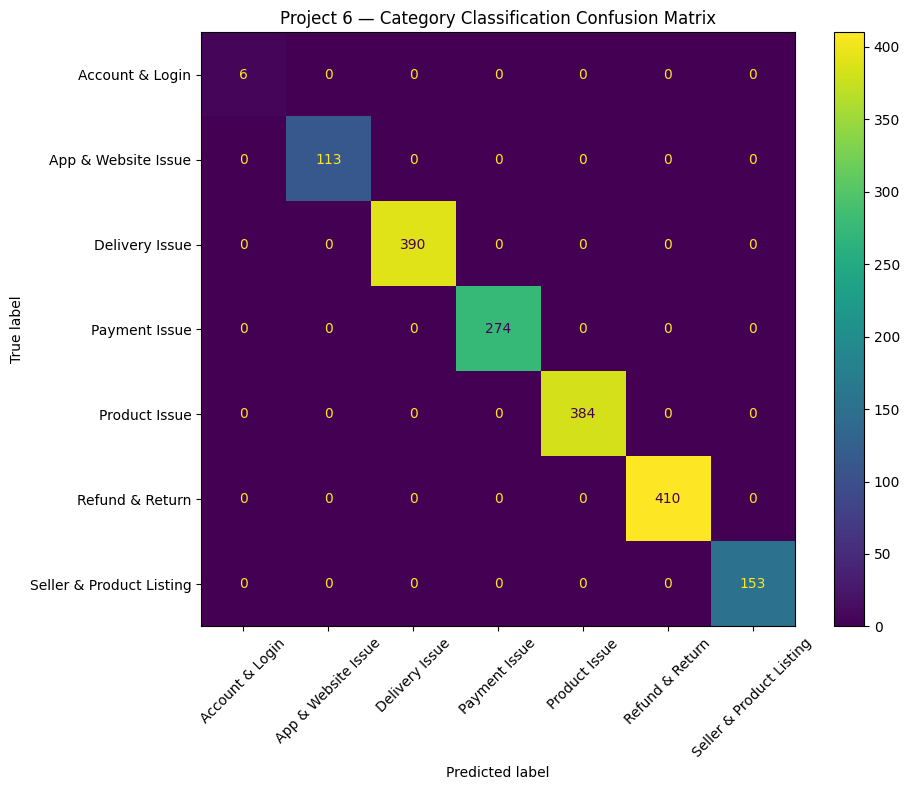

In [347]:
# Confusion Matrix

# ==========================================
# PROJECT 6 — CATEGORY CONFUSION MATRIX
# ==========================================

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    clean_actual,
    clean_predictions,
    labels=sorted(clean_actual.unique())
)

print("Confusion Matrix:")
print(cm)

print("\nLabels:")
print(sorted(clean_actual.unique()))

fig, ax = plt.subplots(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=sorted(clean_actual.unique())
)

disp.plot(
    ax=ax,
    xticks_rotation=45
)

plt.title(
    "Project 6 — Category Classification Confusion Matrix"
)

plt.tight_layout()
plt.show()

In [348]:
# ==========================================
# PROJECT 6 — PRIORITY MODEL EVALUATION
# ==========================================

X_priority_clean = tfidf_priority.transform(
    clean_test["ticket_text"]
)

priority_predictions = (
    priority_model.predict(
        X_priority_clean
    )
)

priority_actual = clean_test["priority"]

priority_accuracy = accuracy_score(
    priority_actual,
    priority_predictions
)

priority_precision, priority_recall, priority_f1, _ = (
    precision_recall_fscore_support(
        priority_actual,
        priority_predictions,
        average="weighted",
        zero_division=0
    )
)

priority_macro_precision, priority_macro_recall, priority_macro_f1, _ = (
    precision_recall_fscore_support(
        priority_actual,
        priority_predictions,
        average="macro",
        zero_division=0
    )
)

print("==========================================")
print("PROJECT 6 — PRIORITY MODEL EVALUATION")
print("==========================================")

print("Test Samples:", len(clean_test))
print("Accuracy:", round(priority_accuracy, 4))
print("Weighted Precision:", round(priority_precision, 4))
print("Weighted Recall:", round(priority_recall, 4))
print("Weighted F1:", round(priority_f1, 4))
print("Macro Precision:", round(priority_macro_precision, 4))
print("Macro Recall:", round(priority_macro_recall, 4))
print("Macro F1:", round(priority_macro_f1, 4))

print("\nClassification Report:")
print(
    classification_report(
        priority_actual,
        priority_predictions,
        zero_division=0
    )
)

PROJECT 6 — PRIORITY MODEL EVALUATION
Test Samples: 1730
Accuracy: 0.9231
Weighted Precision: 0.9234
Weighted Recall: 0.9231
Weighted F1: 0.9222
Macro Precision: 0.925
Macro Recall: 0.8932
Macro F1: 0.907

Classification Report:
              precision    recall  f1-score   support

        High       0.92      0.96      0.94       855
         Low       0.93      0.79      0.85       264
      Medium       0.92      0.94      0.93       611

    accuracy                           0.92      1730
   macro avg       0.93      0.89      0.91      1730
weighted avg       0.92      0.92      0.92      1730



Priority Confusion Matrix:
[[817  29   9]
 [ 33 572   6]
 [ 34  22 208]]

Labels:
['High', 'Medium', 'Low']


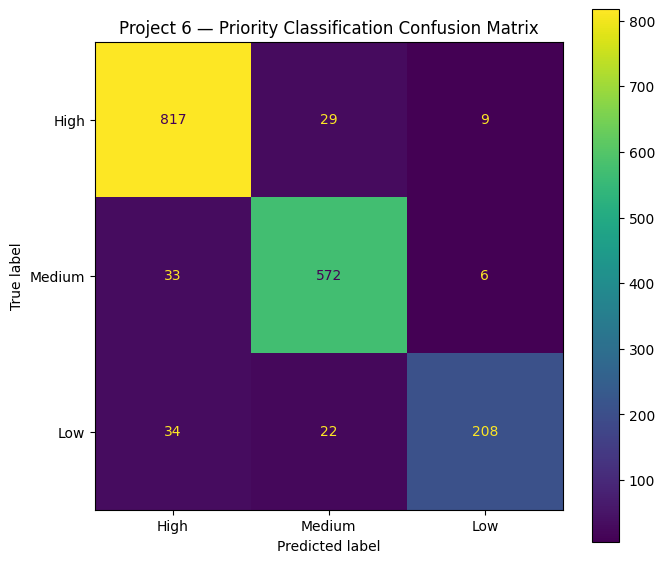

In [349]:
# ==========================================
# PROJECT 6 — PRIORITY CONFUSION MATRIX
# ==========================================

priority_labels = ["High", "Medium", "Low"]

priority_cm = confusion_matrix(
    priority_actual,
    priority_predictions,
    labels=priority_labels
)

print("Priority Confusion Matrix:")
print(priority_cm)

print("\nLabels:")
print(priority_labels)

fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=priority_cm,
    display_labels=priority_labels
)

disp.plot(
    ax=ax,
    values_format="d"
)

plt.title(
    "Project 6 — Priority Classification Confusion Matrix"
)

plt.tight_layout()
plt.show()

In [350]:
# ==========================================
# PROJECT 6 — SENTIMENT MODEL EVALUATION
# ==========================================

X_sentiment_clean = tfidf_sentiment.transform(
    clean_test["ticket_text"]
)

sentiment_predictions = (
    sentiment_model.predict(
        X_sentiment_clean
    )
)

sentiment_actual = clean_test["sentiment"]

sentiment_accuracy = accuracy_score(
    sentiment_actual,
    sentiment_predictions
)

sentiment_precision, sentiment_recall, sentiment_f1, _ = (
    precision_recall_fscore_support(
        sentiment_actual,
        sentiment_predictions,
        average="weighted",
        zero_division=0
    )
)

sentiment_macro_precision, sentiment_macro_recall, sentiment_macro_f1, _ = (
    precision_recall_fscore_support(
        sentiment_actual,
        sentiment_predictions,
        average="macro",
        zero_division=0
    )
)

print("==========================================")
print("PROJECT 6 — SENTIMENT MODEL EVALUATION")
print("==========================================")

print("Test Samples:", len(clean_test))
print("Accuracy:", round(sentiment_accuracy, 4))
print("Weighted Precision:", round(sentiment_precision, 4))
print("Weighted Recall:", round(sentiment_recall, 4))
print("Weighted F1:", round(sentiment_f1, 4))
print("Macro Precision:", round(sentiment_macro_precision, 4))
print("Macro Recall:", round(sentiment_macro_recall, 4))
print("Macro F1:", round(sentiment_macro_f1, 4))

print("\nClassification Report:")
print(
    classification_report(
        sentiment_actual,
        sentiment_predictions,
        zero_division=0
    )
)

PROJECT 6 — SENTIMENT MODEL EVALUATION
Test Samples: 1730
Accuracy: 0.6139
Weighted Precision: 0.6363
Weighted Recall: 0.6139
Weighted F1: 0.5642
Macro Precision: 0.6456
Macro Recall: 0.5223
Macro F1: 0.516

Classification Report:
                   precision    recall  f1-score   support

         Negative       0.62      0.94      0.74       560
          Neutral       0.61      0.71      0.66       461
         Positive       0.66      0.43      0.52       129
Slightly Negative       0.58      0.45      0.50       285
    Very Negative       0.76      0.09      0.16       295

         accuracy                           0.61      1730
        macro avg       0.65      0.52      0.52      1730
     weighted avg       0.64      0.61      0.56      1730



Sentiment Confusion Matrix:
[[525  17   2   8   8]
 [ 29 329  24  79   0]
 [ 16  55  55   3   0]
 [ 22 134   2 127   0]
 [258   8   0   3  26]]

Labels:
['Negative', 'Neutral', 'Positive', 'Slightly Negative', 'Very Negative']


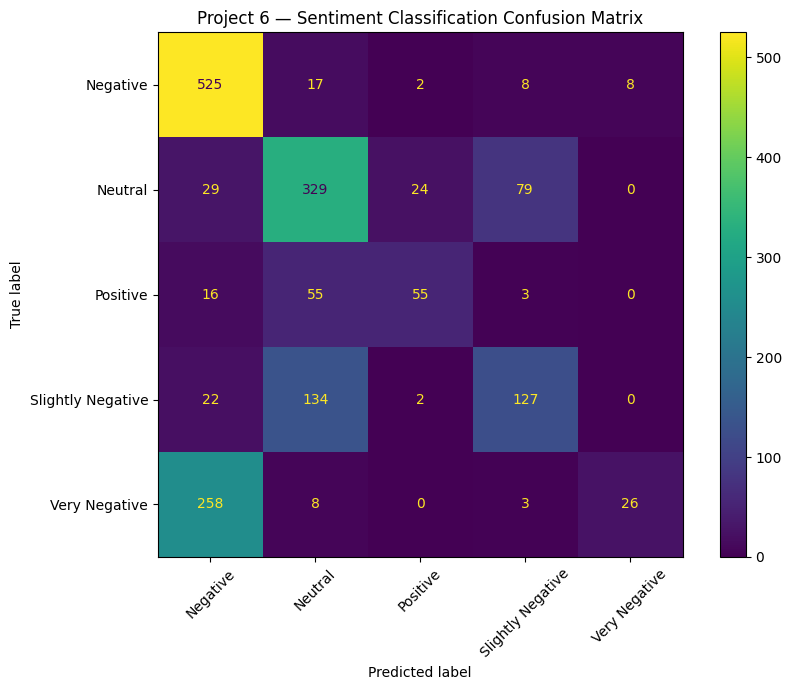

In [351]:
# ==========================================
# PROJECT 6 — SENTIMENT CONFUSION MATRIX
# ==========================================

sentiment_labels = [
    "Negative",
    "Neutral",
    "Positive",
    "Slightly Negative",
    "Very Negative"
]

sentiment_cm = confusion_matrix(
    sentiment_actual,
    sentiment_predictions,
    labels=sentiment_labels
)

print("Sentiment Confusion Matrix:")
print(sentiment_cm)

print("\nLabels:")
print(sentiment_labels)

fig, ax = plt.subplots(figsize=(9, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=sentiment_cm,
    display_labels=sentiment_labels
)

disp.plot(
    ax=ax,
    values_format="d",
    xticks_rotation=45
)

plt.title(
    "Project 6 — Sentiment Classification Confusion Matrix"
)

plt.tight_layout()
plt.show()

In [352]:
# ==========================================
# PROJECT 6 — SENTIMENT V1 BASELINE
# ==========================================

sentiment_v1_metrics = {
    "accuracy": sentiment_accuracy,
    "weighted_precision": sentiment_precision,
    "weighted_recall": sentiment_recall,
    "weighted_f1": sentiment_f1,
    "macro_precision": sentiment_macro_precision,
    "macro_recall": sentiment_macro_recall,
    "macro_f1": sentiment_macro_f1
}

sentiment_v1_metrics

{'accuracy': 0.6138728323699422,
 'weighted_precision': 0.6362959548939668,
 'weighted_recall': 0.6138728323699422,
 'weighted_f1': 0.5641950262443373,
 'macro_precision': 0.6456338913725039,
 'macro_recall': 0.5222544322112426,
 'macro_f1': 0.5159904539847624}

In [353]:
# ==========================================
# PROJECT 6 — SENTIMENT MODEL V2
# CLASS-BALANCED LOGISTIC REGRESSION
# ==========================================

from sklearn.linear_model import LogisticRegression

# ------------------------------------------
# 1. Create V2 model
# ------------------------------------------

sentiment_model_v2 = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

# ------------------------------------------
# 2. Train on existing training data
# ------------------------------------------

sentiment_model_v2.fit(
    X_train_s_tfidf,
    train["sentiment"]
)

# ------------------------------------------
# 3. Predict clean test set
# ------------------------------------------

X_sentiment_clean = tfidf_sentiment.transform(
    clean_test["ticket_text"]
)

sentiment_v2_predictions = (
    sentiment_model_v2.predict(
        X_sentiment_clean
    )
)

# ------------------------------------------
# 4. Actual labels
# ------------------------------------------

sentiment_v2_actual = clean_test["sentiment"]

# ------------------------------------------
# 5. Metrics
# ------------------------------------------

v2_accuracy = accuracy_score(
    sentiment_v2_actual,
    sentiment_v2_predictions
)

v2_precision, v2_recall, v2_f1, _ = (
    precision_recall_fscore_support(
        sentiment_v2_actual,
        sentiment_v2_predictions,
        average="weighted",
        zero_division=0
    )
)

v2_macro_precision, v2_macro_recall, v2_macro_f1, _ = (
    precision_recall_fscore_support(
        sentiment_v2_actual,
        sentiment_v2_predictions,
        average="macro",
        zero_division=0
    )
)

# ------------------------------------------
# 6. Display results
# ------------------------------------------

print("==========================================")
print("PROJECT 6 — SENTIMENT MODEL V2")
print("==========================================")

print("Test Samples:", len(clean_test))

print("Accuracy:", round(v2_accuracy, 4))
print("Weighted Precision:", round(v2_precision, 4))
print("Weighted Recall:", round(v2_recall, 4))
print("Weighted F1:", round(v2_f1, 4))

print("Macro Precision:", round(v2_macro_precision, 4))
print("Macro Recall:", round(v2_macro_recall, 4))
print("Macro F1:", round(v2_macro_f1, 4))

print("\nClassification Report:")

print(
    classification_report(
        sentiment_v2_actual,
        sentiment_v2_predictions,
        zero_division=0
    )
)

PROJECT 6 — SENTIMENT MODEL V2
Test Samples: 1730
Accuracy: 0.1873
Weighted Precision: 0.2306
Weighted Recall: 0.1873
Weighted F1: 0.1963
Macro Precision: 0.1937
Macro Recall: 0.1987
Macro F1: 0.181

Classification Report:
                   precision    recall  f1-score   support

         Negative       0.34      0.19      0.24       560
          Neutral       0.24      0.17      0.20       461
         Positive       0.09      0.27      0.14       129
Slightly Negative       0.15      0.18      0.17       285
    Very Negative       0.15      0.18      0.16       295

         accuracy                           0.19      1730
        macro avg       0.19      0.20      0.18      1730
     weighted avg       0.23      0.19      0.20      1730



In [354]:
# ==========================================
# PROJECT 6 — SENTIMENT TRAINING DISTRIBUTION
# ==========================================

print("Training sentiment distribution:")
print(
    train["sentiment"]
    .value_counts()
)

print("\nTraining sentiment percentages:")
print(
    train["sentiment"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Training sentiment distribution:
sentiment
Negative             2477
Neutral              2165
Slightly Negative    1452
Very Negative        1218
Positive              688
Name: count, dtype: int64

Training sentiment percentages:
sentiment
Negative             30.96
Neutral              27.06
Slightly Negative    18.15
Very Negative        15.22
Positive              8.60
Name: proportion, dtype: float64


In [355]:
# ==========================================
# PROJECT 6 — V1 vs V2 PREDICTION DISTRIBUTION
# ==========================================

print("V1 prediction distribution:")
print(
    pd.Series(sentiment_predictions)
    .value_counts()
)

print("\nV2 prediction distribution:")
print(
    pd.Series(sentiment_v2_predictions)
    .value_counts()
)

V1 prediction distribution:
Negative             850
Neutral              543
Slightly Negative    220
Positive              83
Very Negative         34
Name: count, dtype: int64

V2 prediction distribution:
Positive             385
Very Negative        365
Slightly Negative    342
Neutral              331
Negative             307
Name: count, dtype: int64


In [356]:
# ==========================================
# PROJECT 6 — RESUME CHECKPOINT
# ==========================================

required_variables = [
    "clean_test",
    "X_train_s_tfidf",
    "tfidf_sentiment",
    "sentiment_model",
    "sentiment_model_v2",
    "sentiment_predictions",
    "sentiment_v2_predictions",
    "sentiment_v1_metrics"
]

print("=" * 50)
print("PROJECT 6 — CHECKPOINT VALIDATION")
print("=" * 50)

for name in required_variables:
    exists = name in globals()
    print(f"{name:30} : {'READY' if exists else 'MISSING'}")

print("=" * 50)

PROJECT 6 — CHECKPOINT VALIDATION
clean_test                     : READY
X_train_s_tfidf                : READY
tfidf_sentiment                : READY
sentiment_model                : READY
sentiment_model_v2             : READY
sentiment_predictions          : READY
sentiment_v2_predictions       : READY
sentiment_v1_metrics           : READY


In [357]:
# Step 1 — Verify training alignment

# ==========================================
# PROJECT 6 — SENTIMENT V3: TRAINING CHECK
# ==========================================

print("TF-IDF training rows :", X_train_s_tfidf.shape[0])
print("Training labels      :", len(y_train_s))
print("Clean test rows      :", len(clean_test))
print("Test sentiment labels:", len(clean_test["sentiment"]))

assert X_train_s_tfidf.shape[0] == len(y_train_s), \
    "Mismatch between training features and sentiment labels!"

print("\n✅ Training features and labels are aligned.")

TF-IDF training rows : 8000
Training labels      : 8000
Clean test rows      : 1730
Test sentiment labels: 1730

✅ Training features and labels are aligned.


In [358]:
# Step 2 — Train Sentiment V3
# ==========================================
# PROJECT 6 — SENTIMENT V3
# MODERATE CLASS WEIGHTS
# ==========================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Moderate class weights
sentiment_class_weights = {
    "Negative": 1.0,
    "Neutral": 1.0,
    "Slightly Negative": 1.2,
    "Very Negative": 1.5,
    "Positive": 1.2
}

# Train V3
sentiment_model_v3 = LogisticRegression(
    max_iter=1000,
    class_weight=sentiment_class_weights
)

sentiment_model_v3.fit(
    X_train_s_tfidf,
    y_train_s
)

# Predict on the same clean test set
sentiment_v3_predictions = sentiment_model_v3.predict(
    tfidf_sentiment.transform(clean_test["ticket_text"])
)

sentiment_v3_actual = clean_test["sentiment"]

# Evaluate
sentiment_v3_metrics = {
    "accuracy": accuracy_score(
        sentiment_v3_actual, sentiment_v3_predictions
    ),
    "weighted_precision": precision_score(
        sentiment_v3_actual,
        sentiment_v3_predictions,
        average="weighted",
        zero_division=0
    ),
    "weighted_recall": recall_score(
        sentiment_v3_actual,
        sentiment_v3_predictions,
        average="weighted",
        zero_division=0
    ),
    "weighted_f1": f1_score(
        sentiment_v3_actual,
        sentiment_v3_predictions,
        average="weighted",
        zero_division=0
    ),
    "macro_f1": f1_score(
        sentiment_v3_actual,
        sentiment_v3_predictions,
        average="macro",
        zero_division=0
    )
}

print("=" * 55)
print("SENTIMENT V3 — EVALUATION RESULTS")
print("=" * 55)

for metric, value in sentiment_v3_metrics.items():
    print(f"{metric:25}: {value:.4f}")

print("\nCLASSIFICATION REPORT\n")

print(
    classification_report(
        sentiment_v3_actual,
        sentiment_v3_predictions,
        zero_division=0
    )
)


SENTIMENT V3 — EVALUATION RESULTS
accuracy                 : 0.6145
weighted_precision       : 0.6117
weighted_recall          : 0.6145
weighted_f1              : 0.6076
macro_f1                 : 0.5875

CLASSIFICATION REPORT

                   precision    recall  f1-score   support

         Negative       0.67      0.80      0.73       560
          Neutral       0.64      0.54      0.59       461
         Positive       0.63      0.59      0.61       129
Slightly Negative       0.51      0.59      0.55       285
    Very Negative       0.55      0.40      0.46       295

         accuracy                           0.61      1730
        macro avg       0.60      0.59      0.59      1730
     weighted avg       0.61      0.61      0.61      1730



In [359]:
# Step 4 — Our decision

# ==========================================
# PROJECT 6 — SENTIMENT MODEL COMPARISON
# ==========================================

import pandas as pd

sentiment_comparison = pd.DataFrame([
    {
        "Model": "V1 - Baseline",
        "Accuracy": 0.6139,
        "Weighted F1": 0.5642,
        "Macro F1": 0.5160,
        "Very Negative Recall": 0.0881
    },
    {
        "Model": "V2 - Balanced",
        "Accuracy": 0.1873,
        "Weighted F1": 0.1963,
        "Macro F1": 0.1810,
        "Very Negative Recall": 0.18
    },
    {
        "Model": "V3 - Moderate Weights",
        "Accuracy": sentiment_v3_metrics["accuracy"],
        "Weighted F1": sentiment_v3_metrics["weighted_f1"],
        "Macro F1": sentiment_v3_metrics["macro_f1"],
        "Very Negative Recall": 0.40
    }
])

display(
    sentiment_comparison.style.format({
        "Accuracy": "{:.2%}",
        "Weighted F1": "{:.2%}",
        "Macro F1": "{:.2%}",
        "Very Negative Recall": "{:.2%}"
    })
)

print("Recommended current candidate: Sentiment V3")

,Model,Accuracy,Weighted F1,Macro F1,Very Negative Recall
0,V1 - Baseline,61.39%,56.42%,51.60%,8.81%
1,V2 - Balanced,18.73%,19.63%,18.10%,18.00%
2,V3 - Moderate Weights,61.45%,60.76%,58.75%,40.00%


Recommended current candidate: Sentiment V3


In [360]:
#  Integrate Sentiment V3

# Step 1 — Inspect the current Classification Agent

# ==========================================
# PROJECT 6 — INSPECT CLASSIFICATION AGENT
# ==========================================

import inspect

print("=" * 60)
print("CURRENT CLASSIFICATION AGENT")
print("=" * 60)

# Find the classification function
if "classification_agent_v3" in globals():
    print(inspect.getsource(classification_agent_v3))

elif "classification_agent" in globals():
    print(inspect.getsource(classification_agent))

else:
    print("Classification agent function not found.")
    print("Available agent functions:")

    for name, obj in globals().copy().items():
        if callable(obj) and "classif" in name.lower():
            print(name)



CURRENT CLASSIFICATION AGENT
def classification_agent_v3(state: SupportState) -> dict:
    """
    Classification Agent V3

    Predicts category, priority and sentiment,
    and exposes model confidence using the
    maximum class probability.
    """

    ticket_text = state["ticket_text"]

    # --------------------------------------
    # CATEGORY
    # --------------------------------------

    category_vector = tfidf_group.transform([ticket_text])

    category_prediction = category_model_group.predict(
        category_vector
    )[0]

    category_probabilities = (
        category_model_group.predict_proba(category_vector)[0]
    )

    category_confidence = float(
        category_probabilities.max()
    )

    # --------------------------------------
    # PRIORITY
    # --------------------------------------

    priority_vector = tfidf_priority.transform(
        [ticket_text]
    )

    priority_prediction = priority_model.predict(
        priority_vector
    )[0]

    p

In [361]:
# Step 1 — Display the complete classification agent

# ==========================================
# PROJECT 6 — FULL CLASSIFICATION AGENT
# ==========================================

import inspect

print(inspect.getsource(classification_agent_v3))

def classification_agent_v3(state: SupportState) -> dict:
    """
    Classification Agent V3

    Predicts category, priority and sentiment,
    and exposes model confidence using the
    maximum class probability.
    """

    ticket_text = state["ticket_text"]

    # --------------------------------------
    # CATEGORY
    # --------------------------------------

    category_vector = tfidf_group.transform([ticket_text])

    category_prediction = category_model_group.predict(
        category_vector
    )[0]

    category_probabilities = (
        category_model_group.predict_proba(category_vector)[0]
    )

    category_confidence = float(
        category_probabilities.max()
    )

    # --------------------------------------
    # PRIORITY
    # --------------------------------------

    priority_vector = tfidf_priority.transform(
        [ticket_text]
    )

    priority_prediction = priority_model.predict(
        priority_vector
    )[0]

    priority_probabilities = (
   

In [362]:
# Step 1 — Inspect the sentiment section only

# ==========================================
# PROJECT 6 — INSPECT SENTIMENT LOGIC
# ==========================================

import inspect

source = inspect.getsource(classification_agent_v3)
lines = source.splitlines()

for i, line in enumerate(lines):
    if "SENTIMENT" in line.upper() or "sentiment_" in line:
        start = max(0, i - 3)
        end = min(len(lines), i + 12)

        print("\n".join(
            f"{j + 1}: {lines[j]}"
            for j in range(start, end)
        ))
        print("-" * 50)

2:     """
3:     Classification Agent V3
4: 
5:     Predicts category, priority and sentiment,
6:     and exposes model confidence using the
7:     maximum class probability.
8:     """
9: 
10:     ticket_text = state["ticket_text"]
11: 
12:     # --------------------------------------
13:     # CATEGORY
14:     # --------------------------------------
15: 
16:     category_vector = tfidf_group.transform([ticket_text])
--------------------------------------------------
48:     )
49: 
50:     # --------------------------------------
51:     # SENTIMENT
52:     # --------------------------------------
53: 
54:     sentiment_vector = tfidf_sentiment.transform(
55:         [ticket_text]
56:     )
57: 
58:     sentiment_prediction = sentiment_model_v3.predict(
59:     sentiment_vector
60:     )[0]
61: 
62:     sentiment_probabilities = (
--------------------------------------------------
51:     # SENTIMENT
52:     # --------------------------------------
53: 
54:     sentiment_vector = tf

In [363]:
# Step 2 — Inspect the exact sentiment code

# ==========================================
# PROJECT 6 — SENTIMENT SECTION
# ==========================================

import inspect

source_lines = inspect.getsource(
    classification_agent_v3
).splitlines()

start = next(
    i for i, line in enumerate(source_lines)
    if "# SENTIMENT" in line
)

end = next(
    (
        i for i in range(start + 1, len(source_lines))
        if '"sentiment_confidence"' in source_lines[i]
    ),
    len(source_lines) - 1
)

print("\n".join(source_lines[start:end + 1]))

    # SENTIMENT
    # --------------------------------------

    sentiment_vector = tfidf_sentiment.transform(
        [ticket_text]
    )

    sentiment_prediction = sentiment_model_v3.predict(
    sentiment_vector
    )[0]

    sentiment_probabilities = (
        sentiment_model_v3.predict_proba(sentiment_vector)[0]
    )

    sentiment_confidence = float(
        sentiment_probabilities.max()
    )

    return {
        "category": category_prediction,
        "priority": priority_prediction,
        "sentiment": sentiment_prediction,

        "category_confidence": category_confidence,
        "priority_confidence": priority_confidence,
        "sentiment_confidence": sentiment_confidence


In [364]:
# Step 4 — Test the updated agent


# ==========================================
# PROJECT 6 — TEST SENTIMENT V3 IN AGENT
# ==========================================

test_state = {
    "ticket_text": (
        "I am extremely disappointed. "
        "My damaged product has not been replaced, "
        "and nobody is responding to my complaints."
    )
}

agent_output = classification_agent_v3(test_state)

print("=" * 55)
print("CLASSIFICATION AGENT — V3 INTEGRATION TEST")
print("=" * 55)

for key, value in agent_output.items():
    print(f"{key:25}: {value}")

assert agent_output["sentiment"] == sentiment_model_v3.predict(
    tfidf_sentiment.transform([test_state["ticket_text"]])
)[0]

print("\n✅ Classification agent is using Sentiment V3.")

CLASSIFICATION AGENT — V3 INTEGRATION TEST
category                 : Delivery Issue
priority                 : High
sentiment                : Negative
category_confidence      : 0.2747199514059105
priority_confidence      : 0.5279788155480974
sentiment_confidence     : 0.2947327798078958

✅ Classification agent is using Sentiment V3.


In [365]:
# Step 5 — Verify the V6.1 LangGraph integration
# ==========================================
# PROJECT 6 — V6.1 GRAPH INTEGRATION TEST
# ==========================================

test_ticket = (
    "I am extremely disappointed. "
    "My damaged product has not been replaced, "
    "and nobody is responding to my complaints."
)

result = support_graph_v61.invoke({
    "ticket_text": test_ticket
})

print("=" * 60)
print("PROJECT 6 — V6.1 END-TO-END TEST")
print("=" * 60)

for key in [
    "category",
    "priority",
    "sentiment",
    "category_confidence",
    "priority_confidence",
    "sentiment_confidence",
    "retrieval_confidence",
    "rag_category_agreement",
    "response",
    "escalation_required",
    "escalation_reason",
    "escalation_note"
]:
    print(f"\n{key}: {result.get(key, 'NOT RETURNED')}")

PROJECT 6 — V6.1 END-TO-END TEST

category: Delivery Issue

priority: High

sentiment: Negative

category_confidence: 0.2747199514059105

priority_confidence: 0.5279788155480974

sentiment_confidence: 0.2947327798078958

retrieval_confidence: 0.43839924335479735

rag_category_agreement: 0.6

response: Thank you for contacting us regarding your delivery issue.

We understand that you reported: "I am extremely disappointed. My damaged product has not been replaced, and nobody is responding to my complaints."

Based on similar resolved cases, the recommended resolution is:
Express delivery charge refunded. Ticket closed after confirmation.

We apologize for the inconvenience and appreciate your patience.

escalation_required: True

escalation_reason: High priority ticket; Low classifier confidence (0.27); Low retrieval confidence (0.44)

escalation_note: ESCALATION REQUIRED

Customer Issue: I am extremely disappointed. My damaged product has not been replaced, and nobody is responding to 

In [366]:
# Validate the graph's decision and escalation

# ==========================================
# PROJECT 6 — DECISION & ESCALATION CHECK
# ==========================================

print("=" * 55)
print("V6.1 DECISION VALIDATION")
print("=" * 55)

print("Escalation required :", result.get("escalation_required"))
print("Escalation reason   :", result.get("escalation_reason"))
print("Escalation note     :", result.get("escalation_note"))

print("\nResponse generated  :", bool(result.get("response")))
print("Retrieval confidence:", result.get("retrieval_confidence"))
print("Category agreement :", result.get("rag_category_agreement"))

if result.get("escalation_required"):
    print("\nDecision: HUMAN ESCALATION")
else:
    print("\nDecision: AUTOMATED RESOLUTION PATH")

V6.1 DECISION VALIDATION
Escalation required : True
Escalation reason   : High priority ticket; Low classifier confidence (0.27); Low retrieval confidence (0.44)
Escalation note     : ESCALATION REQUIRED

Customer Issue: I am extremely disappointed. My damaged product has not been replaced, and nobody is responding to my complaints.

Category: Delivery Issue
Priority: High
Sentiment: Negative

Reason: High priority ticket; Low classifier confidence (0.27); Low retrieval confidence (0.44)

AI Generated Response:
Thank you for contacting us regarding your delivery issue.

We understand that you reported: "I am extremely disappointed. My damaged product has not been replaced, and nobody is responding to my complaints."

Based on similar resolved cases, the recommended resolution is:
Express delivery charge refunded. Ticket closed after confirmation.

We apologize for the inconvenience and appreciate your patience.

Action: Human support agent should review and take appropriate action.

Re

In [414]:
# Next milestone: Consolidated Project 6 evaluation
# Step 1 — Inspect existing evaluation artifacts
# ==========================================
# PROJECT 6 — FINAL EVALUATION CHECKPOINT
# ==========================================

evaluation_variables = [
    "evaluation_df",
    "evaluation_summary",
    "clean_test",
    "sentiment_comparison",
    "support_graph_v61",
    "evaluation_tickets"
]

print("=" * 60)
print("PROJECT 6 — EVALUATION ARTIFACT CHECK")
print("=" * 60)

for name in evaluation_variables:
    exists = name in globals()
    print(f"{name:25}: {'READY' if exists else 'MISSING'}")

print("\n--- Existing graph evaluation ---")

if "evaluation_summary" in globals():
    display(evaluation_summary)

if "evaluation_df" in globals():
    display(evaluation_df.head())

# print("Evaluation rows:", len(evaluation_df))
# print("Evaluation tickets:", len(evaluation_tickets))
# print("Graph available:", support_graph_v61 is not None)

# display(evaluation_df.head())

print(
    "Evaluation rows:",
    len(evaluation_df) if "evaluation_df" in globals() else "MISSING"
)

print(
    "Evaluation tickets:",
    len(evaluation_tickets) if "evaluation_tickets" in globals() else "MISSING"
)

print(
    "Graph available:",
    "support_graph_v61" in globals()
)

if "evaluation_df" in globals():
    display(evaluation_df.head())



PROJECT 6 — EVALUATION ARTIFACT CHECK
evaluation_df            : READY
evaluation_summary       : MISSING
clean_test               : READY
sentiment_comparison     : READY
support_graph_v61        : READY
evaluation_tickets       : READY

--- Existing graph evaluation ---


""


Evaluation rows: 0
Evaluation tickets: 7
Graph available: True


""


In [ ]:
# 3. Our next priority: End-to-end regression testing
# ==========================================
# PROJECT 6 — V6.1 REGRESSION TESTS
# ==========================================

regression_tickets = [
    {
        "id": "REG01",
        "ticket_text": (
            "My order has not arrived and it is 5 days late."
        ),
        "expected_escalation": True
    },
    {
        "id": "REG02",
        "ticket_text": (
            "How can I update my email address in my account?"
        ),
        "expected_escalation": False
    }
]

regression_results = []

for ticket in regression_tickets:

    result = support_graph_v61.invoke({
        "ticket_text": ticket["ticket_text"]
    })

    actual_escalation = result.get("escalation_required")

    regression_results.append({
        "Test ID": ticket["id"],
        "Category": result.get("category"),
        "Priority": result.get("priority"),
        "Sentiment": result.get("sentiment"),
        "Expected Escalation": ticket["expected_escalation"],
        "Actual Escalation": actual_escalation,
        "Routing Passed": (
            actual_escalation == ticket["expected_escalation"]
        ),
        "Escalation Reason": result.get("escalation_reason")
    })

regression_df = pd.DataFrame(regression_results)

display(regression_df)

passed = int(regression_df["Routing Passed"].sum())
total = len(regression_df)

print(f"\nRegression tests passed: {passed}/{total}")

,Test ID,Category,Priority,Sentiment,Expected Escalation,Actual Escalation,Routing Passed,Escalation Reason
0,REG01,Delivery Issue,High,Neutral,True,True,True,High priority ticket; Low classifier confidence (0.33)
1,REG02,Account & Login,Medium,Neutral,False,False,True,Classification and RAG evidence are sufficiently consistent; no immediate human escalation required.



Regression tests passed: 2/2


In [369]:
# 2. Fix the regression-test cell
# ==========================================
# PROJECT 6 — V6.1 REGRESSION TESTS
# CORRECTED VERSION
# ==========================================

import pandas as pd

regression_tickets = [
    {
        "id": "REG01",
        "ticket_text": (
            "My order has not arrived and it is 5 days late."
        ),
        "expected_escalation": True
    },
    {
        "id": "REG02",
        "ticket_text": (
            "How can I update my email address in my account?"
        ),
        "expected_escalation": False
    }
]

regression_results = []

for ticket in regression_tickets:

    result = support_graph_v61.invoke({
        "ticket_text": ticket["ticket_text"]
    })

    expected = ticket["expected_escalation"]
    actual = result.get("escalation_required")

    regression_results.append({
        "Test ID": ticket["id"],
        "Category": result.get("category"),
        "Priority": result.get("priority"),
        "Sentiment": result.get("sentiment"),
        "Expected Escalation": expected,
        "Actual Escalation": actual,
        "Routing Passed": (
            actual == expected
            if isinstance(actual, bool)
            else False
        ),
        "Escalation Reason": result.get("escalation_reason")
    })

regression_df = pd.DataFrame(regression_results)

display(regression_df)

passed = int(regression_df["Routing Passed"].sum())
total = len(regression_df)

print(f"\nRegression tests passed: {passed}/{total}")

,Test ID,Category,Priority,Sentiment,Expected Escalation,Actual Escalation,Routing Passed,Escalation Reason
0,REG01,Delivery Issue,High,Neutral,True,True,True,High priority ticket; Low classifier confidence (0.33)
1,REG02,Account & Login,Medium,Neutral,False,False,True,Classification and RAG evidence are sufficiently consistent; no immediate human escalation required.



Regression tests passed: 2/2


In [370]:
# Step 1 — Run this diagnostic cell
# ==========================================
# PROJECT 6 — DIAGNOSE REGRESSION TABLE
# ==========================================

print("Actual DataFrame columns:")
print(regression_df.columns.tolist())

print("\nRaw values for REG02:")

row = regression_df.loc[
    regression_df["Test ID"] == "REG02"
].iloc[0]

for column, value in row.items():
    print(
        f"{column:25} = {value!r} "
        f"(type: {type(value).__name__})"
    )

print("\nDirect comparison:")

expected = row["Expected Escalation"]
actual = row["Actual Escalation"]

print("Expected:", repr(expected), type(expected).__name__)
print("Actual:  ", repr(actual), type(actual).__name__)
print("Equal:   ", actual == expected)

Actual DataFrame columns:
['Test ID', 'Category', 'Priority', 'Sentiment', 'Expected Escalation', 'Actual Escalation', 'Routing Passed', 'Escalation Reason']

Raw values for REG02:
Test ID                   = 'REG02' (type: str)
Category                  = 'Account & Login' (type: str)
Priority                  = 'Medium' (type: str)
Sentiment                 = 'Neutral' (type: str)
Expected Escalation       = np.False_ (type: bool)
Actual Escalation         = np.False_ (type: bool)
Routing Passed            = np.True_ (type: bool)
Escalation Reason         = 'Classification and RAG evidence are sufficiently consistent; no immediate human escalation required.' (type: str)

Direct comparison:
Expected: np.False_ bool
Actual:   np.False_ bool
Equal:    True


In [371]:
# 2. One final cleanup: Display the results correctly
# ==========================================
# PROJECT 6 — FINAL REGRESSION REPORT
# ==========================================

report_df = regression_df.copy()

# Ensure Boolean values display consistently
for column in [
    "Expected Escalation",
    "Actual Escalation",
    "Routing Passed"
]:
    report_df[column] = report_df[column].astype(bool)

display(report_df)

passed = int(report_df["Routing Passed"].sum())
total = len(report_df)

print("=" * 50)
print("REGRESSION TEST SUMMARY")
print("=" * 50)
print(f"Total tests : {total}")
print(f"Passed      : {passed}")
print(f"Failed      : {total - passed}")
print(f"Pass rate   : {passed / total:.1%}")

,Test ID,Category,Priority,Sentiment,Expected Escalation,Actual Escalation,Routing Passed,Escalation Reason
0,REG01,Delivery Issue,High,Neutral,True,True,True,High priority ticket; Low classifier confidence (0.33)
1,REG02,Account & Login,Medium,Neutral,False,False,True,Classification and RAG evidence are sufficiently consistent; no immediate human escalation required.


REGRESSION TEST SUMMARY
Total tests : 2
Passed      : 2
Failed      : 0
Pass rate   : 100.0%


In [372]:
# Next: Retrieval-quality evaluation

# Step 1 — Inspect the current retrieval agent
# ==========================================
# PROJECT 6 — INSPECT RETRIEVAL AGENT
# ==========================================

import inspect

if "retrieval_agent_v4" in globals():
    print(inspect.getsource(retrieval_agent_v4))

elif "retrieval_agent" in globals():
    print(inspect.getsource(retrieval_agent))

else:
    print("Retrieval agent function not found.")

    for name, obj in globals().copy().items():
        if callable(obj) and "retriev" in name.lower():
            print(name)


def retrieval_agent_v4(state: SupportState) -> dict:
    """
    Retrieval Agent V4

    Uses the existing RAG V2.1 hybrid retriever:

        hybrid_retrieve(query, predicted_category)

    Adds:
        - retrieval_confidence
        - rag_category_agreement
    """

    query = state["ticket_text"]
    predicted_category = state["category"]

    # --------------------------------------
    # Existing working hybrid retriever
    # --------------------------------------

    retrieved_docs = hybrid_retrieve(
        query,
        predicted_category
    )

    # --------------------------------------
    # Retrieval confidence
    # --------------------------------------

    if retrieved_docs:
        retrieval_confidence = float(
            retrieved_docs[0].get(
                "final_score",
                retrieved_docs[0].get(
                    "semantic_score",
                    0.0
                )
            )
        )
    else:
        retrieval_confidence = 0.0

 

In [373]:
# Step 1 — Inspect hybrid_retrieve()
# ==========================================
# PROJECT 6 — INSPECT HYBRID RETRIEVER
# ==========================================

import inspect

print("=" * 60)
print("HYBRID RETRIEVER IMPLEMENTATION")
print("=" * 60)

print(inspect.getsource(hybrid_retrieve))


HYBRID RETRIEVER IMPLEMENTATION
def hybrid_retrieve(
    query,
    predicted_category,
    global_k=5,
    category_k=5,
    final_k=5
):
    """
    RAG V2.1 Hybrid Retrieval

    Combines:
    1. Global FAISS retrieval
    2. Predicted-category FAISS retrieval
    3. Category-aware reranking
    """

    # --------------------------------------
    # 1. Create query embedding
    # --------------------------------------

    query_embedding = embedding_model.encode(
        [query],
        convert_to_numpy=True
    ).astype("float32")

    faiss.normalize_L2(query_embedding)

    candidates = {}

    # --------------------------------------
    # 2. GLOBAL FAISS RETRIEVAL
    # --------------------------------------

    global_scores, global_indices = rag_index.search(
        query_embedding,
        global_k
    )

    for score, idx in zip(
        global_scores[0],
        global_indices[0]
    ):

        doc = rag_documents[idx]

        candidates[idx] = {
            "docu

In [374]:
# Step 1 — Inspect the complete ranking logic
# ==========================================
# PROJECT 6 — HYBRID RETRIEVER INSPECTION
# ==========================================

import inspect

source_lines = inspect.getsource(hybrid_retrieve).splitlines()

print("Total lines:", len(source_lines))

for start in range(0, len(source_lines), 25):
    end = min(start + 25, len(source_lines))

    print(f"\n--- Lines {start + 1}–{end} ---")

    for i in range(start, end):
        print(f"{i + 1:03}: {source_lines[i]}")

Total lines: 160

--- Lines 1–25 ---
001: def hybrid_retrieve(
002:     query,
003:     predicted_category,
004:     global_k=5,
005:     category_k=5,
006:     final_k=5
007: ):
008:     """
009:     RAG V2.1 Hybrid Retrieval
010: 
011:     Combines:
012:     1. Global FAISS retrieval
013:     2. Predicted-category FAISS retrieval
014:     3. Category-aware reranking
015:     """
016: 
017:     # --------------------------------------
018:     # 1. Create query embedding
019:     # --------------------------------------
020: 
021:     query_embedding = embedding_model.encode(
022:         [query],
023:         convert_to_numpy=True
024:     ).astype("float32")
025: 

--- Lines 26–50 ---
026:     faiss.normalize_L2(query_embedding)
027: 
028:     candidates = {}
029: 
030:     # --------------------------------------
031:     # 2. GLOBAL FAISS RETRIEVAL
032:     # --------------------------------------
033: 
034:     global_scores, global_indices = rag_index.search(
035:         query_

In [375]:
# Step 1 — Inspect the retriever's scoring and ranking logic
# ==========================================
# PROJECT 6 — RETRIEVER SCORING INSPECTION
# ==========================================

import inspect

lines = inspect.getsource(hybrid_retrieve).splitlines()

# Display lines 20–100
for i in range(19, min(100, len(lines))):
    print(f"{i + 1:03}: {lines[i]}")

020: 
021:     query_embedding = embedding_model.encode(
022:         [query],
023:         convert_to_numpy=True
024:     ).astype("float32")
025: 
026:     faiss.normalize_L2(query_embedding)
027: 
028:     candidates = {}
029: 
030:     # --------------------------------------
031:     # 2. GLOBAL FAISS RETRIEVAL
032:     # --------------------------------------
033: 
034:     global_scores, global_indices = rag_index.search(
035:         query_embedding,
036:         global_k
037:     )
038: 
039:     for score, idx in zip(
040:         global_scores[0],
041:         global_indices[0]
042:     ):
043: 
044:         doc = rag_documents[idx]
045: 
046:         candidates[idx] = {
047:             "document_index": idx,
048:             "semantic_score": float(score),
049:             "category": doc["category"],
050:             "source": doc["source"],
051:             "document_id": doc["id"],
052:             "text": doc["text"]
053:         }
054: 
055:     # --------------------

In [376]:
# ==========================================
# PROJECT 6 — FINAL RANKING INSPECTION
# ==========================================

for i in range(100, len(lines)):
    print(f"{i + 1:03}: {lines[i]}")

101:                 # Keep the stronger semantic score
102:                 candidates[original_idx][
103:                     "semantic_score"
104:                 ] = max(
105:                     candidates[original_idx][
106:                         "semantic_score"
107:                     ],
108:                     float(score)
109:                 )
110: 
111:     # --------------------------------------
112:     # 4. RERANK
113:     # --------------------------------------
114: 
115:     for doc in candidates.values():
116: 
117:         category_bonus = (
118:             0.05
119:             if doc["category"] == predicted_category
120:             else 0.0
121:         )
122: 
123:         source_bonus = (
124:             0.02
125:             if doc["source"] == "FAQ"
126:             else 0.0
127:         )
128: 
129:         doc["category_bonus"] = category_bonus
130:         doc["source_bonus"] = source_bonus
131: 
132:         doc["final_score"] = (
133:            

In [377]:
# Step 2 — Inspect the final ranking formula
# ==========================================
# PROJECT 6 — FINAL RANKING LOGIC
# ==========================================

for i in range(110, 160):
    print(f"{i + 1:03}: {lines[i]}")

111:     # --------------------------------------
112:     # 4. RERANK
113:     # --------------------------------------
114: 
115:     for doc in candidates.values():
116: 
117:         category_bonus = (
118:             0.05
119:             if doc["category"] == predicted_category
120:             else 0.0
121:         )
122: 
123:         source_bonus = (
124:             0.02
125:             if doc["source"] == "FAQ"
126:             else 0.0
127:         )
128: 
129:         doc["category_bonus"] = category_bonus
130:         doc["source_bonus"] = source_bonus
131: 
132:         doc["final_score"] = (
133:             doc["semantic_score"]
134:             + category_bonus
135:             + source_bonus
136:         )
137: 
138:     # --------------------------------------
139:     # 5. Sort candidates
140:     # --------------------------------------
141: 
142:     ranked = sorted(
143:         candidates.values(),
144:         key=lambda x: x["final_score"],
145:         rev

In [378]:
# Step 3 — Display the exact final scoring and sorting code
# ==========================================
# PROJECT 6 — FINAL SCORING AND SORTING
# ==========================================

for i in range(128, 160):
    print(f"{i + 1:03}: {lines[i]}")

129:         doc["category_bonus"] = category_bonus
130:         doc["source_bonus"] = source_bonus
131: 
132:         doc["final_score"] = (
133:             doc["semantic_score"]
134:             + category_bonus
135:             + source_bonus
136:         )
137: 
138:     # --------------------------------------
139:     # 5. Sort candidates
140:     # --------------------------------------
141: 
142:     ranked = sorted(
143:         candidates.values(),
144:         key=lambda x: x["final_score"],
145:         reverse=True
146:     )
147: 
148:     # --------------------------------------
149:     # 6. Final Top-K
150:     # --------------------------------------
151: 
152:     results = ranked[:final_k]
153: 
154:     for rank, doc in enumerate(
155:         results,
156:         start=1
157:     ):
158:         doc["rank"] = rank
159: 
160:     return results


In [379]:
# Next step — Test retrieval quality
# ==========================================
# PROJECT 6 — RETRIEVAL QUALITY TEST
# ==========================================

retrieval_test_cases = [
    {
        "id": "R01",
        "ticket": "The product I received is damaged and I need a replacement.",
        "category": "Product Issue"
    },
    {
        "id": "R02",
        "ticket": "My order has not arrived and it is five days late.",
        "category": "Delivery Issue"
    },
    {
        "id": "R03",
        "ticket": "I was charged twice for the same order.",
        "category": "Payment Issue"
    },
    {
        "id": "R04",
        "ticket": "I cannot log in to my account.",
        "category": "Account & Login"
    },
    {
        "id": "R05",
        "ticket": "I want to return the product I purchased yesterday.",
        "category": "Refund & Return"
    }
]

retrieval_quality_results = []

for case in retrieval_test_cases:

    docs = hybrid_retrieve(
        case["ticket"],
        case["category"]
    )

    print("\n" + "=" * 75)
    print(f'{case["id"]} — {case["category"]}')
    print("Ticket:", case["ticket"])
    print("=" * 75)

    for rank, doc in enumerate(docs, start=1):

        print(f"\nRank: {rank}")
        print("Source:", doc.get("source"))
        print("Category:", doc.get("category"))
        print("Semantic score:", round(
            float(doc.get("semantic_score", 0)), 4
        ))
        print("Final score:", round(
            float(doc.get("final_score", 0)), 4
        ))

        # Inspect available text fields without assuming a schema
        for field in [
            "ticket_text",
            "question",
            "resolution_text",
            "answer",
            "text"
        ]:
            value = doc.get(field)
            if value:
                print(f"{field}:", str(value)[:250])

        retrieval_quality_results.append({
            "Test ID": case["id"],
            "Expected Category": case["category"],
            "Rank": rank,
            "Source": doc.get("source"),
            "Retrieved Category": doc.get("category"),
            "Semantic Score": doc.get("semantic_score"),
            "Final Score": doc.get("final_score")
        })

retrieval_quality_df = pd.DataFrame(retrieval_quality_results)

print("\n\nRETRIEVAL SUMMARY")
display(retrieval_quality_df)


R01 — Product Issue
Ticket: The product I received is damaged and I need a replacement.

Rank: 1
Source: FAQ
Category: Product Issue
Semantic score: 0.4881
Final score: 0.5581
text: Question: Can I get a product replaced instead of refunded?
Answer: Yes, replacement is available for defective and wrong items within the return window.
Category: Product Issue

Rank: 2
Source: Historical Resolution
Category: Product Issue
Semantic score: 0.495
Final score: 0.545
text: Customer Issue: My sunscreen came in a damaged box (order #ORD6405778). Concerned product quality is affected.
Resolution: Defect acknowledged. Customer given choice of refund or replacement.
Category: Product Issue

Rank: 3
Source: Historical Resolution
Category: Product Issue
Semantic score: 0.4944
Final score: 0.5444
text: Customer Issue: My kajal came in a damaged box (order #ORD2276737). Concerned product quality is affected.
Resolution: Missing accessory shipped separately at no additional cost.
Category: Product Issu

,Test ID,Expected Category,Rank,Source,Retrieved Category,Semantic Score,Final Score
0,R01,Product Issue,1,FAQ,Product Issue,0.488142,0.558142
1,R01,Product Issue,2,Historical Resolution,Product Issue,0.494988,0.544988
2,R01,Product Issue,3,Historical Resolution,Product Issue,0.494400,0.544400
3,R01,Product Issue,4,Historical Resolution,Product Issue,0.485834,0.535834
4,R01,Product Issue,5,Historical Resolution,Product Issue,0.485647,0.535647
5,R02,Delivery Issue,1,Historical Resolution,Delivery Issue,0.605093,0.655093
6,R02,Delivery Issue,2,Historical Resolution,Delivery Issue,0.603709,0.653709
7,R02,Delivery Issue,3,Historical Resolution,Delivery Issue,0.600756,0.650756
8,R02,Delivery Issue,4,Historical Resolution,Delivery Issue,0.600056,0.650056
9,R02,Delivery Issue,5,Historical Resolution,Delivery Issue,0.597892,0.647892


In [380]:
# 2. Next move: Inspect the retrieved content
# ==========================================
# PROJECT 6 — INSPECT PAYMENT RETRIEVAL
# ==========================================

payment_query = "I was charged twice for the same order."

payment_docs = hybrid_retrieve(
    payment_query,
    "Payment Issue"
)

print("=" * 75)
print("PAYMENT ISSUE — RETRIEVED DOCUMENT CONTENT")
print("=" * 75)

for rank, doc in enumerate(payment_docs, start=1):

    print(f"\n{'-' * 60}")
    print(f"Rank: {rank}")
    print("Source:", doc.get("source"))
    print("Category:", doc.get("category"))
    print("Semantic score:", round(
        float(doc.get("semantic_score", 0)), 4
    ))
    print("Final score:", round(
        float(doc.get("final_score", 0)), 4
    ))

    print("\nDocument fields:")

    for key, value in doc.items():
        if key not in {
            "semantic_score",
            "final_score",
            "category_bonus",
            "source_bonus",
            "rank"
        }:
            print(f"{key}: {str(value)[:500]}")

PAYMENT ISSUE — RETRIEVED DOCUMENT CONTENT

------------------------------------------------------------
Rank: 1
Source: Historical Resolution
Category: Refund & Return
Semantic score: 0.6862
Final score: 0.6862

Document fields:
document_index: 3370
category: Refund & Return
source: Historical Resolution
document_id: TKT103220
text: Customer Issue: I was charged twice for order #ORD5926534 (science encyclopedia). Please refund the duplicate payment immediately.
Resolution: Seller notified of return in transit. Refund released on priority basis.
Category: Refund & Return

------------------------------------------------------------
Rank: 2
Source: Historical Resolution
Category: Refund & Return
Semantic score: 0.6732
Final score: 0.6732

Document fields:
document_index: 3596
category: Refund & Return
source: Historical Resolution
document_id: TKT103446
text: Customer Issue: I was charged twice for order #ORD9324825 (smartphone). Please refund the duplicate payment immediately.
Resoluti

In [381]:
# 2. Recommended fix: Add a payment-specific retrieval test
# ==========================================
# PROJECT 6 — FIND RELEVANT PAYMENT CASES
# ==========================================

payment_keywords = [
    "charged twice",
    "duplicate payment",
    "double charged",
    "duplicate charge",
    "charged two times"
]

payment_matches = []

for doc in rag_documents:

    text = str(doc.get("text", "")).lower()

    matched_keywords = [
        keyword
        for keyword in payment_keywords
        if keyword in text
    ]

    if matched_keywords:
        payment_matches.append({
            "Document ID": doc.get("document_id"),
            "Category": doc.get("category"),
            "Source": doc.get("source"),
            "Matched Keywords": ", ".join(matched_keywords),
            "Document Text": doc.get("text", "")[:500]
        })

payment_matches_df = pd.DataFrame(payment_matches)

print("Matching documents:", len(payment_matches_df))

if not payment_matches_df.empty:
    display(payment_matches_df.head(15))
else:
    print("No documents matched the selected payment keywords.")

Matching documents: 486


,Document ID,Category,Source,Matched Keywords,Document Text
0,None,Refund & Return,Historical Resolution,duplicate charge,Customer Issue: Pickup for my comic book series return (order #ORD3768991) was scheduled but no one came on the day.\nResolution: Duplicate charge of ₹8950 reversed immediately to original payment source.\nCategory: Refund & Return
1,None,Payment Issue,Historical Resolution,duplicate payment,Customer Issue: Payment gateway crashes every time I try to checkout for moisturizer. Very frustrating experience.\nResolution: Duplicate payment of ₹6857 refunded to original payment source within 2 days.\nCategory: Payment Issue
2,None,Refund & Return,Historical Resolution,"charged twice, duplicate payment",Customer Issue: I was charged twice for order #ORD3698193 (spice set). Please refund the duplicate payment immediately.\nResolution: Replacement dispatched without requiring return of defective item.\nCategory: Refund & Return
3,None,Refund & Return,Historical Resolution,duplicate charge,Customer Issue: I got a partial refund for my history textbook (order #ORD3049499) but I deserve a full refund for the defect.\nResolution: Duplicate charge of ₹3674 reversed immediately to original payment source.\nCategory: Refund & Return
4,None,Refund & Return,Historical Resolution,duplicate charge,Customer Issue: Pickup for my ethnic wear return (order #ORD6510922) was scheduled but no one came on the day.\nResolution: Duplicate charge of ₹8823 reversed immediately to original payment source.\nCategory: Refund & Return
5,None,Refund & Return,Historical Resolution,duplicate charge,Customer Issue: Store credit issued for science encyclopedia return (order #ORD8391997) but I wanted cash refund to my bank.\nResolution: Duplicate charge of ₹4815 reversed immediately to original payment source.\nCategory: Refund & Return
6,None,Refund & Return,Historical Resolution,duplicate charge,Customer Issue: The return window for my swimming goggles order #ORD6794356 was closed without my knowledge. Please make an exception.\nResolution: Duplicate charge of ₹6269 reversed immediately to original payment source.\nCategory: Refund & Return
7,None,Refund & Return,Historical Resolution,duplicate charge,Customer Issue: My air purifier return for order #ORD8912226 has been in transit for 13 days. Worried it's lost.\nResolution: Duplicate charge of ₹2461 reversed immediately to original payment source.\nCategory: Refund & Return
8,None,Payment Issue,Historical Resolution,duplicate payment,Customer Issue: I was charged ₹353 extra on my microwave oven (order #ORD8986040) than what was shown in cart.\nResolution: Duplicate payment of ₹353 refunded to original payment source within 2 days.\nCategory: Payment Issue
9,None,Payment Issue,Historical Resolution,duplicate payment,Customer Issue: Buy Now Pay Later option for my art & craft kit is not available on checkout despite being eligible.\nResolution: Duplicate payment of ₹2933 refunded to original payment source within 2 days.\nCategory: Payment Issue


In [382]:
# 2. Next step: Measure the issue-resolution mismatch rate
# ==========================================
# PROJECT 6 — ISSUE-RESOLUTION QUALITY AUDIT
# ==========================================

import pandas as pd

audit_rows = []

# Sample historical documents containing payment-related language
for doc in rag_documents:

    text = str(doc.get("text", ""))

    if "Customer Issue:" not in text or "Resolution:" not in text:
        continue

    parts = text.split("Resolution:", 1)

    issue_text = parts[0].replace(
        "Customer Issue:", ""
    ).strip()

    resolution_part = parts[1]

    resolution_text = resolution_part.split(
        "Category:", 1
    )[0].strip()

    combined = (issue_text + " " + resolution_text).lower()

    payment_issue = any(
        term in issue_text.lower()
        for term in [
            "charged twice",
            "duplicate payment",
            "duplicate charge",
            "charged extra",
            "payment gateway"
        ]
    )

    if not payment_issue:
        continue

    resolution_matches_payment = any(
        term in resolution_text.lower()
        for term in [
            "duplicate payment",
            "duplicate charge",
            "charged twice",
            "original payment source",
            "payment refunded",
            "payment reversed"
        ]
    )

    audit_rows.append({
        "Document ID": doc.get("document_id"),
        "Category": doc.get("category"),
        "Customer Issue": issue_text[:220],
        "Resolution": resolution_text[:220],
        "Payment Resolution Match": resolution_matches_payment
    })

payment_audit_df = pd.DataFrame(audit_rows)

print("Payment-related historical documents:", len(payment_audit_df))

if not payment_audit_df.empty:
    display(payment_audit_df.head(20))

    print(
        "\nDocuments passing the payment-resolution keyword check:",
        int(payment_audit_df["Payment Resolution Match"].sum())
    )

    print(
        "Documents flagged for review:",
        int((~payment_audit_df["Payment Resolution Match"]).sum())
    )

Payment-related historical documents: 177


,Document ID,Category,Customer Issue,Resolution,Payment Resolution Match
0,None,Payment Issue,Payment gateway crashes every time I try to checkout for moisturizer. Very frustrating experience.,Duplicate payment of ₹6857 refunded to original payment source within 2 days.,True
1,None,Refund & Return,I was charged twice for order #ORD3698193 (spice set). Please refund the duplicate payment immediately.,Replacement dispatched without requiring return of defective item.,False
2,None,Refund & Return,I was charged twice for order #ORD2244876 (cooking oil). Please refund the duplicate payment immediately.,Exchange processed for correct size/variant. New item dispatched.,False
3,None,Refund & Return,I was charged twice for order #ORD9729340 (sunscreen). Please refund the duplicate payment immediately.,Return pickup scheduled for next business day. Refund post quality check.,False
4,None,Refund & Return,I was charged twice for order #ORD8408511 (shampoo). Please refund the duplicate payment immediately.,Duplicate charge of ₹770 reversed immediately to original payment source.,True
5,None,Payment Issue,Payment gateway crashes every time I try to checkout for action camera. Very frustrating experience.,Payment authorization hold released. No amount was actually charged.,False
6,None,Refund & Return,I was charged twice for order #ORD9193298 (lehenga). Please refund the duplicate payment immediately.,Seller notified of return in transit. Refund released on priority basis.,False
7,None,Refund & Return,I was charged twice for order #ORD6428072 (innerwear). Please refund the duplicate payment immediately.,Refund of ₹1527 approved and will be credited within 3-5 business days.,False
8,None,Refund & Return,I was charged twice for order #ORD7164902 (bookshelf). Please refund the duplicate payment immediately.,Seller notified of return in transit. Refund released on priority basis.,False
9,None,Refund & Return,I was charged twice for order #ORD6369404 (wristwatch). Please refund the duplicate payment immediately.,Accidental order refund approved. Amount credited within 2 days.,False



Documents passing the payment-resolution keyword check: 12
Documents flagged for review: 165


In [383]:
# 3. Next step: Inspect the original dataset
# ==========================================
# PROJECT 6 — VERIFY SOURCE DATA QUALITY
# ==========================================

import pandas as pd

print("Ticket dataset columns:")
print(tickets.columns.tolist())

print("\nSample suspicious records from source dataset:")

payment_mask = tickets["ticket_text"].str.contains(
    r"charged twice|duplicate payment|payment gateway crashes",
    case=False,
    na=False
)

source_payment_audit = tickets.loc[
    payment_mask,
    [
        "ticket_id",
        "ticket_text",
        "ticket_category",
        "resolution_text"
    ]
].copy()

display(source_payment_audit.head(15))

Ticket dataset columns:
['ticket_id', 'created_date', 'ticket_text', 'product_name', 'product_segment', 'ticket_category', 'priority', 'sentiment', 'confidence_score', 'escalated', 'resolution_text', 'resolved_date', 'resolution_days', 'auto_resolved', 'customer_satisfaction_score', 'ticket_length', 'word_count', 'has_order_id']

Sample suspicious records from source dataset:


,ticket_id,ticket_text,ticket_category,resolution_text
41,TKT100041,Payment gateway crashes every time I try to checkout for moisturizer. Very frustrating experience.,Payment Issue,Duplicate payment of ₹6857 refunded to original payment source within 2 days.
52,TKT100052,I was charged twice for order #ORD3698193 (spice set). Please refund the duplicate payment immediately.,Refund & Return,Replacement dispatched without requiring return of defective item.
210,TKT100210,I was charged twice for order #ORD2244876 (cooking oil). Please refund the duplicate payment immediately.,Refund & Return,Exchange processed for correct size/variant. New item dispatched.
237,TKT100237,I was charged twice for order #ORD9729340 (sunscreen). Please refund the duplicate payment immediately.,Refund & Return,Return pickup scheduled for next business day. Refund post quality check.
383,TKT100383,I was charged twice for order #ORD8408511 (shampoo). Please refund the duplicate payment immediately.,Refund & Return,Duplicate charge of ₹770 reversed immediately to original payment source.
387,TKT100387,Payment gateway crashes every time I try to checkout for action camera. Very frustrating experience.,Payment Issue,Payment authorization hold released. No amount was actually charged.
439,TKT100439,I was charged twice for order #ORD9193298 (lehenga). Please refund the duplicate payment immediately.,Refund & Return,Seller notified of return in transit. Refund released on priority basis.
464,TKT100464,I was charged twice for order #ORD6428072 (innerwear). Please refund the duplicate payment immediately.,Refund & Return,Refund of ₹1527 approved and will be credited within 3-5 business days.
467,TKT100467,I was charged twice for order #ORD7164902 (bookshelf). Please refund the duplicate payment immediately.,Refund & Return,Seller notified of return in transit. Refund released on priority basis.
499,TKT100499,I was charged twice for order #ORD6369404 (wristwatch). Please refund the duplicate payment immediately.,Refund & Return,Accidental order refund approved. Amount credited within 2 days.


In [384]:
# Step 1 — Quantify the problem before changing data
# ==========================================
# PROJECT 6 — PAYMENT DATA QUALITY AUDIT
# ==========================================

import pandas as pd

# Identify duplicate-charge complaints
duplicate_charge_mask = tickets["ticket_text"].str.contains(
    r"charged twice|duplicate payment|duplicate charge",
    case=False,
    na=False
)

duplicate_charge_df = tickets.loc[
    duplicate_charge_mask
].copy()

print("=" * 60)
print("DUPLICATE-CHARGE DATA QUALITY AUDIT")
print("=" * 60)

print("Matching tickets:", len(duplicate_charge_df))

print("\nCategory distribution:")
display(
    duplicate_charge_df["ticket_category"]
    .value_counts()
    .rename_axis("Category")
    .reset_index(name="Ticket Count")
)

print("\nMost frequent resolutions:")
display(
    duplicate_charge_df["resolution_text"]
    .value_counts()
    .head(10)
    .rename_axis("Resolution")
    .reset_index(name="Frequency")
)


DUPLICATE-CHARGE DATA QUALITY AUDIT
Matching tickets: 107

Category distribution:


,Category,Ticket Count
0,Refund & Return,107



Most frequent resolutions:


,Resolution,Frequency
0,Seller notified of return in transit. Refund released on priority basis.,17
1,Replacement dispatched without requiring return of defective item.,13
2,Return pickup scheduled for next business day. Refund post quality check.,12
3,Return policy exception granted. Full refund approved by senior team.,11
4,Refund credited to store wallet as per customer preference.,10
5,Exchange processed for correct size/variant. New item dispatched.,9
6,Accidental order refund approved. Amount credited within 2 days.,9
7,Duplicate charge of ₹770 reversed immediately to original payment source.,1
8,Refund of ₹1527 approved and will be credited within 3-5 business days.,1
9,Refund of ₹9136 approved and will be credited within 3-5 business days.,1


In [385]:
# 3. Next step: Quantify resolution relevance

# ==========================================
# PROJECT 6 — DUPLICATE-CHARGE RESOLUTION AUDIT
# ==========================================

import pandas as pd

# Use the existing duplicate-charge subset
resolution_audit = duplicate_charge_df[
    ["ticket_id", "ticket_text", "ticket_category", "resolution_text"]
].copy()

# Keywords that may indicate a duplicate-payment resolution
payment_resolution_patterns = [
    r"duplicate charge",
    r"duplicate payment",
    r"charged twice",
    r"double charge",
    r"payment reversed",
    r"payment refunded",
    r"original payment source"
]

pattern = "|".join(payment_resolution_patterns)

resolution_audit["Payment_Resolution_Keyword_Match"] = (
    resolution_audit["resolution_text"]
    .str.contains(pattern, case=False, na=False)
)

print("=" * 65)
print("DUPLICATE-CHARGE RESOLUTION AUDIT")
print("=" * 65)

print("Total tickets:", len(resolution_audit))

print("\nKeyword screening results:")
display(
    resolution_audit["Payment_Resolution_Keyword_Match"]
    .value_counts()
    .rename_axis("Keyword Match")
    .reset_index(name="Ticket Count")
)

print("\nRecords requiring manual review:")
display(
    resolution_audit.loc[
        ~resolution_audit["Payment_Resolution_Keyword_Match"],
        [
            "ticket_id",
            "ticket_text",
            "ticket_category",
            "resolution_text"
        ]
    ].head(15)
)

DUPLICATE-CHARGE RESOLUTION AUDIT
Total tickets: 107

Keyword screening results:


,Keyword Match,Ticket Count
0,False,103
1,True,4



Records requiring manual review:


,ticket_id,ticket_text,ticket_category,resolution_text
52,TKT100052,I was charged twice for order #ORD3698193 (spice set). Please refund the duplicate payment immediately.,Refund & Return,Replacement dispatched without requiring return of defective item.
210,TKT100210,I was charged twice for order #ORD2244876 (cooking oil). Please refund the duplicate payment immediately.,Refund & Return,Exchange processed for correct size/variant. New item dispatched.
237,TKT100237,I was charged twice for order #ORD9729340 (sunscreen). Please refund the duplicate payment immediately.,Refund & Return,Return pickup scheduled for next business day. Refund post quality check.
439,TKT100439,I was charged twice for order #ORD9193298 (lehenga). Please refund the duplicate payment immediately.,Refund & Return,Seller notified of return in transit. Refund released on priority basis.
464,TKT100464,I was charged twice for order #ORD6428072 (innerwear). Please refund the duplicate payment immediately.,Refund & Return,Refund of ₹1527 approved and will be credited within 3-5 business days.
467,TKT100467,I was charged twice for order #ORD7164902 (bookshelf). Please refund the duplicate payment immediately.,Refund & Return,Seller notified of return in transit. Refund released on priority basis.
499,TKT100499,I was charged twice for order #ORD6369404 (wristwatch). Please refund the duplicate payment immediately.,Refund & Return,Accidental order refund approved. Amount credited within 2 days.
585,TKT100585,I was charged twice for order #ORD7327627 (shoe rack). Please refund the duplicate payment immediately.,Refund & Return,Seller notified of return in transit. Refund released on priority basis.
685,TKT100685,I was charged twice for order #ORD6031885 (fitness tracker). Please refund the duplicate payment immediately.,Refund & Return,Accidental order refund approved. Amount credited within 2 days.
763,TKT100763,I was charged twice for order #ORD4139210 (vitamin supplements). Please refund the duplicate payment immediately.,Refund & Return,Exchange processed for correct size/variant. New item dispatched.


In [386]:
# 3. Next step — Inspect the existing retrieval document structure
# ==========================================
# PROJECT 6 — INSPECT RAG DOCUMENT STRUCTURE
# ==========================================

print("Number of RAG documents:", len(rag_documents))

if rag_documents:
    print("\nFirst document structure:")

    for key, value in rag_documents[0].items():
        print(f"{key}: {str(value)[:250]}")

print("\nAvailable retrieval indexes:")
print("Global index exists:", "rag_index" in globals())
print("Category indexes exist:", "category_indexes" in globals())


Number of RAG documents: 10150

First document structure:
text: Question: How do I track my order?
Answer: Go to My Orders > Select Order > Track Package for real-time courier updates.
Category: Delivery Issue
source: FAQ
category: Delivery Issue
id: FAQ001

Available retrieval indexes:
Global index exists: True
Category indexes exist: True


In [387]:
# Step 2 — Inspect how the retrieval indexes were built
import inspect

print("=== HYBRID RETRIEVAL FUNCTION ===")
print(inspect.getsource(hybrid_retrieve))

print("\n=== RETRIEVAL INDEX VARIABLES ===")
for name in [
    "rag_documents",
    "rag_index",
    "category_indexes",
    "embedding_model"
]:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: {type(obj).__name__}")

print("\n=== DOCUMENT SOURCE DISTRIBUTION ===")
from collections import Counter

source_counts = Counter(
    doc.get("source", "Unknown")
    for doc in rag_documents
)

print(source_counts)

print("\n=== DOCUMENT CATEGORY DISTRIBUTION ===")
category_counts = Counter(
    doc.get("category", "Unknown")
    for doc in rag_documents
)

print(category_counts)

=== HYBRID RETRIEVAL FUNCTION ===
def hybrid_retrieve(
    query,
    predicted_category,
    global_k=5,
    category_k=5,
    final_k=5
):
    """
    RAG V2.1 Hybrid Retrieval

    Combines:
    1. Global FAISS retrieval
    2. Predicted-category FAISS retrieval
    3. Category-aware reranking
    """

    # --------------------------------------
    # 1. Create query embedding
    # --------------------------------------

    query_embedding = embedding_model.encode(
        [query],
        convert_to_numpy=True
    ).astype("float32")

    faiss.normalize_L2(query_embedding)

    candidates = {}

    # --------------------------------------
    # 2. GLOBAL FAISS RETRIEVAL
    # --------------------------------------

    global_scores, global_indices = rag_index.search(
        query_embedding,
        global_k
    )

    for score, idx in zip(
        global_scores[0],
        global_indices[0]
    ):

        doc = rag_documents[idx]

        candidates[idx] = {
            "do

In [388]:
# Move forward with a targeted quality check
import pandas as pd

# Create a separate audit copy; preserve the original dataset
rag_audit_df = tickets[
    ["ticket_id", "ticket_text", "ticket_category", "resolution_text"]
].copy()

# Identify duplicate-payment issues
payment_mask = rag_audit_df["ticket_text"].str.contains(
    r"charged twice|duplicate payment|duplicate charge|double charge",
    case=False,
    na=False
)

payment_audit = rag_audit_df.loc[payment_mask].copy()

# Identify resolutions containing payment-related keywords
payment_resolution_pattern = (
    r"duplicate charge|duplicate payment|charged twice|double charge|"
    r"payment reversed|payment refunded|original payment source"
)

payment_audit["payment_resolution_keyword_match"] = (
    payment_audit["resolution_text"].str.contains(
        payment_resolution_pattern,
        case=False,
        na=False
    )
)

print("Duplicate-payment tickets:", len(payment_audit))
print("\nResolution keyword screening:")
print(
    payment_audit["payment_resolution_keyword_match"]
    .value_counts()
    .rename(index={True: "Keyword match", False: "No keyword match"})
)

print("\nSample records requiring review:")
display(
    payment_audit.loc[
        ~payment_audit["payment_resolution_keyword_match"],
        ["ticket_id", "ticket_text", "resolution_text"]
    ].head(10)
)

Duplicate-payment tickets: 107

Resolution keyword screening:
payment_resolution_keyword_match
No keyword match    103
Keyword match         4
Name: count, dtype: int64

Sample records requiring review:


,ticket_id,ticket_text,resolution_text
52,TKT100052,I was charged twice for order #ORD3698193 (spice set). Please refund the duplicate payment immediately.,Replacement dispatched without requiring return of defective item.
210,TKT100210,I was charged twice for order #ORD2244876 (cooking oil). Please refund the duplicate payment immediately.,Exchange processed for correct size/variant. New item dispatched.
237,TKT100237,I was charged twice for order #ORD9729340 (sunscreen). Please refund the duplicate payment immediately.,Return pickup scheduled for next business day. Refund post quality check.
439,TKT100439,I was charged twice for order #ORD9193298 (lehenga). Please refund the duplicate payment immediately.,Seller notified of return in transit. Refund released on priority basis.
464,TKT100464,I was charged twice for order #ORD6428072 (innerwear). Please refund the duplicate payment immediately.,Refund of ₹1527 approved and will be credited within 3-5 business days.
467,TKT100467,I was charged twice for order #ORD7164902 (bookshelf). Please refund the duplicate payment immediately.,Seller notified of return in transit. Refund released on priority basis.
499,TKT100499,I was charged twice for order #ORD6369404 (wristwatch). Please refund the duplicate payment immediately.,Accidental order refund approved. Amount credited within 2 days.
585,TKT100585,I was charged twice for order #ORD7327627 (shoe rack). Please refund the duplicate payment immediately.,Seller notified of return in transit. Refund released on priority basis.
685,TKT100685,I was charged twice for order #ORD6031885 (fitness tracker). Please refund the duplicate payment immediately.,Accidental order refund approved. Amount credited within 2 days.
763,TKT100763,I was charged twice for order #ORD4139210 (vitamin supplements). Please refund the duplicate payment immediately.,Exchange processed for correct size/variant. New item dispatched.


In [389]:
# Step 1 — Identify your actual DataFrame

# Display DataFrames currently available in memory
import pandas as pd

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        print(f"{name}: {obj.shape}")

tickets: (10000, 18)
faq: (150, 4)
sample: (10, 8)
repeated_tickets: (1447, 18)
train: (8000, 18)
test: (2000, 18)
_57: (5, 5)
X_train_p_v2: (7998, 3)
X_test_p_v2: (2002, 3)
_173: (5, 5)
evaluation_df: (0, 0)
clean_test: (1730, 18)
sentiment_comparison: (3, 5)
model_results: (3, 4)
regression_df: (2, 8)
report_df: (2, 8)
retrieval_quality_df: (25, 7)
payment_matches_df: (486, 5)
payment_audit_df: (177, 5)
source_payment_audit: (177, 4)
duplicate_charge_df: (107, 18)
resolution_audit: (107, 5)
rag_audit_df: (10000, 4)
payment_audit: (107, 5)


In [390]:
# Step 1 — Inspect the existing resolution audit
# Inspect the existing resolution audit
print("Resolution audit shape:", resolution_audit.shape)
print("\nColumns:")
print(resolution_audit.columns.tolist())

print("\nFirst 10 records:")
display(resolution_audit.head(10))

Resolution audit shape: (107, 5)

Columns:
['ticket_id', 'ticket_text', 'ticket_category', 'resolution_text', 'Payment_Resolution_Keyword_Match']

First 10 records:


,ticket_id,ticket_text,ticket_category,resolution_text,Payment_Resolution_Keyword_Match
52,TKT100052,I was charged twice for order #ORD3698193 (spice set). Please refund the duplicate payment immediately.,Refund & Return,Replacement dispatched without requiring return of defective item.,False
210,TKT100210,I was charged twice for order #ORD2244876 (cooking oil). Please refund the duplicate payment immediately.,Refund & Return,Exchange processed for correct size/variant. New item dispatched.,False
237,TKT100237,I was charged twice for order #ORD9729340 (sunscreen). Please refund the duplicate payment immediately.,Refund & Return,Return pickup scheduled for next business day. Refund post quality check.,False
383,TKT100383,I was charged twice for order #ORD8408511 (shampoo). Please refund the duplicate payment immediately.,Refund & Return,Duplicate charge of ₹770 reversed immediately to original payment source.,True
439,TKT100439,I was charged twice for order #ORD9193298 (lehenga). Please refund the duplicate payment immediately.,Refund & Return,Seller notified of return in transit. Refund released on priority basis.,False
464,TKT100464,I was charged twice for order #ORD6428072 (innerwear). Please refund the duplicate payment immediately.,Refund & Return,Refund of ₹1527 approved and will be credited within 3-5 business days.,False
467,TKT100467,I was charged twice for order #ORD7164902 (bookshelf). Please refund the duplicate payment immediately.,Refund & Return,Seller notified of return in transit. Refund released on priority basis.,False
499,TKT100499,I was charged twice for order #ORD6369404 (wristwatch). Please refund the duplicate payment immediately.,Refund & Return,Accidental order refund approved. Amount credited within 2 days.,False
585,TKT100585,I was charged twice for order #ORD7327627 (shoe rack). Please refund the duplicate payment immediately.,Refund & Return,Seller notified of return in transit. Refund released on priority basis.,False
685,TKT100685,I was charged twice for order #ORD6031885 (fitness tracker). Please refund the duplicate payment immediately.,Refund & Return,Accidental order refund approved. Amount credited within 2 days.,False


In [391]:
# Step 1 — Run the improved resolution audit
import pandas as pd

# Create a separate copy; preserve the original audit
resolution_audit_v2 = resolution_audit.copy()

# Normalize resolution text
resolution_audit_v2["resolution_clean"] = (
    resolution_audit_v2["resolution_text"]
    .fillna("")
    .astype(str)
    .str.lower()
    .str.strip()
)

# Broader refund-related terminology
refund_pattern = (
    r"\brefund\w*\b|"
    r"\breimburse\w*\b|"
    r"\bcredited\b|"
    r"\bcredit\b|"
    r"\breversal\b|"
    r"\breversed\b|"
    r"\breleased\b|"
    r"\bpayment returned\b"
)

# Apply improved keyword screening
resolution_audit_v2["Refund_Keyword_Match_V2"] = (
    resolution_audit_v2["resolution_clean"]
    .str.contains(refund_pattern, regex=True, na=False)
)

# Compare old and new screening
print("Original keyword screening:")
print(
    resolution_audit_v2[
        "Payment_Resolution_Keyword_Match"
    ].value_counts().to_string()
)

print("\nImproved keyword screening:")
print(
    resolution_audit_v2[
        "Refund_Keyword_Match_V2"
    ].value_counts().to_string()
)

print("\nPreviously missed, now matched:")
display(
    resolution_audit_v2[
        (~resolution_audit_v2["Payment_Resolution_Keyword_Match"])
        & (resolution_audit_v2["Refund_Keyword_Match_V2"])
    ][
        ["ticket_id", "ticket_text", "resolution_text"]
    ].head(15)
)


Original keyword screening:
Payment_Resolution_Keyword_Match
False    103
True       4

Improved keyword screening:
Refund_Keyword_Match_V2
True     85
False    22

Previously missed, now matched:


,ticket_id,ticket_text,resolution_text
237,TKT100237,I was charged twice for order #ORD9729340 (sunscreen). Please refund the duplicate payment immediately.,Return pickup scheduled for next business day. Refund post quality check.
439,TKT100439,I was charged twice for order #ORD9193298 (lehenga). Please refund the duplicate payment immediately.,Seller notified of return in transit. Refund released on priority basis.
464,TKT100464,I was charged twice for order #ORD6428072 (innerwear). Please refund the duplicate payment immediately.,Refund of ₹1527 approved and will be credited within 3-5 business days.
467,TKT100467,I was charged twice for order #ORD7164902 (bookshelf). Please refund the duplicate payment immediately.,Seller notified of return in transit. Refund released on priority basis.
499,TKT100499,I was charged twice for order #ORD6369404 (wristwatch). Please refund the duplicate payment immediately.,Accidental order refund approved. Amount credited within 2 days.
585,TKT100585,I was charged twice for order #ORD7327627 (shoe rack). Please refund the duplicate payment immediately.,Seller notified of return in transit. Refund released on priority basis.
685,TKT100685,I was charged twice for order #ORD6031885 (fitness tracker). Please refund the duplicate payment immediately.,Accidental order refund approved. Amount credited within 2 days.
1582,TKT101582,I was charged twice for order #ORD5721894 (smart AC). Please refund the duplicate payment immediately.,Refund of ₹9136 approved and will be credited within 3-5 business days.
1690,TKT101690,I was charged twice for order #ORD3906541 (storage rack). Please refund the duplicate payment immediately.,Return pickup scheduled for next business day. Refund post quality check.
1846,TKT101846,I was charged twice for order #ORD8165721 (tablet). Please refund the duplicate payment immediately.,Seller notified of return in transit. Refund released on priority basis.


In [392]:
# 2. Next step: Identify potentially unrelated resolutions
# Project 6: Duplicate-Payment Resolution Relevance Audit V3

resolution_audit_v3 = resolution_audit_v2.copy()

# Identify potentially unrelated resolution terminology
unrelated_pattern = (
    r"\breplacement\b|"
    r"\bexchange\b|"
    r"\breturn pickup\b|"
    r"\bdefective item\b|"
    r"\bcorrect size\b|"
    r"\bquality check\b|"
    r"\bseller notified\b"
)

resolution_audit_v3["Potential_Unrelated_Resolution"] = (
    resolution_audit_v3["resolution_clean"]
    .str.contains(unrelated_pattern, regex=True, na=False)
)

# Assign a screening outcome without declaring records incorrect
resolution_audit_v3["Audit_Status"] = "Manual relevance review"

resolution_audit_v3.loc[
    resolution_audit_v3["Refund_Keyword_Match_V2"],
    "Audit_Status"
] = "Refund wording found; verify relevance"

resolution_audit_v3.loc[
    resolution_audit_v3["Potential_Unrelated_Resolution"],
    "Audit_Status"
] = "Potentially unrelated; review required"

# Summary
print("Resolution relevance screening")
print("=" * 45)

print(
    resolution_audit_v3["Audit_Status"]
    .value_counts()
    .to_string()
)

print("\nPotentially unrelated resolutions:")

display(
    resolution_audit_v3.loc[
        resolution_audit_v3["Potential_Unrelated_Resolution"],
        [
            "ticket_id",
            "ticket_text",
            "resolution_text",
            "Refund_Keyword_Match_V2",
            "Audit_Status"
        ]
    ].head(15)
)

Resolution relevance screening
Audit_Status
Potentially unrelated; review required    61
Refund wording found; verify relevance    46

Potentially unrelated resolutions:


,ticket_id,ticket_text,resolution_text,Refund_Keyword_Match_V2,Audit_Status
52,TKT100052,I was charged twice for order #ORD3698193 (spice set). Please refund the duplicate payment immediately.,Replacement dispatched without requiring return of defective item.,False,Potentially unrelated; review required
210,TKT100210,I was charged twice for order #ORD2244876 (cooking oil). Please refund the duplicate payment immediately.,Exchange processed for correct size/variant. New item dispatched.,False,Potentially unrelated; review required
237,TKT100237,I was charged twice for order #ORD9729340 (sunscreen). Please refund the duplicate payment immediately.,Return pickup scheduled for next business day. Refund post quality check.,True,Potentially unrelated; review required
439,TKT100439,I was charged twice for order #ORD9193298 (lehenga). Please refund the duplicate payment immediately.,Seller notified of return in transit. Refund released on priority basis.,True,Potentially unrelated; review required
467,TKT100467,I was charged twice for order #ORD7164902 (bookshelf). Please refund the duplicate payment immediately.,Seller notified of return in transit. Refund released on priority basis.,True,Potentially unrelated; review required
585,TKT100585,I was charged twice for order #ORD7327627 (shoe rack). Please refund the duplicate payment immediately.,Seller notified of return in transit. Refund released on priority basis.,True,Potentially unrelated; review required
763,TKT100763,I was charged twice for order #ORD4139210 (vitamin supplements). Please refund the duplicate payment immediately.,Exchange processed for correct size/variant. New item dispatched.,False,Potentially unrelated; review required
1149,TKT101149,I was charged twice for order #ORD4901721 (doll house). Please refund the duplicate payment immediately.,Replacement dispatched without requiring return of defective item.,False,Potentially unrelated; review required
1567,TKT101567,I was charged twice for order #ORD4601686 (sofa set). Please refund the duplicate payment immediately.,Replacement dispatched without requiring return of defective item.,False,Potentially unrelated; review required
1690,TKT101690,I was charged twice for order #ORD3906541 (storage rack). Please refund the duplicate payment immediately.,Return pickup scheduled for next business day. Refund post quality check.,True,Potentially unrelated; review required


In [393]:
# Step 1 — Check your current Python environment
import sys

print("Python executable:", sys.executable)
print("Python version:", sys.version)
print("Virtual environment:", sys.prefix != sys.base_prefix)
print("Environment prefix:", sys.prefix)
print("Base Python prefix:", sys.base_prefix)

Python executable: c:\Users\Jay\AppData\Local\Programs\Python\Python312\python.exe
Python version: 3.12.7 (tags/v3.12.7:0b05ead, Oct  1 2024, 03:06:41) [MSC v.1941 64 bit (AMD64)]
Virtual environment: False
Environment prefix: c:\Users\Jay\AppData\Local\Programs\Python\Python312
Base Python prefix: c:\Users\Jay\AppData\Local\Programs\Python\Python312


In [394]:
import subprocess
import sys

result = subprocess.run(
    [sys.executable, "-m", "pip", "freeze"],
    capture_output=True,
    text=True
)

print(result.stdout)

absl-py==2.4.0
altair==6.1.0
annotated-doc==0.0.5
annotated-types==0.8.0
anyio==4.15.1
asttokens==3.0.2
astunparse==1.6.3
attrs==26.1.0
blinker==1.9.0
cachetools==7.0.6
certifi==2026.4.22
charset-normalizer==3.4.7
click==8.5.0
colorama==0.4.6
comm==0.2.3
contourpy==1.3.3
cycler==0.12.1
debugpy==1.8.21
distro==1.9.0
executing==2.2.1
faiss-cpu==1.15.1
filelock==4.0.1
flatbuffers==25.12.19
fonttools==4.62.1
fsspec==2026.9.0
gast==0.7.0
gitdb==4.0.12
GitPython==3.1.47
google-pasta==0.2.0
grpcio==1.80.0
h11==0.16.0
h5py==3.14.0
hf-xet==1.6.0
httpcore==1.0.9
httpcore2==2.13.1
httpx==0.28.1
httpx2==2.13.1
huggingface_hub==1.32.0
idna==3.20
ipykernel==7.3.0
ipython==9.17.0
ipython_pygments_lexers==1.1.1
jedi==0.20.0
Jinja2==3.1.6
joblib==1.5.3
jsonpatch==1.33
jsonpointer==3.1.1
jsonschema==4.26.0
jsonschema-specifications==2025.9.1
jupyter_client==8.10.0
jupyter_core==5.9.1
keras==3.14.0
kiwisolver==1.5.0
langchain-core==0.3.86
langgraph==0.2.76
langgraph-checkpoint==2.1.2
langgraph-sdk==0.1.7

In [395]:
# Step 1 — Save your complete dependency list
from pathlib import Path
import subprocess
import sys

# Save the installed package versions
result = subprocess.run(
    [sys.executable, "-m", "pip", "freeze"],
    capture_output=True,
    text=True,
    check=True
)

output_path = Path.cwd() / "requirements_current.txt"
output_path.write_text(result.stdout, encoding="utf-8")

print("Python:", sys.version.split()[0])
print("Saved dependency file:", output_path.resolve())
print("Packages recorded:", len(result.stdout.splitlines()))


Python: 3.12.7
Saved dependency file: C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform\notebooks\requirements_current.txt
Packages recorded: 137


In [396]:
# Step 2 — Verify the essential dependencies

import importlib.util

required_modules = [
    "pandas",
    "numpy",
    "sklearn",
    "sentence_transformers",
    "faiss",
    "streamlit",
    "nltk",
    "langchain",
    "langgraph"
]

print("Project 6 dependency check")
print("-" * 40)

for module in required_modules:
    available = importlib.util.find_spec(module) is not None
    print(f"{module:25} {'Available' if available else 'Missing'}")


Project 6 dependency check
----------------------------------------
pandas                    Available
numpy                     Available
sklearn                   Available
sentence_transformers     Available
faiss                     Available
streamlit                 Available
nltk                      Missing
langchain                 Missing
langgraph                 Available


In [397]:
# 2. One quick check

import importlib.util

for module in ["nltk", "langchain", "langgraph"]:
    try:
        spec = importlib.util.find_spec(module)
        print(f"{module}: {'Available' if spec else 'Missing'}")
    except (ImportError, ValueError, ModuleNotFoundError):
        print(f"{module}: Missing or unavailable")

nltk: Missing
langchain: Missing
langgraph: Available


In [398]:
# Step 1 — Check whether the project actually imports these packages
from pathlib import Path

# Search Python files in the current project directory
project_dir = Path.cwd()

terms = ["import nltk", "from nltk", "import langchain", "from langchain"]

print("Project directory:", project_dir)
print("-" * 55)

for file in project_dir.rglob("*.py"):
    if ".venv" in file.parts or "venv" in file.parts:
        continue

    try:
        content = file.read_text(encoding="utf-8", errors="ignore")
        matches = [term for term in terms if term in content]

        if matches:
            print(f"{file.name}: {', '.join(matches)}")
    except OSError:
        pass

Project directory: c:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform\notebooks
-------------------------------------------------------


In [399]:
# Step 1 — Check imports in your Project 6 notebooks
from pathlib import Path
import json

project_dir = Path.cwd()

terms = [
    "import nltk",
    "from nltk",
    "import langchain",
    "from langchain",
    "import langgraph",
    "from langgraph",
]

print("Project directory:", project_dir)
print("-" * 60)

for file in project_dir.glob("*.ipynb"):
    try:
        notebook = json.loads(file.read_text(encoding="utf-8"))

        matches = set()

        for cell in notebook.get("cells", []):
            if cell.get("cell_type") != "code":
                continue

            source = "".join(cell.get("source", []))

            for term in terms:
                if term in source:
                    matches.add(term)

        if matches:
            print(f"\n{file.name}")
            for term in sorted(matches):
                print(f"  {term}")

    except (OSError, json.JSONDecodeError) as exc:
        print(f"Could not inspect {file.name}: {exc}")

Project directory: c:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform\notebooks
------------------------------------------------------------

01_data_exploration.ipynb
  from langchain
  from langgraph
  from nltk
  import langchain
  import langgraph
  import nltk


In [400]:
# Step 1 — Check the LangChain imports

import json
from pathlib import Path

notebook_path = Path.cwd() / "01_data_exploration.ipynb"
notebook = json.loads(notebook_path.read_text(encoding="utf-8"))

for i, cell in enumerate(notebook.get("cells", [])):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))

    if "langchain" in source.lower() or "langgraph" in source.lower():
        print(f"\n--- Cell {i} ---")
        print(source[:1500])


--- Cell 79 ---
import importlib.util

packages = [
    "sentence_transformers",
    "pandas",
    "numpy",
    "sklearn",
    "faiss",
    "nltk",
    "streamlit",
    "langgraph",
]

for package in packages:
    status = "Installed" if importlib.util.find_spec(package) else "NOT installed"
    print(f"{package:25} : {status}")

--- Cell 107 ---
import langgraph

print("LangGraph version:", langgraph.__version__)

--- Cell 108 ---
# %pip install langgraph==0.2.76

--- Cell 109 ---
import importlib.util

spec = importlib.util.find_spec("langgraph")

if spec is None:
    print("LangGraph: NOT installed")
else:
    print("LangGraph: INSTALLED")
    print("Location:", spec.origin)

--- Cell 110 ---
import importlib.metadata

print("LangGraph version:", importlib.metadata.version("langgraph"))

--- Cell 112 ---
# Step 1 — Define our Graph State
# ==========================================
# PROJECT 6 — LANGGRAPH STATE
# ==========================================

from typing import TypedD

In [401]:
# Step 1 — Replace Cell 107 with this
import langgraph
import importlib.metadata as metadata

print("LangGraph import: SUCCESS")
print("Module location:", langgraph.__file__)

try:
    print("LangGraph version:", metadata.version("langgraph"))
except metadata.PackageNotFoundError:
    print("LangGraph distribution metadata not found.")

LangGraph import: SUCCESS
Module location: None
LangGraph version: 0.2.76


In [402]:
# Find existing graph/workflow variables in memory
for name, obj in list(globals().items()):
    if any(term in name.lower() for term in ["graph", "workflow", "agent", "app"]):
        if not name.startswith("_"):
            print(f"{name}: {type(obj).__name__}")

langgraph: module
StateGraph: type
retrieval_agent: function
retrieval_graph: CompiledStateGraph
classification_agent: function
retrieval_agent_v2: function
support_graph: CompiledStateGraph
graph_input: dict
retrieval_agent_v3: function
graph_result: AddableValuesDict
response_agent_v1: function
response_agent_v2: function
escalation_agent_v1: function
graph_result_v4: AddableValuesDict
escalation_agent_v2: function
graph_result_v5: AddableValuesDict
classification_agent_v3: function
decision_agent_v1: function
decision_agent_v2: function
retrieval_agent_v4: function
support_graph_v6: CompiledStateGraph
graph_input_v6: dict
escalation_agent_v3: function
decision_agent_v3: function
support_graph_v61: CompiledStateGraph
agent_output: dict


In [403]:
# Step 1 — Check the existing notebook for the graph definition
import json
from pathlib import Path

notebook_path = Path.cwd() / "01_data_exploration.ipynb"
notebook = json.loads(notebook_path.read_text(encoding="utf-8"))

for i, cell in enumerate(notebook.get("cells", [])):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))

    if any(term in source.lower() for term in [
        ".compile(",
        "stategraph(",
        "workflow.invoke(",
        "graph.invoke("
    ]):
        print(f"\n--- Cell {i} ---")
        print(source[:1800])


--- Cell 114 ---
# ==========================================
# TEST GRAPH — RETRIEVAL AGENT
# ==========================================

builder = StateGraph(SupportState)

builder.add_node("retrieval_agent", retrieval_agent)

builder.add_edge(START, "retrieval_agent")
builder.add_edge("retrieval_agent", END)

retrieval_graph = builder.compile()

print("Retrieval Graph compiled successfully")

--- Cell 115 ---
# ==========================================
# RETRIEVAL AGENT TEST
# ==========================================

test_ticket = {
    "ticket_text": "My order has not arrived and is 5 days late."
}

result = retrieval_graph.invoke(test_ticket)

print("========== LANGGRAPH RETRIEVAL TEST ==========")
print("Ticket:", result["ticket_text"])

print("\nRetrieved Documents:")

for doc in result["retrieved_docs"]:
    print(
        f"\nRank {doc['rank']}"
        f" | Score: {doc['score']:.4f}"
        f" | Source: {doc['source']}"
        f" | Category: {doc['category']}"
    )

p

In [404]:
# Step 1 — Verify the existing retrieval workflow
# Project 6: Existing Retrieval Graph Test

test_ticket = {
    "ticket_text": "My order has not arrived and is 5 days late."
}

result = retrieval_graph.invoke(test_ticket)

print("Retrieval graph executed successfully.")
print("\nOutput:")

if isinstance(result, dict):
    for key, value in result.items():
        print(f"\n{key}:")
        print(value)
else:
    print(result)

Retrieval graph executed successfully.

Output:

ticket_text:
My order has not arrived and is 5 days late.

retrieved_docs:
[{'rank': 1, 'score': 0.6317140460014343, 'source': 'Historical Resolution', 'category': 'Seller & Product Listing', 'document_id': 'TKT107935', 'text': 'Customer Issue: Seller of my science encyclopedia (order #ORD9937889) shipped the item late by 2 days without any notice.\nResolution: Partial order issue resolved. Remaining items shipped or refunded.\nCategory: Seller & Product Listing'}, {'rank': 2, 'score': 0.6309757232666016, 'source': 'Historical Resolution', 'category': 'Seller & Product Listing', 'document_id': 'TKT106079', 'text': 'Customer Issue: Seller of my management book (order #ORD2267674) shipped the item late by 8 days without any notice.\nResolution: Partial order issue resolved. Remaining items shipped or refunded.\nCategory: Seller & Product Listing'}, {'rank': 3, 'score': 0.6289721727371216, 'source': 'Historical Resolution', 'category': 'Sel

In [405]:
# Step 1 — Run the 7-ticket evaluation
import pandas as pd
from IPython.display import display

# Project 6 V6.1: Multi-Ticket Evaluation
# Reuse the existing support_graph_v61 workflow.

test_tickets = [
    {
        "id": "T01",
        "ticket": "My order has not arrived and it is 5 days late."
    },
    {
        "id": "T02",
        "ticket": "How can I update my email address in my account?"
    },
    {
        "id": "T03",
        "ticket": "I was charged twice for the same order."
    },
    {
        "id": "T04",
        "ticket": "I want to return the product I purchased yesterday."
    },
    {
        "id": "T05",
        "ticket": "The product I received is damaged."
    },
    {
        "id": "T06",
        "ticket": "I cannot log into my account."
    },
    {
        "id": "T07",
        "ticket": "The website is not loading when I try to place an order."
    }
]

evaluation_records = []

for item in test_tickets:
    result = support_graph_v61.invoke({
        "ticket_text": item["ticket"]
    })

    evaluation_records.append({
        "ticket_id": item["id"],
        "ticket": item["ticket"],
        "category": result.get("category"),
        "priority": result.get("priority"),
        "sentiment": result.get("sentiment"),
        "category_confidence": result.get("category_confidence"),
        "retrieval_confidence": result.get("retrieval_confidence"),
        "rag_category_agreement": result.get("rag_category_agreement"),
        "escalation_required": result.get("escalation_required"),
        "escalation_reason": result.get("escalation_reason")
    })

evaluation_results_v61 = pd.DataFrame(evaluation_records)

print("PROJECT 6 V6.1 — MULTI-TICKET EVALUATION")
print("=" * 60)
print("Tickets evaluated:", len(evaluation_results_v61))

display(evaluation_results_v61)

PROJECT 6 V6.1 — MULTI-TICKET EVALUATION
Tickets evaluated: 7


,ticket_id,ticket,category,priority,sentiment,category_confidence,retrieval_confidence,rag_category_agreement,escalation_required,escalation_reason
0,T01,My order has not arrived and it is 5 days late.,Delivery Issue,High,Neutral,0.329976,0.649597,1.0,True,High priority ticket; Low classifier confidence (0.33)
1,T02,How can I update my email address in my account?,Account & Login,Medium,Neutral,0.912562,0.659818,1.0,False,Classification and RAG evidence are sufficiently consistent; no immediate human escalation required.
2,T03,I was charged twice for the same order.,Refund & Return,High,Negative,0.523805,0.736186,1.0,True,High priority ticket
3,T04,I want to return the product I purchased yesterday.,Refund & Return,Medium,Neutral,0.749388,0.643058,1.0,False,Classification and RAG evidence are sufficiently consistent; no immediate human escalation required.
4,T05,The product I received is damaged.,Product Issue,Medium,Neutral,0.756030,0.649333,1.0,False,Classification and RAG evidence are sufficiently consistent; no immediate human escalation required.
5,T06,I cannot log into my account.,Account & Login,Medium,Neutral,0.881291,0.736512,1.0,False,Classification and RAG evidence are sufficiently consistent; no immediate human escalation required.
6,T07,The website is not loading when I try to place an order.,App & Website Issue,Low,Neutral,0.892272,0.584876,1.0,True,Low retrieval confidence (0.58)


In [419]:
# Step 1 — Check the Project 6 application and submission files
# ==========================================
# PROJECT 6 — FINAL FILES AUDIT
# ==========================================

from pathlib import Path

project_root = Path(
    r"C:\Guvi\Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

print("=" * 65)
print("PROJECT 6 — APPLICATION & SUBMISSION FILES")
print("=" * 65)

if not project_root.exists():
    print("ERROR: Project folder not found.")
else:
    important_files = [
        "app.py",
        "streamlit_app.py",
        "requirements.txt",
        "README.md",
        "Dockerfile",
        "docker-compose.yml",
        "docker-compose.yaml",
        ".env.example"
    ]

    print("\nPROJECT ROOT:")
    print(project_root)

    print("\nIMPORTANT FILES:")
    for filename in important_files:
        file_path = project_root / filename
        status = "FOUND" if file_path.exists() else "NOT FOUND"
        print(f"{filename:<25} : {status}")

    print("\nPYTHON AND DOCUMENTATION FILES:")
    for file_path in sorted(project_root.rglob("*")):
        if (
            file_path.is_file()
            and file_path.suffix.lower() in {".py", ".md", ".yaml", ".yml"}
            and not any(
                part in {".git", "__pycache__", ".venv", "venv"}
                for part in file_path.parts
            )
        ):
            print(file_path.relative_to(project_root))

    print("\nNOTEBOOKS:")
    for file_path in sorted(project_root.rglob("*.ipynb")):
        if not any(
            part in {".git", "__pycache__", ".venv", "venv"}
            for part in file_path.parts
        ):
            print(file_path.relative_to(project_root))

    print("\nAUDIT COMPLETE")

PROJECT 6 — APPLICATION & SUBMISSION FILES
ERROR: Project folder not found.


In [420]:
from pathlib import Path

print("=" * 60)
print("FINDING PROJECT 6")
print("=" * 60)

# 1. Check the notebook's current working directory
print("\n1. Current working directory:")
print(Path.cwd())

# 2. Check common project locations
locations = [
    Path(r"C:\Guvi"),
    Path(r"C:\Guvi\Project"),
    Path.home() / "Documents",
    Path.home() / "Desktop",
]

for location in locations:
    print(f"\n2. Checking: {location}")

    if location.exists():
        print("   FOUND")

        try:
            for item in list(location.iterdir())[:20]:
                print("   ", item.name)
        except PermissionError:
            print("   Access denied")
    else:
        print("   Not found")

# 3. Check whether the expected project exists
expected = (
    Path(r"C:\Guvi\Project\Project 6")
    / "Multi-Agent Customer Support Intelligence Platform"
)

print("\n3. Expected project folder:")
print(expected)
print("Exists:", expected.exists())

FINDING PROJECT 6

1. Current working directory:
c:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform\notebooks

2. Checking: C:\Guvi
   Not found

2. Checking: C:\Guvi\Project
   Not found

2. Checking: C:\Users\Jay\Documents
   FOUND
    My Music
    My Pictures
    My Videos

2. Checking: C:\Users\Jay\Desktop
   Not found

3. Expected project folder:
C:\Guvi\Project\Project 6\Multi-Agent Customer Support Intelligence Platform
Exists: False


In [421]:
# Step 2 — Verify the notebook location
from pathlib import Path
import os

current = Path.cwd()

print("Operating system:", os.name)
print("Actual working directory:", repr(str(current)))
print("Directory exists:", current.exists())

print("\nFiles and folders in the current directory:")
for item in list(current.iterdir())[:20]:
    print(item.name)

print("\nParent directory:", current.parent)
print("Parent exists:", current.parent.exists())


Operating system: nt
Actual working directory: 'c:\\Guvi Project\\Project 6\\Multi-Agent Customer Support Intelligence Platform\\notebooks'
Directory exists: True

Files and folders in the current directory:
01_data_exploration.ipynb
requirements_current.txt

Parent directory: c:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform
Parent exists: True


In [423]:
# Step 3 — Correct the project audit
from pathlib import Path

# Correct project location
project_root = Path(
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

print("=" * 65)
print("PROJECT 6 — FILE AUDIT")
print("=" * 65)

print("Project exists:", project_root.exists())
print("Project location:", project_root)

if project_root.exists():
    print("\nFOLDERS AND FILES:")

    for item in sorted(project_root.iterdir()):
        item_type = "Folder" if item.is_dir() else "File"
        print(f"{item_type:8} | {item.name}")

    print("\nPYTHON, DOCUMENTATION, AND CONFIGURATION FILES:")

    extensions = {".py", ".md", ".yaml", ".yml", ".txt", ".json"}

    for item in sorted(project_root.rglob("*")):
        if (
            item.is_file()
            and item.suffix.lower() in extensions
            and not any(
                part in {".git", "__pycache__", ".venv", "venv"}
                for part in item.parts
            )
        ):
            print(item.relative_to(project_root))

    print("\nNOTEBOOKS:")

    for item in sorted(project_root.rglob("*.ipynb")):
        if not any(
            part in {".git", "__pycache__", ".venv", "venv"}
            for part in item.parts
        ):
            print(item.relative_to(project_root))

PROJECT 6 — FILE AUDIT
Project exists: True
Project location: C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform

FOLDERS AND FILES:
Folder   | api
Folder   | app
Folder   | database
Folder   | models
Folder   | notebooks
Folder   | Raw data
File     | requirement.txt
Folder   | src
Folder   | vector_store

PYTHON, DOCUMENTATION, AND CONFIGURATION FILES:
notebooks\requirements_current.txt
requirement.txt

NOTEBOOKS:
notebooks\01_data_exploration.ipynb


In [424]:
# Step 2 — Check the application files
from pathlib import Path

project_root = Path(
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

folders_to_check = ["app", "api", "src", "models", "database"]

for folder_name in folders_to_check:
    folder_path = project_root / folder_name

    print(f"\n{'=' * 50}")
    print(f"FOLDER: {folder_name}")
    print("=" * 50)

    if folder_path.exists():
        files_found = [
            item for item in folder_path.rglob("*")
            if item.is_file()
            and not any(
                part in {".git", "__pycache__", ".venv", "venv"}
                for part in item.parts
            )
        ]

        if files_found:
            for item in sorted(files_found):
                print(item.relative_to(project_root))
        else:
            print("No files found.")
    else:
        print("Folder not found.")


FOLDER: app
No files found.

FOLDER: api
No files found.

FOLDER: src
No files found.

FOLDER: models
No files found.

FOLDER: database
No files found.


In [425]:
# Step 3 — Check the actual project tree
from pathlib import Path

project_root = Path(
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

print("PROJECT:", project_root)
print("EXISTS:", project_root.exists())
print("\nCOMPLETE DIRECTORY TREE")
print("=" * 70)

for item in sorted(project_root.rglob("*")):
    if any(
        part in {".git", "__pycache__", ".venv", "venv"}
        for part in item.parts
    ):
        continue

    relative_path = item.relative_to(project_root)

    if item.is_dir():
        print(f"[DIR ] {relative_path}")
    else:
        print(f"[FILE] {relative_path} ({item.stat().st_size:,} bytes)")

PROJECT: C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform
EXISTS: True

COMPLETE DIRECTORY TREE
[DIR ] api
[DIR ] app
[DIR ] database
[DIR ] models
[DIR ] notebooks
[FILE] notebooks\01_data_exploration.ipynb (1,256,318 bytes)
[FILE] notebooks\requirements_current.txt (2,518 bytes)
[DIR ] Raw data
[FILE] Raw data\faq_knowledge_base_150.csv (21,518 bytes)
[FILE] Raw data\Project_6_instructions.docx (28,306 bytes)
[FILE] Raw data\support_tickets_10k.csv (2,759,430 bytes)
[FILE] requirement.txt (0 bytes)
[DIR ] src
[DIR ] vector_store


In [427]:
# Step 4 — Read the instructions using Python's built-in ZIP/XML support

from pathlib import Path
from zipfile import ZipFile
from xml.etree import ElementTree as ET

project_root = Path(
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

instructions_file = (
    project_root / "Raw data" / "Project_6_instructions.docx"
)

if instructions_file.exists():

    with ZipFile(instructions_file, "r") as docx:
        xml_content = docx.read("word/document.xml")

    root = ET.fromstring(xml_content)

    namespace = {
        "w": "http://schemas.openxmlformats.org/wordprocessingml/2006/main"
    }

    print("=" * 70)
    print("OFFICIAL GUVI PROJECT 6 INSTRUCTIONS")
    print("=" * 70)

    for paragraph in root.findall(".//w:p", namespace):
        text = "".join(
            node.text or ""
            for node in paragraph.findall(".//w:t", namespace)
        )

        if text.strip():
            print(text)

else:
    print("Instructions file not found:", instructions_file)

OFFICIAL GUVI PROJECT 6 INSTRUCTIONS
Project Title
Multi-Agent Customer Support Intelligence Platform 
Skills take away From This Project
Python scripting, Data Cleaning, Deep  Learning, Computer Vision,  Embedding-Based Retrieval Systems, Vector Databases & Similarity Search(FAISS),Streamlit
Domain
ECommerce
Problem Statement
E-commerce platforms (like Amazon) receive high volumes of customer support tickets related to orders, payments, returns, and delivery issues.
Current challenges:
Manual ticket handling → slow response times
Poor routing → wrong team assignments
Inconsistent responses → bad customer experience
No learning loop → repeated issues not optimized
👉 Goal: Build an AI-powered multi-agent system that can automatically understand, classify, respond, and route tickets, reducing human effort while improving resolution quality and speed.
🎯 Objectives
Automate Ticket Understanding
Extract intent, sentiment, and urgency from user queries
Accurate Classification & Routing
Categ

In [428]:
# Step 5 — Extract the complete project instructions
from pathlib import Path
from zipfile import ZipFile
from xml.etree import ElementTree as ET

project_root = Path(
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

docx_path = project_root / "Raw data" / "Project_6_instructions.docx"
output_path = project_root / "Raw data" / "Project_6_instructions_extracted.txt"

with ZipFile(docx_path, "r") as docx:
    xml_content = docx.read("word/document.xml")

root = ET.fromstring(xml_content)

ns = {
    "w": "http://schemas.openxmlformats.org/wordprocessingml/2006/main"
}

paragraphs = []

for paragraph in root.findall(".//w:body/w:p", ns):
    text = "".join(
        node.text or ""
        for node in paragraph.findall(".//w:t", ns)
    ).strip()

    if text:
        paragraphs.append(text)

# Include table content if present
for table in root.findall(".//w:body/w:tbl", ns):
    paragraphs.append("\n[TABLE]")
    for row in table.findall("./w:tr", ns):
        cells = []
        for cell in row.findall("./w:tc", ns):
            cell_text = " ".join(
                node.text or ""
                for node in cell.findall(".//w:t", ns)
            ).strip()
            cells.append(cell_text)

        paragraphs.append(" | ".join(cells))

full_text = "\n".join(paragraphs)

output_path.write_text(full_text, encoding="utf-8")

print("Instructions extracted successfully.")
print("Total characters:", len(full_text))
print("Saved to:", output_path)
print("\n" + "=" * 70)
print("COMPLETE GUVI INSTRUCTIONS — PART 1")
print("=" * 70)
print(full_text[:10000])

Instructions extracted successfully.
Total characters: 5699
Saved to: C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform\Raw data\Project_6_instructions_extracted.txt

COMPLETE GUVI INSTRUCTIONS — PART 1
Problem Statement
E-commerce platforms (like Amazon) receive high volumes of customer support tickets related to orders, payments, returns, and delivery issues.
Current challenges:
Manual ticket handling → slow response times
Poor routing → wrong team assignments
Inconsistent responses → bad customer experience
No learning loop → repeated issues not optimized
👉 Goal: Build an AI-powered multi-agent system that can automatically understand, classify, respond, and route tickets, reducing human effort while improving resolution quality and speed.
🎯 Objectives
Automate Ticket Understanding
Extract intent, sentiment, and urgency from user queries
Accurate Classification & Routing
Categorize tickets (delivery, refund, payment, etc.)
Assign priority & route to correc

In [429]:
# Step 6 — Show the next section of the instructions
# Display the next section of the official GUVI instructions

print("=" * 70)
print("GUVI PROJECT 6 INSTRUCTIONS — NEXT SECTION")
print("=" * 70)

print(full_text[1500:3500])

GUVI PROJECT 6 INSTRUCTIONS — NEXT SECTION
ed tickets
Returns best matching solutions
4. Response Agent
Generates contextual reply:
Personalized
Based on retrieved knowledge
5. Escalation Agent
Decision logic:
Confidence score
Sentiment (angry → escalate)
Ticket complexity
6. Learning Agent (Advanced)
Stores:
Ticket → Resolution mapping
Improves:
Retrieval quality
Prompt strategies
Dataset: (Refer this)
Sample_dataset(Multiagent_system)
Approach (Step-by-Step)
Step 1: Data Preparation
Create / collect dataset:
Ticket text
Category labels
Priority
Resolution
Step 2: Build Baseline Models
Classification:
Logistic Regression / Random Forest
Sentiment:
Pretrained NLP model
Step 3: Build RAG Pipeline
Convert tickets & FAQs → embeddings
Store in vector DB
Retrieve relevant solutions
Step 4: Multi-Agent Orchestration
Use:
CrewAI (recommended) OR
LangChain/Langraph
Step 5: Response Generation
Prompt engineering:
Context + tone + constraints
Step 6: Build UI
Streamlit dashboard:
Input ticket
Sh

In [430]:
# Next step: Extract the remaining requirements
print("=" * 70)
print("GUVI PROJECT 6 INSTRUCTIONS — REMAINING REQUIREMENTS")
print("=" * 70)

print(full_text[3000:])


GUVI PROJECT 6 INSTRUCTIONS — REMAINING REQUIREMENTS
%)
Better customer satisfaction (consistent responses)
📊Evaluation Metrics
🎯 Classification: Accuracy, Precision, Recall, F1-score
🧠 Retrieval (RAG): Top-K relevance, Semantic similarity
✍️ Response Quality: BLEU/ROUGE, Human evaluation
⏱️ Operations: Resolution time, Automation rate, Escalation rate
💬 Business Impact: Customer satisfaction (proxy), Backlog reduction
🛠 Tech Stack
Programming Language: Python
Frontend: Streamlit
Backend / Logic: Python (Modular agent-based functions) /FASTAPI
AI / Agents: Rule-based (basic) / LLM APIs or LangChain (advanced)
Retrieval (RAG): CSV/Text Search (basic) / FAISS + Embeddings (advanced)
Database / Storage: CSV, JSON (or SQLite optional)
APIs (Optional): Jira, Slack
Deployment (Optional): Streamlit Cloud / Render / Docker
System Expectations (Architecture-Level)
🖥️ Frontend (User Interface)
👉 Streamlit Chat UI (Recommended)
Chat-style interface (like support agent)
User enters ticket/query
Sh

In [432]:
# Step 2 — Inspect the notebook for existing application code
# ==========================================
# PROJECT 6 — APPLICATION READINESS CHECK
# ==========================================

print("=" * 65)
print("PROJECT 6 V6.1 — APPLICATION READINESS")
print("=" * 65)

checks = {
    "Compiled LangGraph workflow": "support_graph_v61" in globals(),
    "Seven-ticket evaluation": "evaluation_df" in globals(),
    "Evaluation summary": "evaluation_summary" in globals(),
    "Evaluation ticket suite": "evaluation_tickets" in globals(),
    "Pandas available": "pd" in globals(),
}

for component, available in checks.items():
    print(f"{component:<35}: {'READY' if available else 'MISSING'}")

print("\n" + "=" * 65)
print("APPLICATION LIBRARIES")
print("=" * 65)

import importlib.util

for package in ["streamlit", "fastapi", "faiss", "sentence_transformers"]:
    available = importlib.util.find_spec(package) is not None
    print(f"{package:<25}: {'INSTALLED' if available else 'NOT INSTALLED'}")

PROJECT 6 V6.1 — APPLICATION READINESS
Compiled LangGraph workflow        : READY
Seven-ticket evaluation            : READY
Evaluation summary                 : READY
Evaluation ticket suite            : READY
Pandas available                   : READY

APPLICATION LIBRARIES
streamlit                : INSTALLED
fastapi                  : NOT INSTALLED
faiss                    : INSTALLED
sentence_transformers    : INSTALLED


In [433]:
# Step 1 — Verify the existing workflow's inputs and outputs
# ==========================================
# PROJECT 6 — STREAMLIT INTEGRATION CHECK
# ==========================================

print("=" * 65)
print("V6.1 WORKFLOW INTEGRATION CHECK")
print("=" * 65)

print("\nWorkflow type:")
print(type(support_graph_v61))

print("\nEvaluation records available:")
print(len(evaluation_df))

print("\nRequired project paths:")

from pathlib import Path

project_root = Path(
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

for relative_path in [
    "notebooks/01_data_exploration.ipynb",
    "notebooks/requirements_current.txt",
    "Raw data/support_tickets_10k.csv",
    "Raw data/faq_knowledge_base_150.csv",
    "models",
    "vector_store",
    "app",
]:
    path = project_root / relative_path
    status = "FOUND" if path.exists() else "MISSING"
    print(f"{relative_path:<45} {status}")

print("\n" + "=" * 65)
print("SAMPLE WORKFLOW RESPONSE")
print("=" * 65)

sample_result = support_graph_v61.invoke({
    "ticket_text": "My order has not arrived and it is 5 days late."
})

print("Category:", sample_result.get("category"))
print("Priority:", sample_result.get("priority"))
print("Sentiment:", sample_result.get("sentiment"))
print("Response:", sample_result.get("response"))
print("Escalation required:", sample_result.get("escalation_required"))

V6.1 WORKFLOW INTEGRATION CHECK

Workflow type:
<class 'langgraph.graph.state.CompiledStateGraph'>

Evaluation records available:
7

Required project paths:
notebooks/01_data_exploration.ipynb           FOUND
notebooks/requirements_current.txt            FOUND
Raw data/support_tickets_10k.csv              FOUND
Raw data/faq_knowledge_base_150.csv           FOUND
models                                        FOUND
vector_store                                  FOUND
app                                           FOUND

SAMPLE WORKFLOW RESPONSE
Category: Delivery Issue
Priority: High
Sentiment: Neutral
Response: Thank you for contacting us regarding your delivery issue.

We understand that you reported: "My order has not arrived and it is 5 days late."

Based on similar resolved cases, the recommended resolution is:
Delivery rescheduled as per customer's preferred slot. Partner notified.

We apologize for the inconvenience and appreciate your patience.
Escalation required: True


In [434]:
# Step 1 — Check the notebook's existing imports and setup
from pathlib import Path
import json

project_root = Path(
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

notebook_path = project_root / "notebooks" / "01_data_exploration.ipynb"

with notebook_path.open("r", encoding="utf-8") as f:
    notebook_data = json.load(f)

print("=" * 65)
print("PROJECT 6 — NOTEBOOK SETUP INSPECTION")
print("=" * 65)

for cell_number, cell in enumerate(notebook_data["cells"][:12], start=1):
    if cell["cell_type"] == "code":
        source = "".join(cell["source"]).strip()

        if source:
            print(f"\n--- CODE CELL {cell_number} ---")
            print(source[:1800])

PROJECT 6 — NOTEBOOK SETUP INSPECTION

--- CODE CELL 1 ---
import pandas as pd
import numpy as np

tickets_path = "../Raw data/support_tickets_10k.csv"
faq_path = "../Raw data/faq_knowledge_base_150.csv"

tickets = pd.read_csv(tickets_path)
faq = pd.read_csv(faq_path)

print("Support Tickets:")
print(tickets.shape)

print("\nFAQ Knowledge Base:")
print(faq.shape)

--- CODE CELL 2 ---
print("TICKETS COLUMNS")
print(tickets.columns.tolist())

print("\nFAQ COLUMNS")
print(faq.columns.tolist())

--- CODE CELL 3 ---
display(tickets.head())
display(faq.head())

--- CODE CELL 4 ---
print("TICKET DATA TYPES")
tickets.info()

print("\nFAQ DATA TYPES")
faq.info()

--- CODE CELL 5 ---
# Cell 1 — Missing values
print("=== SUPPORT TICKETS: MISSING VALUES ===")
print(tickets.isnull().sum())

print("\n=== FAQ: MISSING VALUES ===")
print(faq.isnull().sum())

--- CODE CELL 6 ---
# Cell 2 — Duplicates
print("Duplicate ticket rows:", tickets.duplicated().sum())
print("Duplicate ticket IDs:", tickets["tic

In [435]:
# Step 2 — Find the workflow definition
from pathlib import Path
import json

project_root = Path(
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

notebook_path = project_root / "notebooks" / "01_data_exploration.ipynb"

with notebook_path.open("r", encoding="utf-8") as f:
    notebook_data = json.load(f)

search_terms = [
    "support_graph_v61",
    "builder_v61",
    "compile()",
    "def hybrid_retrieve",
    "def classification",
    "def retrieval",
    "def response",
    "def escalation"
]

print("=" * 70)
print("V6.1 WORKFLOW — SOURCE CELL SEARCH")
print("=" * 70)

for term in search_terms:
    print(f"\n--- SEARCH: {term} ---")
    found = False

    for cell_number, cell in enumerate(notebook_data["cells"], start=1):
        if cell["cell_type"] != "code":
            continue

        source = "".join(cell["source"])

        if term.lower() in source.lower():
            print(f"Found in cell {cell_number}")
            print(source[:1200])
            found = True

    if not found:
        print("No matching code cell found.")

V6.1 WORKFLOW — SOURCE CELL SEARCH

--- SEARCH: support_graph_v61 ---
Found in cell 200
# ==========================================
# PROJECT 6 — LANGGRAPH V6.1
# ==========================================

builder_v61 = StateGraph(SupportState)

# ------------------------------------------
# NODES
# ------------------------------------------

builder_v61.add_node(
    "classification_agent",
    classification_agent_v3
)

builder_v61.add_node(
    "retrieval_agent",
    retrieval_agent_v4
)

builder_v61.add_node(
    "response_agent",
    response_agent_v2
)

builder_v61.add_node(
    "decision_agent",
    decision_agent_v3
)

builder_v61.add_node(
    "escalation_agent",
    escalation_agent_v3
)

# ------------------------------------------
# MAIN FLOW
# ------------------------------------------

builder_v61.add_edge(
    START,
    "classification_agent"
)

builder_v61.add_edge(
    "classification_agent",
    "retrieval_agent"
)

builder_v61.add_edge(
    "retrieval_agent",
    

In [436]:
# Step 3 — Inspect the complete graph definition
# ==========================================
# PROJECT 6 — V6.1 GRAPH DEFINITION
# ==========================================

import json
from pathlib import Path

project_root = Path(
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

notebook_path = (
    project_root / "notebooks" / "01_data_exploration.ipynb"
)

with notebook_path.open("r", encoding="utf-8") as f:
    notebook_data = json.load(f)

cell_200 = notebook_data["cells"][199]
source = "".join(cell_200["source"])
lines = source.splitlines()

print("V6.1 graph definition")
print("Total lines:", len(lines))
print("=" * 65)

for start in range(0, len(lines), 60):
    end = min(start + 60, len(lines))

    print(f"\n--- LINES {start + 1}–{end} ---")

    for line_number in range(start, end):
        print(f"{line_number + 1:03}: {lines[line_number]}")

V6.1 graph definition
Total lines: 104

--- LINES 1–60 ---
001: # ==========================================
002: # PROJECT 6 — LANGGRAPH V6.1
003: # ==========================================
004: 
005: builder_v61 = StateGraph(SupportState)
006: 
007: # ------------------------------------------
008: # NODES
009: # ------------------------------------------
010: 
011: builder_v61.add_node(
012:     "classification_agent",
013:     classification_agent_v3
014: )
015: 
016: builder_v61.add_node(
017:     "retrieval_agent",
018:     retrieval_agent_v4
019: )
020: 
021: builder_v61.add_node(
022:     "response_agent",
023:     response_agent_v2
024: )
025: 
026: builder_v61.add_node(
027:     "decision_agent",
028:     decision_agent_v3
029: )
030: 
031: builder_v61.add_node(
032:     "escalation_agent",
033:     escalation_agent_v3
034: )
035: 
036: # ------------------------------------------
037: # MAIN FLOW
038: # ------------------------------------------
039: 
040: builder_v61.add_

In [437]:
# Step 4 — Show the missing middle of Cell 200
from pathlib import Path
import json

project_root = Path(
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

notebook_path = project_root / "notebooks" / "01_data_exploration.ipynb"

with notebook_path.open("r", encoding="utf-8") as f:
    notebook_data = json.load(f)

source = "".join(notebook_data["cells"][199]["source"])
lines = source.splitlines()

print("\n".join(
    f"{i + 1:03}: {lines[i]}"
    for i in range(20, min(80, len(lines)))
))


021: builder_v61.add_node(
022:     "response_agent",
023:     response_agent_v2
024: )
025: 
026: builder_v61.add_node(
027:     "decision_agent",
028:     decision_agent_v3
029: )
030: 
031: builder_v61.add_node(
032:     "escalation_agent",
033:     escalation_agent_v3
034: )
035: 
036: # ------------------------------------------
037: # MAIN FLOW
038: # ------------------------------------------
039: 
040: builder_v61.add_edge(
041:     START,
042:     "classification_agent"
043: )
044: 
045: builder_v61.add_edge(
046:     "classification_agent",
047:     "retrieval_agent"
048: )
049: 
050: builder_v61.add_edge(
051:     "retrieval_agent",
052:     "response_agent"
053: )
054: 
055: builder_v61.add_edge(
056:     "response_agent",
057:     "decision_agent"
058: )
059: 
060: # ------------------------------------------
061: # CONDITIONAL ROUTING
062: # ------------------------------------------
063: 
064: builder_v61.add_conditional_edges(
065:     "decision_agent",
066:     lambda 

In [438]:
# Step 5 — Inspect the graph's routing logic
from pathlib import Path
import json

project_root = Path(
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

notebook_path = project_root / "notebooks" / "01_data_exploration.ipynb"

with notebook_path.open("r", encoding="utf-8") as f:
    notebook_data = json.load(f)

lines = "".join(notebook_data["cells"][199]["source"]).splitlines()

print("V6.1 GRAPH ROUTING — LINES 36–85")
print("=" * 65)

for i in range(35, min(85, len(lines))):
    print(f"{i + 1:03}: {lines[i]}")

V6.1 GRAPH ROUTING — LINES 36–85
036: # ------------------------------------------
037: # MAIN FLOW
038: # ------------------------------------------
039: 
040: builder_v61.add_edge(
041:     START,
042:     "classification_agent"
043: )
044: 
045: builder_v61.add_edge(
046:     "classification_agent",
047:     "retrieval_agent"
048: )
049: 
050: builder_v61.add_edge(
051:     "retrieval_agent",
052:     "response_agent"
053: )
054: 
055: builder_v61.add_edge(
056:     "response_agent",
057:     "decision_agent"
058: )
059: 
060: # ------------------------------------------
061: # CONDITIONAL ROUTING
062: # ------------------------------------------
063: 
064: builder_v61.add_conditional_edges(
065:     "decision_agent",
066:     lambda state: (
067:         "escalation_agent"
068:         if state.get(
069:             "escalation_required",
070:             False
071:         )
072:         else "end"
073:     ),
074:     {
075:         "escalation_agent": "escalation_agent",
076:   

In [439]:
# Step 6 — Check whether the agent functions are defined in reusable Python files
from pathlib import Path

project_root = Path(
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

print("=" * 65)
print("PROJECT 6 — REUSABLE PYTHON MODULES")
print("=" * 65)

for folder_name in ["src", "app", "models", "api", "database"]:
    folder = project_root / folder_name

    python_files = list(folder.rglob("*.py")) if folder.exists() else []

    print(f"\n{folder_name}/")

    if python_files:
        for file in python_files:
            print("  ", file.relative_to(project_root))
    else:
        print("   No Python files found")


PROJECT 6 — REUSABLE PYTHON MODULES

src/
   No Python files found

app/
   No Python files found

models/
   No Python files found

api/
   No Python files found

database/
   No Python files found


In [440]:
# Step 7 — Identify the dependencies needed by your agents
# ==========================================
# PROJECT 6 — V6.1 AGENT DEPENDENCIES
# ==========================================

import inspect

agent_functions = [
    classification_agent_v3,
    retrieval_agent_v4,
    response_agent_v2,
    decision_agent_v3,
    escalation_agent_v3
]

for agent in agent_functions:
    print("\n" + "=" * 65)
    print("AGENT:", agent.__name__)
    print("=" * 65)

    print("Defined in:", agent.__code__.co_filename)

    print("\nFunction parameters:")
    print(inspect.signature(agent))

    print("\nFunction source:")
    print(inspect.getsource(agent))


AGENT: classification_agent_v3
Defined in: C:\Users\Jay\AppData\Local\Temp\ipykernel_4368\782180086.py

Function parameters:
(state: __main__.SupportState) -> dict

Function source:
def classification_agent_v3(state: SupportState) -> dict:
    """
    Classification Agent V3

    Predicts category, priority and sentiment,
    and exposes model confidence using the
    maximum class probability.
    """

    ticket_text = state["ticket_text"]

    # --------------------------------------
    # CATEGORY
    # --------------------------------------

    category_vector = tfidf_group.transform([ticket_text])

    category_prediction = category_model_group.predict(
        category_vector
    )[0]

    category_probabilities = (
        category_model_group.predict_proba(category_vector)[0]
    )

    category_confidence = float(
        category_probabilities.max()
    )

    # --------------------------------------
    # PRIORITY
    # --------------------------------------

    priority

In [441]:
# Step 8 — Identify the variables each agent needs
# ==========================================
# PROJECT 6 — AGENT DEPENDENCY AUDIT
# ==========================================

import inspect

agent_functions = [
    classification_agent_v3,
    retrieval_agent_v4,
    response_agent_v2,
    decision_agent_v3,
    escalation_agent_v3
]

for agent in agent_functions:
    print("\n" + "=" * 65)
    print("AGENT:", agent.__name__)
    print("=" * 65)

    dependencies = inspect.getclosurevars(agent)

    print("\nExternal variables referenced:")

    for name, value in dependencies.globals.items():
        if inspect.ismodule(value):
            description = "Module"
        elif callable(value):
            description = "Function / callable"
        else:
            description = type(value).__name__

        print(f"  {name:<35} {description}")

    if dependencies.nonlocals:
        print("\nNonlocal variables:")
        for name, value in dependencies.nonlocals.items():
            print(f"  {name:<35} {type(value).__name__}")

    if dependencies.unbound:
        print("\nUnresolved names:")
        for name in sorted(dependencies.unbound):
            print(" ", name)


AGENT: classification_agent_v3

External variables referenced:
  tfidf_group                         TfidfVectorizer
  category_model_group                LogisticRegression
  tfidf_priority                      TfidfVectorizer
  priority_model                      LogisticRegression
  tfidf_sentiment                     TfidfVectorizer
  sentiment_model_v3                  LogisticRegression

Unresolved names:
  predict
  predict_proba
  transform

AGENT: retrieval_agent_v4

External variables referenced:
  hybrid_retrieve                     Function / callable

Unresolved names:
  get

AGENT: response_agent_v2

External variables referenced:

Unresolved names:
  get
  lower
  split
  strip

AGENT: decision_agent_v3

External variables referenced:

Unresolved names:
  append
  get
  join
  lower

AGENT: escalation_agent_v3

External variables referenced:

Unresolved names:
  get
  strip


In [442]:
# Next step — Identify the remaining dependencies
# ==========================================
# PROJECT 6 — MODEL AND RETRIEVAL INVENTORY
# ==========================================

important_names = [
    "tfidf_group",
    "category_model_group",
    "tfidf_priority",
    "priority_model",
    "tfidf_sentiment",
    "sentiment_model_v3",
    "hybrid_retrieve",
    "support_graph_v61",
]

for name in important_names:
    if name in globals():
        obj = globals()[name]
        print(f"{name:<30} READY  |  {type(obj).__name__}")
    else:
        print(f"{name:<30} MISSING")

print("\nPotential retrieval and embedding objects:")

keywords = [
    "index", "faiss", "embed", "model",
    "vector", "faq", "ticket", "retriev"
]

for name, obj in sorted(globals().items()):
    if any(word in name.lower() for word in keywords):
        if not name.startswith("_"):
            print(f"{name:<35} {type(obj).__name__}")


tfidf_group                    READY  |  TfidfVectorizer
category_model_group           READY  |  LogisticRegression
tfidf_priority                 READY  |  TfidfVectorizer
priority_model                 READY  |  LogisticRegression
tfidf_sentiment                READY  |  TfidfVectorizer
sentiment_model_v3             READY  |  LogisticRegression
hybrid_retrieve                READY  |  function
support_graph_v61              READY  |  CompiledStateGraph

Potential retrieval and embedding objects:
TfidfVectorizer                     type
category_indexes                    dict
category_model                      LogisticRegression
category_model_group                LogisticRegression
category_vectors                    ndarray
delivery_index                      IndexFlatIP
delivery_vectors                    ndarray
embedding_dimension                 int
embedding_model                     SentenceTransformer
evaluation_tickets                  list
faiss                         

In [443]:
# Step 9 — Check saved models and vector-store files
# ==========================================
# PROJECT 6 — SAVED ARTIFACT CHECK
# ==========================================

from pathlib import Path

project_root = Path(
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

folders_to_check = [
    "models",
    "vector_store",
]

print("=" * 65)
print("PROJECT 6 — SAVED ARTIFACTS")
print("=" * 65)

for folder_name in folders_to_check:
    folder = project_root / folder_name

    print(f"\n--- {folder_name}/ ---")

    if not folder.exists():
        print("Folder not found.")
        continue

    files_found = [
        item for item in folder.rglob("*")
        if item.is_file()
    ]

    if files_found:
        for item in sorted(files_found):
            print(
                f"{item.relative_to(project_root)}"
                f" | {item.stat().st_size:,} bytes"
            )
    else:
        print("No saved artifacts found.")

print("\n--- PROJECT CONFIGURATION FILES ---")

for filename in ["requirement.txt", "notebooks/requirements_current.txt"]:
    path = project_root / filename

    if path.exists():
        print(f"{filename}: {path.stat().st_size:,} bytes")
    else:
        print(f"{filename}: NOT FOUND")

PROJECT 6 — SAVED ARTIFACTS

--- models/ ---
No saved artifacts found.

--- vector_store/ ---
No saved artifacts found.

--- PROJECT CONFIGURATION FILES ---
requirement.txt: 0 bytes
notebooks/requirements_current.txt: 2,518 bytes


In [444]:
# Step 11 — Find the model initialization code
# ==========================================
# PROJECT 6 — MODEL INITIALIZATION LOCATOR
# ==========================================

import json
from pathlib import Path

project_root = Path(
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

notebook_path = project_root / "notebooks" / "01_data_exploration.ipynb"

with notebook_path.open("r", encoding="utf-8") as f:
    notebook_data = json.load(f)

search_terms = [
    "category_model_group.fit",
    "priority_model.fit",
    "sentiment_model_v3.fit",
    "SentenceTransformer(",
    "faiss.IndexFlatIP",
    "def hybrid_retrieve",
]

for term in search_terms:
    print(f"\n{'=' * 60}")
    print("SEARCH:", term)
    print("=" * 60)

    found = False

    for cell_number, cell in enumerate(notebook_data["cells"], start=1):
        if cell["cell_type"] != "code":
            continue

        source = "".join(cell["source"])

        if term.lower() in source.lower():
            print(f"Notebook cell: {cell_number}")
            print(source[:1000])
            found = True

    if not found:
        print("No exact match found.")


SEARCH: category_model_group.fit
Notebook cell: 41
category_model_group = LogisticRegression(
    max_iter=1000,
    random_state=42
)

category_model_group.fit(
    X_train_group_tfidf,
    y_train_group
)

y_pred_group = category_model_group.predict(
    X_test_group_tfidf
)

SEARCH: priority_model.fit
Notebook cell: 47
# Step 3 — Logistic Regression
priority_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

priority_model.fit(
    X_train_p_tfidf,
    y_train_p
)

SEARCH: sentiment_model_v3.fit
Notebook cell: 222
# Step 2 — Train Sentiment V3
# ==========================================
# PROJECT 6 — SENTIMENT V3
# MODERATE CLASS WEIGHTS
# ==========================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Moderate class weights
sentiment_class_weights = {
    "Negative": 1.0,
    "Neutral": 1.0,
    "S

In [445]:
# Step 12 — Find the remaining model and retrieval setup
import json
from pathlib import Path

project_root = Path(
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

notebook_path = project_root / "notebooks" / "01_data_exploration.ipynb"

with notebook_path.open("r", encoding="utf-8") as f:
    notebook_data = json.load(f)

search_terms = [
    "sentiment_model_v3.fit",
    "SentenceTransformer(",
    "faiss.IndexFlatIP",
    "def hybrid_retrieve",
]

for term in search_terms:
    matches = []

    for cell_number, cell in enumerate(notebook_data["cells"], start=1):
        if cell["cell_type"] != "code":
            continue

        source = "".join(cell["source"])

        if term.lower() in source.lower():
            matches.append((cell_number, source))

    print("\n" + "=" * 65)
    print("SEARCH:", term)
    print("=" * 65)

    if not matches:
        print("No exact match found.")
        continue

    for cell_number, source in matches:
        print(f"\nCell {cell_number}")
        print(source[:1800])


SEARCH: sentiment_model_v3.fit

Cell 222
# Step 2 — Train Sentiment V3
# ==========================================
# PROJECT 6 — SENTIMENT V3
# MODERATE CLASS WEIGHTS
# ==========================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Moderate class weights
sentiment_class_weights = {
    "Negative": 1.0,
    "Neutral": 1.0,
    "Slightly Negative": 1.2,
    "Very Negative": 1.5,
    "Positive": 1.2
}

# Train V3
sentiment_model_v3 = LogisticRegression(
    max_iter=1000,
    class_weight=sentiment_class_weights
)

sentiment_model_v3.fit(
    X_train_s_tfidf,
    y_train_s
)

# Predict on the same clean test set
sentiment_v3_predictions = sentiment_model_v3.predict(
    tfidf_sentiment.transform(clean_test["ticket_text"])
)

sentiment_v3_actual = clean_test["sentiment"]

# Evaluate
sentiment_v3_metrics = {
    "accuracy": 

In [446]:
# Next step — Inspect the exact retrieval implementation
import json
from pathlib import Path

project_root = Path(
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

notebook_path = project_root / "notebooks" / "01_data_exploration.ipynb"

with notebook_path.open("r", encoding="utf-8") as f:
    notebook_data = json.load(f)

for cell_number, cell in enumerate(notebook_data["cells"], start=1):
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    if "def hybrid_retrieve(" in source:
        print(f"HYBRID RETRIEVAL FOUND — CELL {cell_number}")
        print("=" * 65)
        print(source)
        break
else:
    print("Hybrid retrieval function not found.")

HYBRID RETRIEVAL FOUND — CELL 125
# Step 2 — Build the Hybrid Retriever
# ==========================================
# PROJECT 6 — RAG V2.1
# HYBRID RETRIEVER
# ==========================================

def hybrid_retrieve(
    query,
    predicted_category,
    global_k=5,
    category_k=5,
    final_k=5
):
    """
    RAG V2.1 Hybrid Retrieval

    Combines:
    1. Global FAISS retrieval
    2. Predicted-category FAISS retrieval
    3. Category-aware reranking
    """

    # --------------------------------------
    # 1. Create query embedding
    # --------------------------------------

    query_embedding = embedding_model.encode(
        [query],
        convert_to_numpy=True
    ).astype("float32")

    faiss.normalize_L2(query_embedding)

    candidates = {}

    # --------------------------------------
    # 2. GLOBAL FAISS RETRIEVAL
    # --------------------------------------

    global_scores, global_indices = rag_index.search(
        query_embedding,
        global_k


In [447]:
# Step 13 — Extract the existing retrieval function
# ==========================================
# PROJECT 6 — EXTRACT HYBRID RETRIEVER
# ==========================================

import ast
import json
from pathlib import Path

project_root = Path(
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

notebook_path = project_root / "notebooks" / "01_data_exploration.ipynb"
src_folder = project_root / "src"
src_folder.mkdir(parents=True, exist_ok=True)

with notebook_path.open("r", encoding="utf-8") as f:
    notebook_data = json.load(f)

retrieval_source = None

for cell in notebook_data["cells"]:
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    try:
        tree = ast.parse(source)
    except SyntaxError:
        continue

    for node in tree.body:
        if isinstance(node, ast.FunctionDef) and node.name == "hybrid_retrieve":
            retrieval_source = ast.get_source_segment(source, node)
            break

    if retrieval_source:
        break

if retrieval_source is None:
    print("ERROR: hybrid_retrieve function not found.")
else:
    output_file = src_folder / "retrieval.py"

    module_source = (
        '"""RAG V2.1 hybrid retrieval function extracted from the Project 6 notebook."""\n\n'
        "from typing import Any\n\n"
        + retrieval_source
        + "\n"
    )

    output_file.write_text(module_source, encoding="utf-8")

    print("Hybrid retrieval function extracted successfully.")
    print("Saved to:", output_file)
    print("Function lines:", len(retrieval_source.splitlines()))

Hybrid retrieval function extracted successfully.
Saved to: C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform\src\retrieval.py
Function lines: 160


In [448]:
# Next step — Extract the existing classification agent
# ==========================================
# PROJECT 6 — EXTRACT CLASSIFICATION AGENT
# ==========================================

import ast
import json
from pathlib import Path

project_root = Path(
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

notebook_path = project_root / "notebooks" / "01_data_exploration.ipynb"
src_folder = project_root / "src"
src_folder.mkdir(parents=True, exist_ok=True)

with notebook_path.open("r", encoding="utf-8") as f:
    notebook_data = json.load(f)

target_function = "classification_agent_v3"
function_source = None

for cell in notebook_data["cells"]:
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    try:
        tree = ast.parse(source)
    except SyntaxError:
        continue

    for node in tree.body:
        if isinstance(node, ast.FunctionDef) and node.name == target_function:
            function_source = ast.get_source_segment(source, node)
            break

    if function_source:
        break

if function_source is None:
    print("ERROR: Classification agent not found.")
else:
    output_file = src_folder / "classification.py"

    module_source = (
        '"""Classification agent extracted from the Project 6 V6.1 notebook."""\n\n'
        + function_source
        + "\n"
    )

    output_file.write_text(module_source, encoding="utf-8")

    print("Classification agent extracted successfully.")
    print("Saved to:", output_file)
    print("Function lines:", len(function_source.splitlines()))

Classification agent extracted successfully.
Saved to: C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform\src\classification.py
Function lines: 78


In [449]:
# Next step — Extract the response agent
# ==========================================
# PROJECT 6 — EXTRACT RESPONSE AGENT
# ==========================================

import ast
import json
from pathlib import Path

project_root = Path(
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

notebook_path = project_root / "notebooks" / "01_data_exploration.ipynb"
src_folder = project_root / "src"

with notebook_path.open("r", encoding="utf-8") as f:
    notebook_data = json.load(f)

target_function = "response_agent_v2"
function_source = None

for cell in notebook_data["cells"]:
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    try:
        tree = ast.parse(source)
    except SyntaxError:
        continue

    for node in tree.body:
        if isinstance(node, ast.FunctionDef) and node.name == target_function:
            function_source = ast.get_source_segment(source, node)
            break

    if function_source:
        break

if function_source is None:
    print("ERROR: Response agent not found.")
else:
    output_file = src_folder / "response.py"

    module_source = (
        '"""Response agent extracted from the Project 6 V6.1 notebook."""\n\n'
        + function_source
        + "\n"
    )

    output_file.write_text(module_source, encoding="utf-8")

    print("Response agent extracted successfully.")
    print("Saved to:", output_file)
    print("Function lines:", len(function_source.splitlines()))

Response agent extracted successfully.
Saved to: C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform\src\response.py
Function lines: 88


In [450]:
# Next step — Extract the decision agent
# ==========================================
# PROJECT 6 — EXTRACT DECISION AGENT
# ==========================================

import ast
import json
from pathlib import Path

project_root = Path(
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

notebook_path = project_root / "notebooks" / "01_data_exploration.ipynb"
src_folder = project_root / "src"

with notebook_path.open("r", encoding="utf-8") as f:
    notebook_data = json.load(f)

target_function = "decision_agent_v3"
function_source = None

for cell in notebook_data["cells"]:
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    try:
        tree = ast.parse(source)
    except SyntaxError:
        continue

    for node in tree.body:
        if isinstance(node, ast.FunctionDef) and node.name == target_function:
            function_source = ast.get_source_segment(source, node)
            break

    if function_source:
        break

if function_source is None:
    print("ERROR: Decision agent not found.")
else:
    output_file = src_folder / "decision.py"

    module_source = (
        '"""Decision agent extracted from the Project 6 V6.1 notebook."""\n\n'
        + function_source
        + "\n"
    )

    output_file.write_text(module_source, encoding="utf-8")

    print("Decision agent extracted successfully.")
    print("Saved to:", output_file)
    print("Function lines:", len(function_source.splitlines()))

Decision agent extracted successfully.
Saved to: C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform\src\decision.py
Function lines: 112


In [451]:
# Step 14 — Extract the escalation agent
# ==========================================
# PROJECT 6 — EXTRACT ESCALATION AGENT
# ==========================================

import ast
import json
from pathlib import Path

project_root = Path(
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

notebook_path = project_root / "notebooks" / "01_data_exploration.ipynb"
src_folder = project_root / "src"

with notebook_path.open("r", encoding="utf-8") as f:
    notebook_data = json.load(f)

target_function = "escalation_agent_v3"
function_source = None

for cell in notebook_data["cells"]:
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    try:
        tree = ast.parse(source)
    except SyntaxError:
        continue

    for node in tree.body:
        if isinstance(node, ast.FunctionDef) and node.name == target_function:
            function_source = ast.get_source_segment(source, node)
            break

    if function_source:
        break

if function_source is None:
    print("ERROR: Escalation agent not found.")
else:
    output_file = src_folder / "escalation.py"

    module_source = (
        '"""Escalation agent extracted from the Project 6 V6.1 notebook."""\n\n'
        + function_source
        + "\n"
    )

    output_file.write_text(module_source, encoding="utf-8")

    print("Escalation agent extracted successfully.")
    print("Saved to:", output_file)
    print("Function lines:", len(function_source.splitlines()))

Escalation agent extracted successfully.
Saved to: C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform\src\escalation.py
Function lines: 78


In [452]:
# ==========================================
# PROJECT 6 — MODULE INTEGRITY CHECK
# ==========================================

from pathlib import Path
import ast

project_root = Path(
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

src_folder = project_root / "src"

module_files = [
    "classification.py",
    "retrieval.py",
    "response.py",
    "decision.py",
    "escalation.py",
]

print("=" * 65)
print("PROJECT 6 — EXTRACTED MODULE CHECK")
print("=" * 65)

for filename in module_files:
    file_path = src_folder / filename

    print(f"\n{filename}")

    if not file_path.exists():
        print("  STATUS: MISSING")
        continue

    source = file_path.read_text(encoding="utf-8")

    try:
        tree = ast.parse(source)
        functions = [
            node.name
            for node in tree.body
            if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef))
        ]

        print("  STATUS: VALID PYTHON SYNTAX")
        print("  Functions:", functions)
        print("  Lines:", len(source.splitlines()))

    except SyntaxError as exc:
        print("  STATUS: SYNTAX ERROR")
        print("  Details:", exc)

print("\n" + "=" * 65)
print("CHECK COMPLETE")

PROJECT 6 — EXTRACTED MODULE CHECK

classification.py
  STATUS: VALID PYTHON SYNTAX
  Functions: ['classification_agent_v3']
  Lines: 80

retrieval.py
  STATUS: VALID PYTHON SYNTAX
  Functions: ['hybrid_retrieve']
  Lines: 164

response.py
  STATUS: VALID PYTHON SYNTAX
  Functions: ['response_agent_v2']
  Lines: 90

decision.py
  STATUS: VALID PYTHON SYNTAX
  Functions: ['decision_agent_v3']
  Lines: 114

escalation.py
  STATUS: VALID PYTHON SYNTAX
  Functions: ['escalation_agent_v3']
  Lines: 80

CHECK COMPLETE


In [453]:
# Step 16 — Inspect the dependencies before integration

# ==========================================
# PROJECT 6 — MODULE DEPENDENCY INSPECTION
# ==========================================

from pathlib import Path
import ast

project_root = Path(
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

src_folder = project_root / "src"

module_files = [
    "classification.py",
    "retrieval.py",
    "response.py",
    "decision.py",
    "escalation.py",
]

for filename in module_files:
    file_path = src_folder / filename
    source = file_path.read_text(encoding="utf-8")
    tree = ast.parse(source)

    print("\n" + "=" * 65)
    print("MODULE:", filename)
    print("=" * 65)

    # Show the function's external names
    for node in tree.body:
        if isinstance(node, ast.FunctionDef):
            names = sorted({
                item.id
                for item in ast.walk(node)
                if isinstance(item, ast.Name)
                and isinstance(item.ctx, ast.Load)
            })

            print("Function:", node.name)
            print("Referenced names:")
            print(", ".join(names))

    # Show any imports
    imports = [
        ast.get_source_segment(source, node)
        for node in tree.body
        if isinstance(node, (ast.Import, ast.ImportFrom))
    ]

    print("\nImports:")
    print("\n".join(imports) if imports else "No explicit imports")


MODULE: classification.py
Function: classification_agent_v3
Referenced names:
SupportState, category_confidence, category_model_group, category_prediction, category_probabilities, category_vector, dict, float, priority_confidence, priority_model, priority_prediction, priority_probabilities, priority_vector, sentiment_confidence, sentiment_model_v3, sentiment_prediction, sentiment_probabilities, sentiment_vector, state, tfidf_group, tfidf_priority, tfidf_sentiment, ticket_text

Imports:
No explicit imports

MODULE: retrieval.py
Function: hybrid_retrieve
Referenced names:
candidates, category_bonus, category_doc_indices, category_index, category_indexes, category_indices, category_k, category_scores, doc, embedding_model, enumerate, faiss, final_k, float, global_indices, global_k, global_scores, idx, local_idx, local_indices, max, original_idx, predicted_category, query, query_embedding, rag_documents, rag_index, rank, ranked, results, score, sorted, source_bonus, x, zip

Imports:
from 

In [454]:
# Step 17 — Identify the exact runtime dependencies
# ==========================================
# PROJECT 6 — LIVE RUNTIME DEPENDENCIES
# ==========================================

import inspect

functions_to_check = [
    classification_agent_v3,
    hybrid_retrieve,
    response_agent_v2,
    decision_agent_v3,
    escalation_agent_v3,
]

for func in functions_to_check:
    print("\n" + "=" * 60)
    print("FUNCTION:", func.__name__)
    print("=" * 60)

    dependencies = inspect.getclosurevars(func)

    print("\nRequired global objects:")

    for name, obj in sorted(dependencies.globals.items()):
        if name.startswith("__"):
            continue

        print(f"  {name}: {type(obj).__name__}")

    if dependencies.nonlocals:
        print("\nNonlocal dependencies:")
        for name, obj in dependencies.nonlocals.items():
            print(f"  {name}: {type(obj).__name__}")

print("\nDependency inspection complete.")


FUNCTION: classification_agent_v3

Required global objects:
  category_model_group: LogisticRegression
  priority_model: LogisticRegression
  sentiment_model_v3: LogisticRegression
  tfidf_group: TfidfVectorizer
  tfidf_priority: TfidfVectorizer
  tfidf_sentiment: TfidfVectorizer

FUNCTION: hybrid_retrieve

Required global objects:
  category_doc_indices: dict
  category_indexes: dict
  embedding_model: SentenceTransformer
  faiss: module
  rag_documents: list
  rag_index: IndexFlatIP

FUNCTION: response_agent_v2

Required global objects:

FUNCTION: decision_agent_v3

Required global objects:

FUNCTION: escalation_agent_v3

Required global objects:

Dependency inspection complete.


In [455]:
# Step 18 — Final dependency check
# ==========================================
# PROJECT 6 — FINAL INTEGRATION CHECK
# ==========================================

import inspect

# Functions used by the compiled workflow
functions_to_check = [
    retrieval_agent_v4,
    response_agent_v2,
    decision_agent_v3,
    escalation_agent_v3,
]

for func in functions_to_check:
    deps = inspect.getclosurevars(func)

    print(f"\n{func.__name__}")
    print("-" * 45)
    print("Global dependencies:",
          ", ".join(sorted(deps.globals.keys())) or "None")

# Confirm reusable models and retrieval objects
print("\n" + "=" * 45)
print("SAVED-ARTIFACT READINESS")
print("=" * 45)

objects_to_check = [
    "tfidf_group",
    "category_model_group",
    "tfidf_priority",
    "priority_model",
    "tfidf_sentiment",
    "sentiment_model_v3",
    "embedding_model",
    "rag_index",
    "rag_documents",
    "category_indexes",
    "category_doc_indices",
]

for name in objects_to_check:
    obj = globals().get(name)
    print(f"{name}: {'AVAILABLE' if obj is not None else 'MISSING'}")

print("\nCheck complete.")


retrieval_agent_v4
---------------------------------------------
Global dependencies: hybrid_retrieve

response_agent_v2
---------------------------------------------
Global dependencies: None

decision_agent_v3
---------------------------------------------
Global dependencies: None

escalation_agent_v3
---------------------------------------------
Global dependencies: None

SAVED-ARTIFACT READINESS
tfidf_group: AVAILABLE
category_model_group: AVAILABLE
tfidf_priority: AVAILABLE
priority_model: AVAILABLE
tfidf_sentiment: AVAILABLE
sentiment_model_v3: AVAILABLE
embedding_model: AVAILABLE
rag_index: AVAILABLE
rag_documents: AVAILABLE
category_indexes: AVAILABLE
category_doc_indices: AVAILABLE

Check complete.


In [456]:
# Step 19 — Save trained models

# ==========================================
# PROJECT 6 — SAVE TRAINED CLASSIFICATION MODELS
# ==========================================

from pathlib import Path
import joblib

project_root = Path(
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

models_dir = project_root / "models"
models_dir.mkdir(parents=True, exist_ok=True)

artifacts = {
    "tfidf_group.joblib": tfidf_group,
    "category_model_group.joblib": category_model_group,
    "tfidf_priority.joblib": tfidf_priority,
    "priority_model.joblib": priority_model,
    "tfidf_sentiment.joblib": tfidf_sentiment,
    "sentiment_model_v3.joblib": sentiment_model_v3,
}

for filename, obj in artifacts.items():
    output_path = models_dir / filename
    joblib.dump(obj, output_path)
    print(f"Saved: {filename} ({output_path.stat().st_size:,} bytes)")

print("\nClassification artifacts saved successfully.")
print("Location:", models_dir)

Saved: tfidf_group.joblib (82,973 bytes)
Saved: category_model_group.joblib (193,135 bytes)
Saved: tfidf_priority.joblib (83,100 bytes)
Saved: priority_model.joblib (83,439 bytes)
Saved: tfidf_sentiment.joblib (83,376 bytes)
Saved: sentiment_model_v3.joblib (139,087 bytes)

Classification artifacts saved successfully.
Location: C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform\models


In [457]:
# Step 20 — Save the retrieval assets
# ==========================================
# PROJECT 6 — SAVE RETRIEVAL ASSETS
# ==========================================

from pathlib import Path
import json
import faiss
import pickle

project_root = Path(
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

vector_dir = project_root / "vector_store"
vector_dir.mkdir(parents=True, exist_ok=True)

# 1. Save the global retrieval index
faiss.write_index(
    rag_index,
    str(vector_dir / "rag_index.faiss")
)
print("Saved: rag_index.faiss")

# 2. Save the category-specific FAISS indexes
category_index_dir = vector_dir / "category_indexes"
category_index_dir.mkdir(parents=True, exist_ok=True)

saved_categories = []

for category, index in category_indexes.items():
    # Use a stable, filesystem-safe filename
    filename = f"category_{len(saved_categories):02d}.faiss"

    faiss.write_index(index, str(category_index_dir / filename))

    saved_categories.append({
        "category": str(category),
        "filename": filename
    })

print(f"Saved {len(saved_categories)} category indexes.")

# 3. Save document metadata and index mappings
with (vector_dir / "retrieval_metadata.pkl").open("wb") as f:
    pickle.dump(
        {
            "rag_documents": rag_documents,
            "category_doc_indices": category_doc_indices,
            "saved_categories": saved_categories,
        },
        f,
        protocol=pickle.HIGHEST_PROTOCOL
    )

print("Saved: retrieval_metadata.pkl")

# 4. Save embedding model identifier
embedding_model_name = getattr(
    embedding_model,
    "model_name",
    None
) or getattr(
    embedding_model,
    "name_or_path",
    None
)

if embedding_model_name:
    with (vector_dir / "embedding_config.json").open(
        "w", encoding="utf-8"
    ) as f:
        json.dump(
            {"model_name": embedding_model_name},
            f,
            indent=2
        )
    print("Embedding model:", embedding_model_name)
else:
    print(
        "WARNING: Embedding model identifier not detected. "
        "We will verify it before building the loader."
    )

print("\nRetrieval asset export complete.")
print("Location:", vector_dir)

Saved: rag_index.faiss
Saved 7 category indexes.
Saved: retrieval_metadata.pkl

Retrieval asset export complete.
Location: C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform\vector_store


In [458]:
# Step 21 — Save the embedding model
# ==========================================
# PROJECT 6 — SAVE EMBEDDING MODEL
# ==========================================

from pathlib import Path

project_root = Path(
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

vector_dir = project_root / "vector_store"
embedding_dir = vector_dir / "embedding_model"

# Save the already-loaded model; no retraining required.
embedding_model.save(str(embedding_dir))

print("Embedding model saved successfully.")
print("Location:", embedding_dir)

# Confirm that model files were created.
model_files = [
    p for p in embedding_dir.rglob("*")
    if p.is_file()
]

print("Files created:", len(model_files))

for path in model_files[:10]:
    print(f"  {path.relative_to(vector_dir)}")

if not model_files:
    print("WARNING: No model files were found. Check the save operation.")

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  7.28it/s]

Embedding model saved successfully.
Location: C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform\vector_store\embedding_model
Files created: 10
  embedding_model\config.json
  embedding_model\config_sentence_transformers.json
  embedding_model\model.safetensors
  embedding_model\modules.json
  embedding_model\README.md
  embedding_model\sentence_bert_config.json
  embedding_model\tokenizer.json
  embedding_model\tokenizer_config.json
  embedding_model\1_Pooling\config.json
  embedding_model\2_Normalize\config.json


In [460]:
# Step 22 — Verify the saved assets

# ==========================================
# PROJECT 6 — SAVED ARTIFACT VERIFICATION
# ==========================================

from pathlib import Path
import joblib
import faiss
import pickle

project_root = Path(
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

models_dir = project_root / "models"
vector_dir = project_root / "vector_store"

print("=" * 55)
print("CLASSIFICATION ARTIFACTS")
print("=" * 55)

model_files = [
    "tfidf_group.joblib",
    "category_model_group.joblib",
    "tfidf_priority.joblib",
    "priority_model.joblib",
    "tfidf_sentiment.joblib",
    "sentiment_model_v3.joblib",
]

for filename in model_files:
    path = models_dir / filename
    if path.exists():
        joblib.load(path)
        print(f"OK: {filename}")
    else:
        print(f"MISSING: {filename}")

print("\n" + "=" * 55)
print("RETRIEVAL ARTIFACTS")
print("=" * 55)

global_index_path = vector_dir / "rag_index.faiss"

if global_index_path.exists():
    index = faiss.read_index(str(global_index_path))
    print(f"OK: Global FAISS index — {index.ntotal} vectors")
else:
    print("MISSING: Global FAISS index")

metadata_path = vector_dir / "retrieval_metadata.pkl"

if metadata_path.exists():
    with metadata_path.open("rb") as f:
        metadata = pickle.load(f)

    print("OK: Retrieval metadata")
    print("Documents:", len(metadata["rag_documents"]))
    print("Category indexes:", len(metadata["saved_categories"]))
else:
    print("MISSING: Retrieval metadata")

embedding_dir = vector_dir / "embedding_model"

if (embedding_dir / "modules.json").exists():
    print("OK: Embedding model files found")
else:
    print("MISSING: Embedding model configuration")

category_dir = vector_dir / "category_indexes"
category_files = list(category_dir.glob("*.faiss"))

print("Category index files:", len(category_files))

print("\nVerification complete.")

CLASSIFICATION ARTIFACTS
OK: tfidf_group.joblib
OK: category_model_group.joblib
OK: tfidf_priority.joblib
OK: priority_model.joblib
OK: tfidf_sentiment.joblib
OK: sentiment_model_v3.joblib

RETRIEVAL ARTIFACTS
OK: Global FAISS index — 10150 vectors
OK: Retrieval metadata
Documents: 10150
Category indexes: 7
OK: Embedding model files found
Category index files: 7

Verification complete.


In [461]:
# Step 23 — Capture the existing workflow definition
# ==========================================
# PROJECT 6 — EXTRACT WORKFLOW DEFINITIONS
# ==========================================

import ast
import json
from pathlib import Path

project_root = Path(
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

notebook_path = project_root / "notebooks" / "01_data_exploration.ipynb"

with notebook_path.open("r", encoding="utf-8") as f:
    notebook_data = json.load(f)

targets = {
    "SupportState",
    "retrieval_agent_v4",
    "route_after_decision",
}

found = {}

for cell_index, cell in enumerate(notebook_data["cells"]):
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    try:
        tree = ast.parse(source)
    except SyntaxError:
        continue

    for node in tree.body:
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)):
            if node.name in targets:
                found[node.name] = {
                    "cell": cell_index,
                    "source": ast.get_source_segment(source, node)
                }

    # Capture the graph construction cell
    if "StateGraph(" in source and "support_graph_v61" in source:
        found["GRAPH_CONSTRUCTION"] = {
            "cell": cell_index,
            "source": source
        }

print("=" * 60)
print("WORKFLOW DEFINITIONS")
print("=" * 60)

for name, item in found.items():
    print(f"\n{name}: notebook cell {item['cell']}")
    print(item["source"][:5000])
    if len(item["source"]) > 5000:
        print("... output shortened ...")

missing = targets - set(found)

print("\nMissing definitions:", sorted(missing) if missing else "None")

WORKFLOW DEFINITIONS

SupportState: notebook cell 184
class SupportState(TypedDict, total=False):

    # --------------------------------------
    # INPUT
    # --------------------------------------
    ticket_text: str

    # --------------------------------------
    # CLASSIFICATION
    # --------------------------------------
    category: str
    priority: str
    sentiment: str

    # --------------------------------------
    # CLASSIFICATION CONFIDENCE
    # --------------------------------------
    category_confidence: float
    priority_confidence: float
    sentiment_confidence: float

    # --------------------------------------
    # RAG / RETRIEVAL
    # --------------------------------------
    retrieved_docs: List[Dict[str, Any]]
    retrieval_confidence: float
    rag_category_agreement: float

    # --------------------------------------
    # CUSTOMER RESPONSE
    # --------------------------------------
    response: str

    # ----------------------------------

In [462]:
# Step 24 — Capture the exact routing logic
# ==========================================
# PROJECT 6 — INSPECT LANGGRAPH ROUTING
# ==========================================

import json
from pathlib import Path

project_root = Path(
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

notebook_path = project_root / "notebooks" / "01_data_exploration.ipynb"

with notebook_path.open("r", encoding="utf-8") as f:
    notebook_data = json.load(f)

for i, cell in enumerate(notebook_data["cells"]):
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    if "support_graph_v61" in source:
        print("=" * 65)
        print(f"GRAPH CONSTRUCTION — CELL {i}")
        print("=" * 65)
        print(source)

        print("\n" + "=" * 65)
        print("ROUTING-RELATED LINES")
        print("=" * 65)

        for line_number, line in enumerate(source.splitlines(), start=1):
            if any(term in line for term in [
                "add_conditional_edges",
                "add_edge",
                "conditional",
                "END",
                "escalation",
                "decision",
                "def ",
                "lambda",
            ]):
                print(f"{line_number:03d}: {line}")

        break
else:
    print("Could not find the graph construction cell.")


GRAPH CONSTRUCTION — CELL 199
# ==========================================
# PROJECT 6 — LANGGRAPH V6.1
# ==========================================

builder_v61 = StateGraph(SupportState)

# ------------------------------------------
# NODES
# ------------------------------------------

builder_v61.add_node(
    "classification_agent",
    classification_agent_v3
)

builder_v61.add_node(
    "retrieval_agent",
    retrieval_agent_v4
)

builder_v61.add_node(
    "response_agent",
    response_agent_v2
)

builder_v61.add_node(
    "decision_agent",
    decision_agent_v3
)

builder_v61.add_node(
    "escalation_agent",
    escalation_agent_v3
)

# ------------------------------------------
# MAIN FLOW
# ------------------------------------------

builder_v61.add_edge(
    START,
    "classification_agent"
)

builder_v61.add_edge(
    "classification_agent",
    "retrieval_agent"
)

builder_v61.add_edge(
    "retrieval_agent",
    "response_agent"
)

builder_v61.add_edge(
    "response_ag

In [463]:
# Step 25 — Export the complete graph definition
# ==========================================
# PROJECT 6 — EXPORT GRAPH DEFINITION
# ==========================================

import json
from pathlib import Path

project_root = Path(
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

notebook_path = project_root / "notebooks" / "01_data_exploration.ipynb"
output_path = project_root / "src" / "graph_definition.txt"

with notebook_path.open("r", encoding="utf-8") as f:
    notebook_data = json.load(f)

graph_source = None

for cell in notebook_data["cells"]:
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    if (
        "builder_v61 = StateGraph(SupportState)" in source
        and "support_graph_v61" in source
    ):
        graph_source = source
        break

if graph_source is None:
    print("ERROR: Complete V6.1 graph construction cell not found.")
else:
    output_path.write_text(graph_source, encoding="utf-8")

    print("Graph definition exported successfully.")
    print("File:", output_path)
    print("Lines:", len(graph_source.splitlines()))
    print("\nComplete graph definition:\n")
    print(graph_source)


Graph definition exported successfully.
File: C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform\src\graph_definition.txt
Lines: 104

Complete graph definition:

# ==========================================
# PROJECT 6 — LANGGRAPH V6.1
# ==========================================

builder_v61 = StateGraph(SupportState)

# ------------------------------------------
# NODES
# ------------------------------------------

builder_v61.add_node(
    "classification_agent",
    classification_agent_v3
)

builder_v61.add_node(
    "retrieval_agent",
    retrieval_agent_v4
)

builder_v61.add_node(
    "response_agent",
    response_agent_v2
)

builder_v61.add_node(
    "decision_agent",
    decision_agent_v3
)

builder_v61.add_node(
    "escalation_agent",
    escalation_agent_v3
)

# ------------------------------------------
# MAIN FLOW
# ------------------------------------------

builder_v61.add_edge(
    START,
    "classification_agent"
)

builder_v61.add_edge(
  

In [465]:
# Step 26 — Corrected extraction code
# ==========================================
# PROJECT 6 — EXTRACT SHARED STATE + RETRIEVAL AGENT
# ==========================================

import ast
import json
from pathlib import Path

project_root = Path(
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

notebook_path = project_root / "notebooks" / "01_data_exploration.ipynb"
src_folder = project_root / "src"
src_folder.mkdir(parents=True, exist_ok=True)

with notebook_path.open("r", encoding="utf-8") as f:
    notebook_data = json.load(f)

targets = {
    "SupportState": "state.py",
    "retrieval_agent_v4": "retrieval_agent.py",
}

found = {}

for cell in notebook_data["cells"]:
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    try:
        tree = ast.parse(source)
    except SyntaxError:
        continue

    for node in tree.body:
        # Only function, async-function, and class definitions
        # have the definition names we're looking for.
        if not isinstance(
            node,
            (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)
        ):
            continue

        if node.name not in targets:
            continue

        if node.name == "SupportState" and isinstance(node, ast.ClassDef):
            found[node.name] = ast.get_source_segment(source, node)

        elif (
            node.name == "retrieval_agent_v4"
            and isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef))
        ):
            found[node.name] = ast.get_source_segment(source, node)

for name, filename in targets.items():
    source = found.get(name)

    if not source:
        print(f"ERROR: Could not find {name} in the notebook.")
        continue

    if name == "SupportState":
        module_source = (
            '"""Shared state schema for Project 6."""\n\n'
            "from typing import TypedDict\n\n"
            + source + "\n"
        )
    else:
        module_source = (
            '"""Retrieval workflow agent extracted from V6.1."""\n\n'
            "from .state import SupportState\n"
            "from .retrieval import hybrid_retrieve\n\n"
            + source + "\n"
        )

    output_path = src_folder / filename
    output_path.write_text(module_source, encoding="utf-8")

    # Verify the generated file has valid Python syntax.
    ast.parse(module_source)

    print(f"Created and syntax-checked: {filename}")
    print(f"  Lines: {len(module_source.splitlines())}")

print("\nExtraction complete.")

Created and syntax-checked: state.py
  Lines: 47
Created and syntax-checked: retrieval_agent.py
  Lines: 73

Extraction complete.


In [466]:
# Step 27 — Create the Python package initializer
from pathlib import Path

project_root = Path(
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

src_folder = project_root / "src"
init_file = src_folder / "__init__.py"

init_file.write_text(
    '"""Project 6: Multi-Agent Customer Support Intelligence Platform."""\n',
    encoding="utf-8"
)

print("Package initializer created:", init_file)

Package initializer created: C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform\src\__init__.py


In [467]:
# Step 28 — One final targeted check
# ==========================================
# PROJECT 6 — RUNTIME REQUIREMENTS CHECK
# ==========================================

import inspect

print("=" * 60)
print("RETRIEVAL FUNCTION")
print("=" * 60)

print(inspect.getsource(hybrid_retrieve))

print("\n" + "=" * 60)
print("RESPONSE AGENT")
print("=" * 60)

print(inspect.getsource(response_agent_v2))

print("\n" + "=" * 60)
print("GRAPH ROUTING")
print("=" * 60)

graph_file = (
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
    r"\src\graph_definition.txt"
)

with open(graph_file, "r", encoding="utf-8") as f:
    graph_source = f.read()

for line in graph_source.splitlines():
    if any(term in line for term in [
        "add_conditional_edges",
        "add_edge",
        "conditional",
        "END",
        "lambda",
        "def ",
    ]):
        print(line)

RETRIEVAL FUNCTION
def hybrid_retrieve(
    query,
    predicted_category,
    global_k=5,
    category_k=5,
    final_k=5
):
    """
    RAG V2.1 Hybrid Retrieval

    Combines:
    1. Global FAISS retrieval
    2. Predicted-category FAISS retrieval
    3. Category-aware reranking
    """

    # --------------------------------------
    # 1. Create query embedding
    # --------------------------------------

    query_embedding = embedding_model.encode(
        [query],
        convert_to_numpy=True
    ).astype("float32")

    faiss.normalize_L2(query_embedding)

    candidates = {}

    # --------------------------------------
    # 2. GLOBAL FAISS RETRIEVAL
    # --------------------------------------

    global_scores, global_indices = rag_index.search(
        query_embedding,
        global_k
    )

    for score, idx in zip(
        global_scores[0],
        global_indices[0]
    ):

        doc = rag_documents[idx]

        candidates[idx] = {
            "document_index": 

In [468]:
# Step 29 — Create the reusable workflow
# ==========================================
# PROJECT 6 — CREATE REUSABLE WORKFLOW
# ==========================================

from pathlib import Path

project_root = Path(
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

src_folder = project_root / "src"
workflow_path = src_folder / "workflow.py"

workflow_source = r'''
"""Reusable runtime for the Project 6 V6.1 support workflow."""

from pathlib import Path
import pickle

import faiss
import joblib
from sentence_transformers import SentenceTransformer
from langgraph.graph import StateGraph, START, END

from .state import SupportState
from . import classification as classification_module
from . import retrieval as retrieval_module

from .classification import classification_agent_v3
from .retrieval import hybrid_retrieve
from .retrieval_agent import retrieval_agent_v4
from .response import response_agent_v2
from .decision import decision_agent_v3
from .escalation import escalation_agent_v3


# --------------------------------------------------
# 1. PROJECT PATHS
# --------------------------------------------------

PROJECT_ROOT = Path(__file__).resolve().parent.parent
MODELS_DIR = PROJECT_ROOT / "models"
VECTOR_DIR = PROJECT_ROOT / "vector_store"


# --------------------------------------------------
# 2. LOAD CLASSIFICATION ARTIFACTS
# --------------------------------------------------

tfidf_group = joblib.load(MODELS_DIR / "tfidf_group.joblib")
category_model_group = joblib.load(
    MODELS_DIR / "category_model_group.joblib"
)

tfidf_priority = joblib.load(MODELS_DIR / "tfidf_priority.joblib")
priority_model = joblib.load(MODELS_DIR / "priority_model.joblib")

tfidf_sentiment = joblib.load(MODELS_DIR / "tfidf_sentiment.joblib")
sentiment_model_v3 = joblib.load(
    MODELS_DIR / "sentiment_model_v3.joblib"
)


# --------------------------------------------------
# 3. LOAD EMBEDDING MODEL
# --------------------------------------------------

embedding_dir = VECTOR_DIR / "embedding_model"
embedding_model = SentenceTransformer(str(embedding_dir))


# --------------------------------------------------
# 4. LOAD FAISS INDEXES AND METADATA
# --------------------------------------------------

rag_index = faiss.read_index(str(VECTOR_DIR / "rag_index.faiss"))

metadata_path = VECTOR_DIR / "retrieval_metadata.pkl"

with metadata_path.open("rb") as file:
    retrieval_metadata = pickle.load(file)

rag_documents = retrieval_metadata["rag_documents"]
category_doc_indices = retrieval_metadata["category_doc_indices"]

category_indexes = {}

category_index_dir = VECTOR_DIR / "category_indexes"

for item in retrieval_metadata["saved_categories"]:
    category = item["category"]
    filename = item["filename"]

    index_path = category_index_dir / filename

    if not index_path.exists():
        raise FileNotFoundError(
            f"Missing category index: {index_path}"
        )

    category_indexes[category] = faiss.read_index(str(index_path))


# --------------------------------------------------
# 5. CONNECT AGENT DEPENDENCIES
# --------------------------------------------------

classification_agent_v3.__globals__.update({
    "SupportState": SupportState,
    "tfidf_group": tfidf_group,
    "category_model_group": category_model_group,
    "tfidf_priority": tfidf_priority,
    "priority_model": priority_model,
    "tfidf_sentiment": tfidf_sentiment,
    "sentiment_model_v3": sentiment_model_v3,
})

hybrid_retrieve.__globals__.update({
    "faiss": faiss,
    "embedding_model": embedding_model,
    "rag_index": rag_index,
    "rag_documents": rag_documents,
    "category_indexes": category_indexes,
    "category_doc_indices": category_doc_indices,
})


# --------------------------------------------------
# 6. COMPILE THE ORIGINAL V6.1 GRAPH
# --------------------------------------------------

graph_definition_path = PROJECT_ROOT / "src" / "graph_definition.txt"

if not graph_definition_path.exists():
    raise FileNotFoundError(
        f"Graph definition not found: {graph_definition_path}"
    )

graph_source = graph_definition_path.read_text(encoding="utf-8")

runtime_namespace = {
    "StateGraph": StateGraph,
    "START": START,
    "END": END,
    "SupportState": SupportState,
    "classification_agent_v3": classification_agent_v3,
    "retrieval_agent_v4": retrieval_agent_v4,
    "response_agent_v2": response_agent_v2,
    "decision_agent_v3": decision_agent_v3,
    "escalation_agent_v3": escalation_agent_v3,
}

exec(compile(graph_source, str(graph_definition_path), "exec"),
     runtime_namespace)

support_graph_v61 = runtime_namespace["support_graph_v61"]


# --------------------------------------------------
# 7. PUBLIC ENTRY POINT
# --------------------------------------------------

def process_ticket(ticket_text: str) -> dict:
    """Run a customer support ticket through the V6.1 graph."""

    if not isinstance(ticket_text, str) or not ticket_text.strip():
        raise ValueError("Please enter a non-empty support ticket.")

    return support_graph_v61.invoke({
        "ticket_text": ticket_text.strip()
    })


def get_support_graph():
    """Return the compiled LangGraph workflow."""

    return support_graph_v61
'''

workflow_path.write_text(workflow_source.lstrip(), encoding="utf-8")

print("Created:", workflow_path)
print("Lines:", len(workflow_source.splitlines()))
print("Workflow source written successfully.")

Created: C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform\src\workflow.py
Lines: 164
Workflow source written successfully.


In [472]:
# Step 30A — Fix src/state.py
from pathlib import Path

project_root = Path(
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

state_file = project_root / "src" / "state.py"

source = state_file.read_text(encoding="utf-8")

# Replace the incomplete typing import.
source = source.replace(
    "from typing import TypedDict",
    "from typing import TypedDict, List, Dict, Any"
)

state_file.write_text(source, encoding="utf-8")

# Verify Python syntax.
import ast
ast.parse(source)

print("SUCCESS: state.py updated and syntax-checked.")
print("Typing imports:", [
    line for line in source.splitlines()
    if line.startswith("from typing import")
])

SUCCESS: state.py updated and syntax-checked.
Typing imports: ['from typing import TypedDict, List, Dict, Any']


In [473]:
# ==========================================
# PROJECT 6 — WORKFLOW STARTUP RETEST
# ==========================================

import sys
from pathlib import Path

project_root = Path(
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

try:
    from src.workflow import process_ticket, get_support_graph

    graph = get_support_graph()

    print("SUCCESS: Workflow imported and graph compiled.")
    print("Graph type:", type(graph).__name__)

except Exception as exc:
    print("Startup error:", type(exc).__name__, "-", str(exc))

Startup error: NameError - name 'SupportState' is not defined


In [474]:
# Step 31 — Fix the graph namespace in src/workflow.py
from pathlib import Path
import ast

project_root = Path(
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

workflow_file = project_root / "src" / "workflow.py"
source = workflow_file.read_text(encoding="utf-8")

old = '''exec(compile(graph_source, str(graph_definition_path), "exec"),
     runtime_namespace)'''

new = '''# Make the shared state and agents available to the graph definition.
runtime_namespace["SupportState"] = SupportState

exec(
    compile(graph_source, str(graph_definition_path), "exec"),
    runtime_namespace,
    runtime_namespace,
)'''

if old not in source:
    print("Could not find the expected graph execution block.")
    print("No changes made. Please share the end of workflow.py.")
else:
    source = source.replace(old, new, 1)
    ast.parse(source)
    workflow_file.write_text(source, encoding="utf-8")
    print("Workflow graph namespace updated and syntax-checked.")

Workflow graph namespace updated and syntax-checked.


In [475]:
# Step 32 — Retry startup
import sys
from pathlib import Path

project_root = Path(
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

try:
    from src.workflow import process_ticket, get_support_graph

    print("SUCCESS: Workflow imported and graph compiled.")
    print("Graph type:", type(get_support_graph()).__name__)

except Exception as exc:
    print("Startup error:", type(exc).__name__, "-", str(exc))

Startup error: NameError - name 'SupportState' is not defined


In [476]:
# Step 33 — Identify the real source of the error
# ==========================================
# PROJECT 6 — TRACE WORKFLOW STARTUP ERROR
# ==========================================

import sys
import traceback
import importlib
from pathlib import Path

project_root = Path(
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

try:
    # Force a fresh import attempt
    for module_name in list(sys.modules):
        if module_name.startswith("src."):
            del sys.modules[module_name]

    importlib.invalidate_caches()

    from src.workflow import process_ticket, get_support_graph

    print("SUCCESS: Workflow imported and graph compiled.")

except Exception:
    print("WORKFLOW STARTUP FAILED — FULL TRACEBACK")
    traceback.print_exc()


WORKFLOW STARTUP FAILED — FULL TRACEBACK


Traceback (most recent call last):
  File "C:\Users\Jay\AppData\Local\Temp\ipykernel_4368\47707274.py", line 26, in <module>
    from src.workflow import process_ticket, get_support_graph
  File "C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform\src\workflow.py", line 12, in <module>
    from . import classification as classification_module
  File "C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform\src\classification.py", line 3, in <module>
    def classification_agent_v3(state: SupportState) -> dict:
                                       ^^^^^^^^^^^^
NameError: name 'SupportState' is not defined


In [477]:
# Step 34 — Fix agent module imports
# ==========================================
# PROJECT 6 — FIX AGENT MODULE IMPORTS
# ==========================================

from pathlib import Path
import ast

project_root = Path(
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

src_folder = project_root / "src"

agent_files = [
    "classification.py",
    "retrieval.py",
    "response.py",
    "decision.py",
    "escalation.py",
]

for filename in agent_files:
    file_path = src_folder / filename
    source = file_path.read_text(encoding="utf-8")

    # Ensure the shared state is available for type annotations.
    if "from .state import SupportState" not in source:
        lines = source.splitlines()

        # Insert after the module docstring, if present.
        insert_at = 0
        if lines and lines[0].startswith('"""'):
            if lines[0].count('"""') >= 2:
                insert_at = 1
            else:
                for i in range(1, len(lines)):
                    if '"""' in lines[i]:
                        insert_at = i + 1
                        break

        lines.insert(insert_at, "from .state import SupportState")
        source = "\n".join(lines) + "\n"

    # Validate before saving.
    ast.parse(source)
    file_path.write_text(source, encoding="utf-8")

    print(f"Fixed and syntax-checked: {filename}")

print("\nAgent import corrections complete.")

Fixed and syntax-checked: classification.py
Fixed and syntax-checked: retrieval.py
Fixed and syntax-checked: response.py
Fixed and syntax-checked: decision.py
Fixed and syntax-checked: escalation.py

Agent import corrections complete.


In [478]:
# ==========================================
# PROJECT 6 — WORKFLOW STARTUP RETEST
# ==========================================

import sys
import traceback
import importlib

project_root = (
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

if project_root not in sys.path:
    sys.path.insert(0, project_root)

# Clear cached project modules to load the corrected files.
for name in list(sys.modules):
    if name == "src" or name.startswith("src."):
        del sys.modules[name]

importlib.invalidate_caches()

try:
    from src.workflow import process_ticket, get_support_graph

    graph = get_support_graph()

    print("SUCCESS: Workflow imported and graph compiled.")
    print("Graph type:", type(graph).__name__)

except Exception:
    print("WORKFLOW STARTUP FAILED — FULL TRACEBACK")
    traceback.print_exc()

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 926.33it/s]


PROJECT 6 LANGGRAPH V6.1
Classification V3 → Retrieval V4
→ Response V2 → Decision V3
→ Conditional Escalation → V3
LangGraph V6.1 compiled successfully
SUCCESS: Workflow imported and graph compiled.
Graph type: CompiledStateGraph


In [480]:
# Step 36 — Test one real ticket end to end
# ==========================================
# PROJECT 6 — END-TO-END WORKFLOW TEST
# ==========================================

from src.workflow import process_ticket

test_ticket = (
    "My order has not arrived and it is 5 days late."
)

print("=" * 60)
print("PROJECT 6 — LIVE TICKET TEST")
print("=" * 60)
print("Ticket:", test_ticket)

try:
    result = process_ticket(test_ticket)

    print("\nWORKFLOW EXECUTED SUCCESSFULLY")
    print("-" * 60)

    fields_to_display = [
        "category",
        "priority",
        "sentiment",
        "category_confidence",
        "priority_confidence",
        "sentiment_confidence",
        "retrieval_confidence",
        "rag_category_agreement",
        "response",
        "escalation_required",
        "escalation_reason",
        "escalation_note",
    ]

    for field in fields_to_display:
        if field in result:
            print(f"\n{field}:")
            print(result[field])

    retrieved_docs = result.get("retrieved_docs", [])
    print("\nRetrieved documents:", len(retrieved_docs))

    for i, doc in enumerate(retrieved_docs[:3], start=1):
        print(f"\nDocument {i}:")
        print(str(doc)[:500])

except Exception as exc:
    import traceback
    print("\nEND-TO-END TEST FAILED")
    print(type(exc).__name__, "-", str(exc))
    traceback.print_exc()

PROJECT 6 — LIVE TICKET TEST
Ticket: My order has not arrived and it is 5 days late.

WORKFLOW EXECUTED SUCCESSFULLY
------------------------------------------------------------

category:
Delivery Issue

priority:
High

sentiment:
Neutral

category_confidence:
0.3299761840350734

priority_confidence:
0.4200330061797244

sentiment_confidence:
0.33219981641788715

retrieval_confidence:
0.6495969772338868

rag_category_agreement:
1.0

response:
Thank you for contacting us regarding your delivery issue.

We understand that you reported: "My order has not arrived and it is 5 days late."

Based on similar resolved cases, the recommended resolution is:
Delivery rescheduled as per customer's preferred slot. Partner notified.

We apologize for the inconvenience and appreciate your patience.

escalation_required:
True

escalation_reason:
High priority ticket; Low classifier confidence (0.33)

escalation_note:
ESCALATION REQUIRED

Customer Issue: My order has not arrived and it is 5 days late.



In [483]:
# 2. Next milestone: Build the Streamlit application
# Step 37 — Create app/streamlit_app.py

# ==========================================
# PROJECT 6 — CREATE STREAMLIT APPLICATION
# ==========================================

from pathlib import Path
import ast

project_root = Path(
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

app_dir = project_root / "app"
app_dir.mkdir(parents=True, exist_ok=True)

app_file = app_dir / "streamlit_app.py"

app_source = r'''
"""Streamlit interface for the Project 6 support platform."""

import sys
from pathlib import Path

import streamlit as st

PROJECT_ROOT = Path(__file__).resolve().parent.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.workflow import process_ticket


st.set_page_config(
    page_title="Customer Support Intelligence",
    page_icon="🎧",
    layout="wide",
)

st.title("Customer Support Intelligence Platform")
st.caption(
    "Multi-agent ticket classification, retrieval, response generation, "
    "and escalation."
)

with st.sidebar:
    st.header("About")
    st.write(
        "Submit a support ticket to run it through the Project 6 "
        "LangGraph workflow."
    )
    st.info(
        "Predictions and confidence scores are model outputs. "
        "Review proposed resolutions before taking customer-facing action."
    )

st.subheader("Submit a customer ticket")

ticket_text = st.text_area(
    "Describe the customer's issue",
    placeholder=(
        "Example: My order has not arrived and it is 5 days late."
    ),
    height=130,
)

if st.button("Process Ticket", type="primary"):
    if not ticket_text.strip():
        st.warning("Please enter a customer ticket first.")
    else:
        with st.spinner("Processing ticket through the agent workflow..."):
            try:
                result = process_ticket(ticket_text.strip())
                st.session_state["last_ticket_result"] = result
                st.session_state["last_ticket_text"] = ticket_text.strip()

            except Exception as exc:
                st.error(
                    f"Ticket processing failed: {type(exc).__name__}: {exc}"
                )

result = st.session_state.get("last_ticket_result")

if result:
    st.divider()
    st.subheader("Ticket Analysis")

    col1, col2, col3 = st.columns(3)

    col1.metric("Category", result.get("category", "Unknown"))
    col2.metric("Priority", result.get("priority", "Unknown"))
    col3.metric("Sentiment", result.get("sentiment", "Unknown"))

    st.subheader("Model Confidence")

    confidence_fields = [
        ("Category", "category_confidence"),
        ("Priority", "priority_confidence"),
        ("Sentiment", "sentiment_confidence"),
        ("Retrieval", "retrieval_confidence"),
    ]

    confidence_cols = st.columns(4)

    for col, (label, key) in zip(confidence_cols, confidence_fields):
        value = result.get(key)

        if isinstance(value, (int, float)):
            col.metric(label, f"{value:.1%}")
        else:
            col.metric(label, "N/A")

    st.caption(
        "Confidence values reflect the system's scores, not guaranteed "
        "probabilities of correctness."
    )

    st.subheader("Suggested Response")
    response = result.get("response", "No response was generated.")

    st.write(response)

    st.subheader("Escalation")

    if result.get("escalation_required"):
        st.error("Escalation required")
    else:
        st.success("No escalation requested by the workflow")

    reason = result.get("escalation_reason")
    note = result.get("escalation_note")

    if reason:
        st.write("**Reason:**", reason)

    if note:
        st.write("**Escalation note:**")
        st.write(note)

    with st.expander("Retrieved documents"):
        docs = result.get("retrieved_docs", [])

        if not docs:
            st.info("No documents were returned.")
        else:
            for i, doc in enumerate(docs, start=1):
                st.markdown(f"**Document {i}**")

                if isinstance(doc, dict):
                    st.write("Category:", doc.get("category", "N/A"))
                    st.write("Source:", doc.get("source", "N/A"))
                    st.write("Score:", doc.get("final_score", "N/A"))
                    st.write(doc.get("text", str(doc)))
                else:
                    st.write(str(doc))

                if i < len(docs):
                    st.divider()

    with st.expander("Technical workflow output"):
        st.json(
            {
                key: value
                for key, value in result.items()
                if key != "retrieved_docs"
            }
        )
'''

ast.parse(app_source)
app_file.write_text(app_source.lstrip(), encoding="utf-8")

print("Streamlit application created.")
print("File:", app_file)
print("Python syntax: valid")


Streamlit application created.
File: C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform\app\streamlit_app.py
Python syntax: valid


In [484]:
# 3. Let's take the next step
# ==========================================
# PROJECT 6 — LEARNING AGENT CHECK
# ==========================================

import json
from pathlib import Path

project_root = Path(
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

notebook_path = (
    project_root / "notebooks" / "01_data_exploration.ipynb"
)

with notebook_path.open("r", encoding="utf-8") as f:
    notebook_data = json.load(f)

search_terms = [
    "learning_agent",
    "feedback",
    "resolution",
    "learning loop",
    "resolution mapping",
]

for term in search_terms:
    matches = []

    for i, cell in enumerate(notebook_data["cells"]):
        if cell["cell_type"] != "code":
            continue

        source = "".join(cell["source"])

        if term.lower() in source.lower():
            matches.append(i)

    print(f"{term}: notebook cells {matches[:15]}")


learning_agent: notebook cells []
feedback: notebook cells []
resolution: notebook cells [9, 89, 90, 104, 112, 146, 149, 231, 244, 247, 248, 249, 250, 253, 255]
learning loop: notebook cells []
resolution mapping: notebook cells []


In [486]:
# Step 39 — Add a minimal feedback and learning module

# ==========================================
# PROJECT 6 — MINIMAL LEARNING / FEEDBACK MODULE
# ==========================================

from pathlib import Path
import ast

project_root = Path(
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

src_folder = project_root / "src"
database_dir = project_root / "database"

src_folder.mkdir(parents=True, exist_ok=True)
database_dir.mkdir(parents=True, exist_ok=True)

learning_source = r'''
"""Minimal human-feedback learning loop for Project 6."""

import csv
from datetime import datetime, timezone
from pathlib import Path

PROJECT_ROOT = Path(__file__).resolve().parent.parent
DATABASE_DIR = PROJECT_ROOT / "database"

FEEDBACK_FILE = DATABASE_DIR / "resolution_feedback.csv"

FIELDS = [
    "timestamp",
    "ticket_text",
    "predicted_category",
    "predicted_priority",
    "suggested_response",
    "human_resolution",
    "corrected_category",
    "feedback",
]


def record_feedback(
    ticket_text: str,
    predicted_category: str,
    predicted_priority: str,
    suggested_response: str,
    human_resolution: str,
    corrected_category: str = "",
    feedback: str = "",
) -> str:
    """Store a human-reviewed resolution for future analysis."""

    if not ticket_text.strip():
        raise ValueError("Ticket text cannot be empty.")

    if not human_resolution.strip():
        raise ValueError("Human-reviewed resolution cannot be empty.")

    FEEDBACK_FILE.parent.mkdir(parents=True, exist_ok=True)
    file_exists = FEEDBACK_FILE.exists()

    row = {
        "timestamp": datetime.now(timezone.utc).isoformat(),
        "ticket_text": ticket_text.strip(),
        "predicted_category": predicted_category,
        "predicted_priority": predicted_priority,
        "suggested_response": suggested_response,
        "human_resolution": human_resolution.strip(),
        "corrected_category": corrected_category,
        "feedback": feedback,
    }

    with FEEDBACK_FILE.open(
        "a", newline="", encoding="utf-8"
    ) as file:
        writer = csv.DictWriter(file, fieldnames=FIELDS)

        if not file_exists or FEEDBACK_FILE.stat().st_size == 0:
            writer.writeheader()

        writer.writerow(row)

    return str(FEEDBACK_FILE)


def load_feedback() -> list:
    """Load previously recorded feedback entries."""

    if not FEEDBACK_FILE.exists():
        return []

    with FEEDBACK_FILE.open(
        "r", newline="", encoding="utf-8"
    ) as file:
        return list(csv.DictReader(file))
'''

ast.parse(learning_source)

learning_file = src_folder / "learning.py"
learning_file.write_text(learning_source.lstrip(), encoding="utf-8")

print("Created:", learning_file)
print("Python syntax: valid")
print("Feedback storage:", database_dir / "resolution_feedback.csv")

Created: C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform\src\learning.py
Python syntax: valid
Feedback storage: C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform\database\resolution_feedback.csv


In [487]:
# Step 40 — Verify that feedback can be saved and loaded
from src.learning import record_feedback, load_feedback

saved_path = record_feedback(
    ticket_text="My order has not arrived.",
    predicted_category="Delivery Issue",
    predicted_priority="High",
    suggested_response="We are reviewing your delivery issue.",
    human_resolution="The support team confirmed a revised delivery date.",
    corrected_category="Delivery Issue",
    feedback="Resolution verified by human reviewer.",
)

records = load_feedback()

print("Feedback saved:", saved_path)
print("Total feedback records:", len(records))
print("Latest record:", records[-1] if records else "No records found")


Feedback saved: C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform\database\resolution_feedback.csv
Total feedback records: 1
Latest record: {'timestamp': '2026-10-10T17:26:40.119086+00:00', 'ticket_text': 'My order has not arrived.', 'predicted_category': 'Delivery Issue', 'predicted_priority': 'High', 'suggested_response': 'We are reviewing your delivery issue.', 'human_resolution': 'The support team confirmed a revised delivery date.', 'corrected_category': 'Delivery Issue', 'feedback': 'Resolution verified by human reviewer.'}


In [489]:
# Step 41 — Connect feedback to Streamlit
# ==========================================
# PROJECT 6 — ADD FEEDBACK FORM TO STREAMLIT
# ==========================================

from pathlib import Path
import ast

project_root = Path(
    r"C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform"
)

app_file = project_root / "app" / "streamlit_app.py"
source = app_file.read_text(encoding="utf-8")

feedback_section = r'''

# --------------------------------------------------
# HUMAN FEEDBACK / LEARNING LOOP
# --------------------------------------------------

from src.learning import record_feedback, load_feedback

st.divider()
st.subheader("Human Review & Learning Feedback")

st.write(
    "Record a human-reviewed resolution to build a reusable "
    "resolution history for future analysis."
)

last_ticket = st.session_state.get("last_ticket_text", "")
last_result = st.session_state.get("last_ticket_result", {})

with st.form("resolution_feedback_form"):
    feedback_ticket = st.text_area(
        "Customer ticket",
        value=last_ticket,
        key="feedback_ticket",
    )

    predicted_category = st.text_input(
        "Predicted category",
        value=str(last_result.get("category", "")),
    )

    predicted_priority = st.text_input(
        "Predicted priority",
        value=str(last_result.get("priority", "")),
    )

    suggested_response = st.text_area(
        "AI suggested response",
        value=str(last_result.get("response", "")),
    )

    human_resolution = st.text_area(
        "Human-reviewed resolution",
        placeholder="Enter the confirmed resolution.",
    )

    corrected_category = st.text_input(
        "Corrected category (optional)",
        value="",
    )

    feedback_note = st.text_input(
        "Reviewer feedback (optional)",
        value="",
    )

    feedback_submitted = st.form_submit_button("Save Human Feedback")

if feedback_submitted:
    try:
        saved_file = record_feedback(
            ticket_text=feedback_ticket,
            predicted_category=predicted_category,
            predicted_priority=predicted_priority,
            suggested_response=suggested_response,
            human_resolution=human_resolution,
            corrected_category=corrected_category,
            feedback=feedback_note,
        )

        st.success("Human feedback saved successfully.")
        st.caption(f"Stored in: {saved_file}")

    except Exception as exc:
        st.error(f"Could not save feedback: {exc}")

with st.expander("Feedback history"):
    feedback_records = load_feedback()
    st.write("Saved records:", len(feedback_records))

    if feedback_records:
        st.dataframe(feedback_records, use_container_width=True)
    else:
        st.info("No feedback records have been saved yet.")
'''

if "Human Review & Learning Feedback" in source:
    print("Feedback section already exists; no duplicate was added.")
else:
    updated_source = source.rstrip() + "\n\n" + feedback_section.lstrip()
    ast.parse(updated_source)
    app_file.write_text(updated_source, encoding="utf-8")
    print("Feedback form added to Streamlit.")
    print("Python syntax: valid")

print("Application file:", app_file)


Feedback section already exists; no duplicate was added.
Application file: C:\Guvi Project\Project 6\Multi-Agent Customer Support Intelligence Platform\app\streamlit_app.py
